In [1]:
import pandas as pd
import requests
import feedparser
import time
from pathlib import Path
from urllib.parse import quote
from datetime import datetime
from html import unescape


# ============================================================
# 1. PATHS — JUPYTER NOTEBOOK
# ============================================================

# Jupyter does not normally define __file__
PROJECT_ROOT = Path.cwd()

OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "news"
    / "2026"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = OUTPUT_DIR / "news_2026_raw.csv"

print("Project Root:", PROJECT_ROOT)
print("Output File:", OUTPUT_FILE)


# ============================================================
# 2. DATE RANGE
# ============================================================

START_DATE = "2026-01-01"
END_DATE = "2026-09-18"

# Google News uses an exclusive end date in the query.
QUERY_END_DATE = "2026-09-19"


# ============================================================
# 3. COMPANIES AND SEARCH QUERIES
# ============================================================

COMPANIES = {
    "Reliance": [
        '"Reliance Industries"',
        '"Reliance Industries Limited"',
        '"RIL" stock'
    ],
    "TCS": [
        '"Tata Consultancy Services"',
        '"TCS" stock'
    ]
}


# ============================================================
# 4. MONTHLY SEARCH WINDOWS
# ============================================================

MONTHS = [
    ("2026-01-01", "2026-02-01"),
    ("2026-02-01", "2026-03-01"),
    ("2026-03-01", "2026-04-01"),
    ("2026-04-01", "2026-05-01"),
    ("2026-05-01", "2026-06-01"),
    ("2026-06-01", "2026-07-01"),
    ("2026-07-01", "2026-08-01"),
    ("2026-08-01", "2026-09-01"),
    ("2026-09-01", QUERY_END_DATE),
]


# ============================================================
# 5. GOOGLE NEWS RSS COLLECTION FUNCTION
# ============================================================

def get_google_news_rss(query, start_date, end_date):

    search_query = (
        f"{query} after:{start_date} before:{end_date}"
    )

    encoded_query = quote(search_query)

    url = (
        "https://news.google.com/rss/search?"
        f"q={encoded_query}"
        "&hl=en-IN"
        "&gl=IN"
        "&ceid=IN:en"
    )

    headers = {
        "User-Agent": (
            "Mozilla/5.0 "
            "(Windows NT 10.0; Win64; x64) "
            "AppleWebKit/537.36 "
            "(KHTML, like Gecko) "
            "Chrome/153.0 Safari/537.36"
        )
    }

    response = requests.get(
        url,
        headers=headers,
        timeout=30
    )

    response.raise_for_status()

    feed = feedparser.parse(response.content)

    records = []

    for entry in feed.entries:

        published = entry.get("published", "")
        title = entry.get("title", "").strip()
        link = entry.get("link", "").strip()

        # Extract publisher name
        source_name = ""

        source = entry.get("source", {})

        if isinstance(source, dict):
            source_name = source.get("title", "")

        # Extract article snippet
        description = entry.get("summary", "")

        # Remove basic HTML markup from the snippet
        from bs4 import BeautifulSoup

        description = BeautifulSoup(
            description,
            "html.parser"
        ).get_text(" ", strip=True)

        description = unescape(description)

        # Skip records without a headline or URL
        if not title or not link:
            continue

        records.append({
            "Headline": title,
            "Snippet": description,
            "Publisher": source_name,
            "URL": link,
            "Publication_Time_Raw": published
        })

    return records


# ============================================================
# 6. COLLECT NEWS FOR BOTH COMPANIES
# ============================================================

all_records = []

total_queries = sum(
    len(queries) * len(MONTHS)
    for queries in COMPANIES.values()
)

query_number = 0

session = requests.Session()


for company, queries in COMPANIES.items():

    print("\n" + "=" * 70)
    print(f"COLLECTING NEWS: {company}")
    print("=" * 70)

    for query in queries:

        for start_date, end_date in MONTHS:

            query_number += 1

            print(
                f"\n[{query_number}/{total_queries}] "
                f"{company} | {query} | "
                f"{start_date} to {end_date}"
            )

            try:

                records = get_google_news_rss(
                    query,
                    start_date,
                    end_date
                )

                print("Records found:", len(records))

                for record in records:

                    record["Company"] = company
                    record["Search_Query"] = query
                    record["Search_Start"] = start_date
                    record["Search_End"] = end_date

                    all_records.append(record)

            except requests.exceptions.RequestException as e:

                print(
                    f"REQUEST ERROR: {type(e).__name__}: {e}"
                )

            except Exception as e:

                print(
                    f"ERROR: {type(e).__name__}: {e}"
                )

            time.sleep(1)


# ============================================================
# 7. CREATE DATAFRAME
# ============================================================

columns = [
    "Headline",
    "Snippet",
    "Publisher",
    "URL",
    "Publication_Time_Raw",
    "Company",
    "Search_Query",
    "Search_Start",
    "Search_End"
]

df = pd.DataFrame(all_records, columns=columns)

if df.empty:

    print("\nNo records collected.")
    print("Check your internet connection or try again later.")

    raise SystemExit


# ============================================================
# 8. PARSE PUBLICATION DATE AND TIME
# ============================================================

df["Publication_Time"] = pd.to_datetime(
    df["Publication_Time_Raw"],
    errors="coerce",
    utc=True
)

# Convert publication time to Indian Standard Time
df["Publication_Time"] = (
    df["Publication_Time"]
    .dt.tz_convert("Asia/Kolkata")
)

# Create a date column in Indian Standard Time
df["Date"] = (
    df["Publication_Time"]
    .dt.date
)

df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)


# ============================================================
# 9. FILTER THE REQUIRED DATE RANGE
# ============================================================

start_timestamp = pd.Timestamp(START_DATE)
end_timestamp = pd.Timestamp(END_DATE)

df = df[
    (df["Date"] >= start_timestamp)
    &
    (df["Date"] <= end_timestamp)
].copy()

if df.empty:

    print("\nNo records remain after date filtering.")
    print("Google News may not have returned articles in this range.")

    raise SystemExit


# ============================================================
# 10. CLEAN TEXT FIELDS
# ============================================================

for column in [
    "Headline",
    "Snippet",
    "Publisher",
    "URL",
    "Company"
]:

    df[column] = (
        df[column]
        .fillna("")
        .astype(str)
        .str.strip()
    )


# ============================================================
# 11. REMOVE DUPLICATES
# ============================================================

# First, remove duplicate article URLs within each company
df = df.drop_duplicates(
    subset=["Company", "URL"],
    keep="first"
)

# Then remove duplicate headlines within each company
df = df.drop_duplicates(
    subset=["Company", "Headline"],
    keep="first"
)


# ============================================================
# 12. SORT RECORDS
# ============================================================

df = df.sort_values(
    by=[
        "Date",
        "Company",
        "Publication_Time"
    ],
    na_position="last"
).reset_index(drop=True)


# ============================================================
# 13. SELECT FINAL COLUMNS
# ============================================================

df = df[
    [
        "Date",
        "Company",
        "Headline",
        "Snippet",
        "Publisher",
        "URL",
        "Publication_Time",
        "Search_Query",
        "Search_Start",
        "Search_End"
    ]
]


# ============================================================
# 14. SAVE CSV FILE
# ============================================================

df.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d %H:%M:%S%z"
)


# ============================================================
# 15. COLLECTION SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("NEWS COLLECTION COMPLETE")
print("=" * 70)

print(f"\nTotal unique records: {len(df):,}")

print("\nRecords by company:")

print(
    df["Company"]
    .value_counts()
    .to_string()
)

print("\nUnique news dates by company:")

coverage = (
    df.groupby("Company")["Date"]
    .nunique()
)

print(coverage.to_string())

print("\nDate range covered:")

print("First date:", df["Date"].min().date())
print("Last date: ", df["Date"].max().date())

print("\nMissing values:")

print(
    df[
        ["Date", "Headline", "Publisher", "URL"]
    ].isna().sum().to_string()
)

print("\nSaved CSV file:")
print(OUTPUT_FILE)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nFirst five records:")

print(
    df.head().to_string(index=False)
)

Project Root: C:\Users\Shilpi Chouhan
Output File: C:\Users\Shilpi Chouhan\data\raw\news\2026\news_2026_raw.csv

COLLECTING NEWS: Reliance

[1/45] Reliance | "Reliance Industries" | 2026-01-01 to 2026-02-01
Records found: 100

[2/45] Reliance | "Reliance Industries" | 2026-02-01 to 2026-03-01
Records found: 100

[3/45] Reliance | "Reliance Industries" | 2026-03-01 to 2026-04-01
Records found: 100

[4/45] Reliance | "Reliance Industries" | 2026-04-01 to 2026-05-01
Records found: 100

[5/45] Reliance | "Reliance Industries" | 2026-05-01 to 2026-06-01
Records found: 100

[6/45] Reliance | "Reliance Industries" | 2026-06-01 to 2026-07-01
Records found: 100

[7/45] Reliance | "Reliance Industries" | 2026-07-01 to 2026-08-01
Records found: 100

[8/45] Reliance | "Reliance Industries" | 2026-08-01 to 2026-09-01
Records found: 100

[9/45] Reliance | "Reliance Industries" | 2026-09-01 to 2026-09-19
Records found: 100

[10/45] Reliance | "Reliance Industries Limited" | 2026-01-01 to 2026-02-01
R

In [2]:
# ============================================================
# NEWS COLLECTION V2 — JUPYTER NOTEBOOK
# Companies: Reliance Industries and TCS
# Period: 01 Jan 2026 to 18 Sep 2026
# ============================================================

import feedparser
import pandas as pd
import requests
import time
import re
import html
from datetime import datetime, timezone
from urllib.parse import quote
from pathlib import Path
from email.utils import parsedate_to_datetime


# ============================================================
# 1. SETTINGS AND OUTPUT PATH
# ============================================================

START_DATE = "2026-01-01"
END_DATE = "2026-09-18"

# Uses the current Jupyter working directory.
# Change this to your project folder if necessary.
PROJECT_ROOT = Path.cwd()

OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "news"
    / "2026"
)

OUTPUT_FILE = OUTPUT_DIR / "news_2026_raw_v2.csv"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Output file:", OUTPUT_FILE)


# ============================================================
# 2. SEARCH QUERIES
# ============================================================

SEARCHES = {
    "Reliance": [
        '"Reliance Industries"',
        '"Reliance Industries" stock',
        '"Reliance Industries" shares',
        '"Reliance Industries" earnings',
        '"Reliance Industries" results',
        '"Reliance Industries" investment',
        '"Reliance Industries" partnership',
        '"Reliance Industries" AI',
        '"Reliance Industries" Jio',
        '"Reliance Industries" retail'
    ],

    "TCS": [
        '"Tata Consultancy Services"',
        '"Tata Consultancy Services" stock',
        '"Tata Consultancy Services" shares',
        '"Tata Consultancy Services" earnings',
        '"Tata Consultancy Services" results',
        '"Tata Consultancy Services" investment',
        '"Tata Consultancy Services" partnership',
        '"Tata Consultancy Services" AI',
        '"Tata Consultancy Services" employees',
        '"Tata Consultancy Services" CEO'
    ]
}


# ============================================================
# 3. GENERATE MONTHLY DATE WINDOWS
# ============================================================

def generate_month_ranges(start_date, end_date):

    start = pd.Timestamp(start_date)
    end = pd.Timestamp(end_date)

    months = []
    current = start.replace(day=1)

    while current <= end:

        next_month = current + pd.DateOffset(months=1)

        month_start = max(current, start)
        month_end = min(
            next_month - pd.Timedelta(days=1),
            end
        )

        months.append((
            month_start.strftime("%Y-%m-%d"),
            month_end.strftime("%Y-%m-%d")
        ))

        current = next_month

    return months


# ============================================================
# 4. COLLECT GOOGLE NEWS RSS
# ============================================================

def collect_google_news(
    query,
    company,
    start_date,
    end_date
):

    # Use the day before start with Google's exclusive "after"
    # filter, and the day after end with its exclusive "before".
    query_start = (
        pd.Timestamp(start_date) - pd.Timedelta(days=1)
    ).strftime("%Y-%m-%d")

    query_end = (
        pd.Timestamp(end_date) + pd.Timedelta(days=1)
    ).strftime("%Y-%m-%d")

    google_query = (
        f"{query} after:{query_start} before:{query_end}"
    )

    url = (
        "https://news.google.com/rss/search?"
        f"q={quote(google_query)}"
        "&hl=en-IN&gl=IN&ceid=IN:en"
    )

    headers = {
        "User-Agent": (
            "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
            "AppleWebKit/537.36 (KHTML, like Gecko) "
            "Chrome/153.0 Safari/537.36"
        )
    }

    print("-" * 70)
    print("Company:", company)
    print("Query:", query)
    print("Dates:", start_date, "to", end_date)

    try:

        response = requests.get(
            url,
            headers=headers,
            timeout=30
        )

        response.raise_for_status()

        feed = feedparser.parse(response.content)

        if feed.bozo and not feed.entries:
            print("Warning: RSS feed could not be parsed.")
            return []

    except requests.exceptions.RequestException as error:

        print(
            f"Request error: {type(error).__name__}: {error}"
        )
        return []

    records = []

    for entry in feed.entries:

        title = entry.get("title", "").strip()
        link = entry.get("link", "").strip()
        summary = entry.get("summary", "").strip()

        # Remove HTML tags and decode HTML entities.
        summary = re.sub(r"<[^>]+>", " ", summary)
        summary = html.unescape(
            re.sub(r"\s+", " ", summary)
        ).strip()

        publisher = ""

        source = entry.get("source", {})

        if hasattr(source, "get"):
            publisher = source.get("title", "").strip()

        published_raw = entry.get("published", "")

        publication_time = pd.NaT

        if published_raw:

            try:
                parsed_time = parsedate_to_datetime(
                    published_raw
                )

                if parsed_time.tzinfo is None:
                    parsed_time = parsed_time.replace(
                        tzinfo=timezone.utc
                    )

                # Convert to Indian Standard Time.
                publication_time = (
                    pd.Timestamp(parsed_time)
                    .tz_convert("Asia/Kolkata")
                )

            except (ValueError, TypeError, OverflowError):
                publication_time = pd.NaT

        if not title or not link:
            continue

        records.append({
            "Company": company,
            "Headline": title,
            "Snippet": summary,
            "Publisher": publisher,
            "URL": link,
            "Publication_Time": publication_time,
            "Source_Query": query,
            "Search_Start": start_date,
            "Search_End": end_date
        })

    print("Records collected:", len(records))

    return records


# ============================================================
# 5. MAIN COLLECTION FUNCTION
# ============================================================

def main():

    all_records = []

    month_ranges = generate_month_ranges(
        START_DATE,
        END_DATE
    )

    total_searches = sum(
        len(queries) * len(month_ranges)
        for queries in SEARCHES.values()
    )

    search_number = 0

    print("\n" + "=" * 70)
    print("NEWS COLLECTION V2")
    print("=" * 70)
    print("Start date:", START_DATE)
    print("End date:", END_DATE)
    print("Total planned searches:", total_searches)
    print("Output:", OUTPUT_FILE)
    print("=" * 70)

    # Collect news by company, query, and month.
    for company, queries in SEARCHES.items():

        for query in queries:

            for start_date, end_date in month_ranges:

                search_number += 1

                print(
                    f"\nSearch {search_number}/{total_searches}"
                )

                try:

                    records = collect_google_news(
                        query=query,
                        company=company,
                        start_date=start_date,
                        end_date=end_date
                    )

                    all_records.extend(records)

                except Exception as error:

                    print(
                        f"Unexpected error: "
                        f"{type(error).__name__}: {error}"
                    )

                time.sleep(1)

    # ========================================================
    # 6. CREATE DATAFRAME
    # ========================================================

    columns = [
        "Company",
        "Date",
        "Headline",
        "Snippet",
        "Publisher",
        "URL",
        "Publication_Time",
        "Source_Query",
        "Search_Start",
        "Search_End"
    ]

    df = pd.DataFrame(all_records)

    if df.empty:

        print("\nNo records collected.")
        print("Check your internet connection and try again.")
        return

    # Ensure expected columns exist.
    for column in columns:
        if column not in df.columns:
            df[column] = pd.NA

    # ========================================================
    # 7. PARSE PUBLICATION TIMES
    # ========================================================

    df["Publication_Time"] = pd.to_datetime(
        df["Publication_Time"],
        errors="coerce",
        utc=True
    )

    # Convert UTC timestamps to Indian Standard Time.
    df["Publication_Time"] = (
        df["Publication_Time"]
        .dt.tz_convert("Asia/Kolkata")
    )

    # Derive Date from actual publication time.
    df["Date"] = (
        df["Publication_Time"]
        .dt.strftime("%Y-%m-%d")
    )

    # ========================================================
    # 8. FILTER REQUIRED DATE RANGE
    # ========================================================

    parsed_dates = pd.to_datetime(
        df["Date"],
        errors="coerce"
    )

    df = df[
        parsed_dates.between(
            pd.Timestamp(START_DATE),
            pd.Timestamp(END_DATE)
        )
    ].copy()

    if df.empty:

        print("\nNo dated records remain after filtering.")
        print(
            "Some RSS records may have missing publication times."
        )
        return

    # ========================================================
    # 9. REMOVE DUPLICATES
    # ========================================================

    before = len(df)

    # Prefer the same article URL only once per company.
    df = df.drop_duplicates(
        subset=["Company", "URL"],
        keep="first"
    )

    # Remove duplicate headlines for each company.
    df = df.drop_duplicates(
        subset=["Company", "Headline"],
        keep="first"
    )

    df = df.reset_index(drop=True)

    print("\n" + "=" * 70)
    print("DUPLICATE CLEANING")
    print("=" * 70)
    print("Before:", before)
    print("After:", len(df))
    print("Removed:", before - len(df))

    # ========================================================
    # 10. SORT AND SELECT COLUMNS
    # ========================================================

    df = df.sort_values(
        by=[
            "Company",
            "Publication_Time",
            "Headline"
        ],
        na_position="last"
    ).reset_index(drop=True)

    df = df[columns]

    # ========================================================
    # 11. SAVE CSV
    # ========================================================

    df.to_csv(
        OUTPUT_FILE,
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d %H:%M:%S%z"
    )

    # ========================================================
    # 12. FINAL SUMMARY
    # ========================================================

    print("\n" + "=" * 70)
    print("COLLECTION COMPLETE")
    print("=" * 70)

    print("Total unique records:", len(df))

    print("\nCompany-wise records:")
    print(df["Company"].value_counts().to_string())

    print("\nUnique publication dates:")
    print(
        df.groupby("Company")["Date"]
        .nunique()
        .to_string()
    )

    print("\nActual publication date range:")
    print(
        df.groupby("Company")["Date"]
        .agg(["min", "max"])
        .to_string()
    )

    print("\nTop publishers:")
    publisher_counts = (
        df.groupby(["Company", "Publisher"])
        .size()
        .sort_values(ascending=False)
        .groupby(level=0)
        .head(10)
    )
    print(publisher_counts.to_string())

    print("\nFirst five records:")
    print(df.head().to_string(index=False))

    print("\nCSV saved to:")
    print(OUTPUT_FILE)

    print("\nNote:")
    print(
        "Google News RSS does not guarantee complete "
        "historical coverage or perfect company relevance."
    )
    print("=" * 70)


# ============================================================
# 13. RUN IN JUPYTER NOTEBOOK
# ============================================================

main()

Project root: C:\Users\Shilpi Chouhan
Output file: C:\Users\Shilpi Chouhan\data\raw\news\2026\news_2026_raw_v2.csv

NEWS COLLECTION V2
Start date: 2026-01-01
End date: 2026-09-18
Total planned searches: 180
Output: C:\Users\Shilpi Chouhan\data\raw\news\2026\news_2026_raw_v2.csv

Search 1/180
----------------------------------------------------------------------
Company: Reliance
Query: "Reliance Industries"
Dates: 2026-01-01 to 2026-01-31


C:\Users\Shilpi Chouhan\AppData\Local\Temp\ipykernel_16548\1682064551.py:97: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  next_month - pd.Timedelta(days=1),
C:\Users\Shilpi Chouhan\AppData\Local\Temp\ipykernel_16548\1682064551.py:125: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.Timestamp(start_date) - pd.Timedelta(days=1)
C:\Users\Shilpi Chouhan\AppData\Local\Temp\ipykernel_16548\1682064551.py:129: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.Timestamp(end_date) + pd.Timedelt

Records collected: 100

Search 2/180
----------------------------------------------------------------------
Company: Reliance
Query: "Reliance Industries"
Dates: 2026-02-01 to 2026-02-28
Records collected: 100

Search 3/180
----------------------------------------------------------------------
Company: Reliance
Query: "Reliance Industries"
Dates: 2026-03-01 to 2026-03-31
Records collected: 100

Search 4/180
----------------------------------------------------------------------
Company: Reliance
Query: "Reliance Industries"
Dates: 2026-04-01 to 2026-04-30
Records collected: 100

Search 5/180
----------------------------------------------------------------------
Company: Reliance
Query: "Reliance Industries"
Dates: 2026-05-01 to 2026-05-31
Records collected: 100

Search 6/180
----------------------------------------------------------------------
Company: Reliance
Query: "Reliance Industries"
Dates: 2026-06-01 to 2026-06-30
Records collected: 100

Search 7/180
----------------------------

In [3]:
import pandas as pd
from pathlib import Path


# ============================================================
# 1. PATHS — JUPYTER NOTEBOOK
# ============================================================

# Current Jupyter working directory
PROJECT_ROOT = Path.cwd()

# Input file from the previous news collection step
INPUT_FILE = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "news"
    / "2026"
    / "news_2026_raw_v2.csv"
)

# Processed output directory
OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "news"
    / "2026"
)

CLEAN_FILE = OUTPUT_DIR / "news_2026_v2_date_clean.csv"
REVIEW_FILE = OUTPUT_DIR / "news_2026_v2_date_removed.csv"


# ============================================================
# 2. PROJECT DATE RANGE
# ============================================================

START_DATE = pd.Timestamp("2026-01-01")
END_DATE = pd.Timestamp("2026-09-18")


# ============================================================
# 3. MAIN CLEANING FUNCTION
# ============================================================

def main():

    # --------------------------------------------------------
    # CREATE OUTPUT DIRECTORY
    # --------------------------------------------------------

    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    print("=" * 70)
    print("NEWS V2 — DATE & BASIC CLEANING")
    print("=" * 70)

    print("\nInput file:")
    print(INPUT_FILE)

    print("\nOutput directory:")
    print(OUTPUT_DIR)

    # --------------------------------------------------------
    # CHECK INPUT FILE
    # --------------------------------------------------------

    if not INPUT_FILE.exists():

        print("\nERROR: Input CSV file was not found.")
        print("Expected location:")
        print(INPUT_FILE)

        print(
            "\nCheck PROJECT_ROOT or update INPUT_FILE "
            "to the actual location of your CSV."
        )

        return

    # --------------------------------------------------------
    # LOAD DATA
    # --------------------------------------------------------

    df = pd.read_csv(
        INPUT_FILE,
        encoding="utf-8-sig"
    )

    print(f"\nInput records: {len(df):,}")

    if df.empty:

        print("The input CSV contains no records.")
        return

    # Remove accidental spaces from column names.
    df.columns = df.columns.str.strip()

    # Check required columns.
    required_columns = [
        "Company",
        "Headline",
        "URL",
        "Date",
        "Publication_Time"
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:

        print("\nERROR: Required columns are missing:")
        print(missing_columns)

        print("\nAvailable columns:")
        print(df.columns.tolist())

        return

    # --------------------------------------------------------
    # DATE CONVERSION
    # --------------------------------------------------------

    # The publication timestamp may contain timezone information.
    df["Publication_Time"] = pd.to_datetime(
        df["Publication_Time"],
        errors="coerce",
        utc=True
    )

    # Convert timestamps to Indian Standard Time.
    df["Publication_Time"] = (
        df["Publication_Time"]
        .dt.tz_convert("Asia/Kolkata")
    )

    # Parse the Date column independently.
    df["Date"] = pd.to_datetime(
        df["Date"],
        errors="coerce"
    )

    # If Date is missing but Publication_Time is valid,
    # recover the date from the publication timestamp.
    missing_date = df["Date"].isna()

    recovered_dates = (
        df.loc[missing_date, "Publication_Time"]
        .dt.strftime("%Y-%m-%d")
    )

    df.loc[missing_date, "Date"] = pd.to_datetime(
        recovered_dates,
        errors="coerce"
    )

    print("\nDATE VALIDATION")
    print("-" * 70)

    print(
        "Missing dates after recovery:",
        df["Date"].isna().sum()
    )

    # --------------------------------------------------------
    # FILTER DATE RANGE
    # --------------------------------------------------------

    outside_range = (
        df["Date"].isna()
        | (df["Date"] < START_DATE)
        | (df["Date"] > END_DATE)
    )

    removed_dates = df.loc[outside_range].copy()
    clean = df.loc[~outside_range].copy()

    if not removed_dates.empty:

        removed_dates["Removal_Reason"] = (
            "Missing/invalid date or outside project date range "
            "(2026-01-01 to 2026-09-18)"
        )

    print("\nDATE RANGE FILTER")
    print("-" * 70)

    print("Removed:", len(removed_dates))
    print("Remaining:", len(clean))

    # --------------------------------------------------------
    # DUPLICATE CHECK
    # --------------------------------------------------------

    # Normalize comparison fields without changing the original
    # headline and URL values in the output.
    company_key = (
        clean["Company"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.casefold()
    )

    headline_key = (
        clean["Headline"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.casefold()
    )

    url_key = (
        clean["URL"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    # A duplicate is defined by company + headline + URL.
    duplicate_mask = pd.DataFrame({
        "Company": company_key,
        "Headline": headline_key,
        "URL": url_key
    }).duplicated(keep="first")

    duplicate_rows = clean.loc[duplicate_mask].copy()

    clean = clean.loc[~duplicate_mask].copy()

    if not duplicate_rows.empty:

        duplicate_rows["Removal_Reason"] = (
            "Duplicate: same Company + Headline + URL "
            "(case-insensitive company/headline comparison)"
        )

    print("\nDUPLICATE FILTER")
    print("-" * 70)

    print("Duplicate records removed:", len(duplicate_rows))
    print("Remaining:", len(clean))

    # --------------------------------------------------------
    # COMBINE REMOVED RECORDS
    # --------------------------------------------------------

    removed_parts = []

    if not removed_dates.empty:
        removed_parts.append(removed_dates)

    if not duplicate_rows.empty:
        removed_parts.append(duplicate_rows)

    if removed_parts:

        removed_all = pd.concat(
            removed_parts,
            ignore_index=True
        )

    else:

        removed_all = pd.DataFrame(
            columns=list(df.columns) + ["Removal_Reason"]
        )

    # --------------------------------------------------------
    # SORT CLEAN DATA
    # --------------------------------------------------------

    clean = clean.sort_values(
        by=[
            "Company",
            "Date",
            "Publication_Time",
            "Headline"
        ],
        na_position="last"
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # SAVE CLEAN AND REMOVED FILES
    # --------------------------------------------------------

    clean.to_csv(
        CLEAN_FILE,
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d %H:%M:%S%z"
    )

    removed_all.to_csv(
        REVIEW_FILE,
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d %H:%M:%S%z"
    )

    # --------------------------------------------------------
    # FINAL SUMMARY
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("FINAL SUMMARY")
    print("=" * 70)

    print(f"Original records       : {len(df):,}")
    print(f"Outside/invalid dates  : {len(removed_dates):,}")
    print(f"Duplicate records      : {len(duplicate_rows):,}")
    print(f"Final clean records    : {len(clean):,}")
    print(f"Total records removed  : {len(removed_all):,}")

    print("\nCompany-wise clean records:")

    if not clean.empty:

        print(
            clean["Company"]
            .value_counts()
            .to_string()
        )

        print("\nActual date range by company:")

        print(
            clean.groupby("Company")["Date"]
            .agg(["min", "max"])
            .to_string()
        )

        print("\nUnique publication dates by company:")

        print(
            clean.groupby("Company")["Date"]
            .nunique()
            .to_string()
        )

    else:

        print("No records remain after cleaning.")

    print("\nSaved clean file:")
    print(CLEAN_FILE)

    print("\nSaved removed/review file:")
    print(REVIEW_FILE)

    print("\n" + "=" * 70)
    print("IMPORTANT")
    print("=" * 70)

    print(
        "This step performs date validation and basic duplicate removal."
    )

    print(
        "It does not verify whether each article is genuinely about "
        "Reliance Industries or Tata Consultancy Services."
    )

    print(
        "Company-relevance filtering should be performed in the next step."
    )

    print("=" * 70)


# ============================================================
# 4. RUN IN JUPYTER NOTEBOOK
# ============================================================

main()

NEWS V2 — DATE & BASIC CLEANING

Input file:
C:\Users\Shilpi Chouhan\data\raw\news\2026\news_2026_raw_v2.csv

Output directory:
C:\Users\Shilpi Chouhan\data\processed\news\2026

Input records: 5,956

DATE VALIDATION
----------------------------------------------------------------------
Missing dates after recovery: 0

DATE RANGE FILTER
----------------------------------------------------------------------
Removed: 0
Remaining: 5956

DUPLICATE FILTER
----------------------------------------------------------------------
Duplicate records removed: 0
Remaining: 5956

FINAL SUMMARY
Original records       : 5,956
Outside/invalid dates  : 0
Duplicate records      : 0
Final clean records    : 5,956
Total records removed  : 0

Company-wise clean records:
Company
Reliance    3159
TCS         2797

Actual date range by company:
                min        max
Company                       
Reliance 2026-01-01 2026-09-18
TCS      2026-01-01 2026-09-18

Unique publication dates by company:
Company


In [4]:
%pip install pandas gnews

Defaulting to user installation because normal site-packages is not writeable

   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [5]:
import os
import re
import time
import html
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone
from email.utils import parsedate_to_datetime
from gnews import GNews


# ============================================================
# 1. PROJECT PATHS — JUPYTER NOTEBOOK
# ============================================================

PROJECT_ROOT = Path.cwd()

OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "news"
    / "moneycontrol"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = OUTPUT_DIR / "moneycontrol_reliance_bulk.csv"

FAILED_FILE = (
    OUTPUT_DIR / "moneycontrol_reliance_bulk_failed_queries.csv"
)

print("Project root:", PROJECT_ROOT)
print("Output directory:", OUTPUT_DIR)


# ============================================================
# 2. DATE SETTINGS
# ============================================================

START_DATE = pd.Timestamp("2017-01-01")
END_DATE = pd.Timestamp("2026-09-18")

MAX_RESULTS_PER_QUERY = 100


# ============================================================
# 3. SEARCH QUERIES
# ============================================================

QUERIES = [
    "Reliance Industries Moneycontrol",
    "Reliance Industries Ltd Moneycontrol",
    "Reliance RIL Moneycontrol",
    "Reliance Industries stock Moneycontrol",
    "Reliance Industries shares Moneycontrol",
    "Reliance Industries earnings Moneycontrol",
    "Reliance Industries results Moneycontrol",
    "Reliance Industries business Moneycontrol",
    "Reliance Jio Moneycontrol",
    "Jio Reliance Moneycontrol",
    "Jio Platforms Reliance Moneycontrol",
    "Reliance Retail Moneycontrol",
    "Reliance Retail Ventures Moneycontrol",
    "Mukesh Ambani Reliance Moneycontrol",
    "Mukesh Ambani Jio Moneycontrol",
    "Mukesh Ambani Reliance Industries Moneycontrol",
    "Reliance Petroleum Moneycontrol",
    "Reliance Energy Moneycontrol",
    "Reliance Power Moneycontrol",
    "RIL shares Moneycontrol",
    "RIL stock Moneycontrol",
    "RIL results Moneycontrol",
    "RIL earnings Moneycontrol",
    "RIL investment Moneycontrol",
    "RIL acquisition Moneycontrol",
    "RIL merger Moneycontrol",
    "RIL expansion Moneycontrol",
    "Reliance Industries AGM Moneycontrol",
    "Reliance Industries annual report Moneycontrol",
    "Reliance Industries dividend Moneycontrol",
    "Reliance Industries bonus Moneycontrol",
    "Reliance Industries split Moneycontrol"
]


# ============================================================
# 4. DATE PARSING
# ============================================================

def parse_gnews_date(date_string):

    if not date_string:
        return pd.NaT

    try:
        parsed = parsedate_to_datetime(str(date_string))

        if parsed.tzinfo is None:
            parsed = parsed.replace(tzinfo=timezone.utc)

        return pd.Timestamp(parsed).tz_convert(
            "Asia/Kolkata"
        )

    except (ValueError, TypeError, OverflowError):

        try:
            parsed = pd.to_datetime(
                date_string,
                errors="coerce",
                utc=True
            )

            if pd.isna(parsed):
                return pd.NaT

            return parsed.tz_convert("Asia/Kolkata")

        except (ValueError, TypeError, OverflowError):
            return pd.NaT


# ============================================================
# 5. MONEYCONTROL PUBLISHER CHECK
# ============================================================

def is_moneycontrol_result(article):

    publisher = article.get("publisher", {})

    if not isinstance(publisher, dict):
        return False

    publisher_title = str(
        publisher.get("title", "")
    ).lower()

    publisher_href = str(
        publisher.get("href", "")
    ).lower()

    return (
        "moneycontrol" in publisher_title
        or "moneycontrol.com" in publisher_href
    )


# ============================================================
# 6. RELIANCE RELEVANCE CHECK
# ============================================================

def is_reliance_related(article):

    text = " ".join([
        str(article.get("title", "")),
        str(article.get("description", ""))
    ]).lower()

    keywords = [
        "reliance industries",
        "reliance industries ltd",
        "ril",
        "reliance jio",
        "jio",
        "jio platforms",
        "reliance retail",
        "reliance retail ventures",
        "mukesh ambani",
        "reliance petroleum",
        "reliance energy",
        "reliance power"
    ]

    return any(keyword in text for keyword in keywords)


# ============================================================
# 7. COLLECT AND PROCESS NEWS
# ============================================================

def main():

    print("\n" + "=" * 70)
    print("MONEYCONTROL RELIANCE BULK NEWS COLLECTOR")
    print("=" * 70)

    print("Date range:", START_DATE.date(), "to", END_DATE.date())
    print("Number of queries:", len(QUERIES))
    print("Output:", OUTPUT_FILE)

    gnews = GNews(
        language="en",
        country="IN",
        max_results=MAX_RESULTS_PER_QUERY
    )

    collected = []
    seen_urls = set()
    failed_queries = []

    total_results = 0
    moneycontrol_results = 0
    reliance_results = 0

    # --------------------------------------------------------
    # SEARCH EACH QUERY
    # --------------------------------------------------------

    for query_number, query in enumerate(QUERIES, start=1):

        print("\n" + "-" * 70)
        print(f"SEARCH {query_number}/{len(QUERIES)}")
        print("Query:", query)
        print("-" * 70)

        try:

            articles = gnews.get_news(query)

            print("Results returned:", len(articles))

            total_results += len(articles)

        except Exception as error:

            print(
                f"Search error: {type(error).__name__}: {error}"
            )

            failed_queries.append({
                "Query": query,
                "Error": str(error)
            })

            time.sleep(1)
            continue

        # ----------------------------------------------------
        # PROCESS EACH ARTICLE
        # ----------------------------------------------------

        for article in articles:

            # Publisher filter
            if not is_moneycontrol_result(article):
                continue

            moneycontrol_results += 1

            # Parse publication date
            publication_time = parse_gnews_date(
                article.get("published date", "")
            )

            if pd.isna(publication_time):
                continue

            publication_date = publication_time.date()

            # Enforce exact project date range
            if publication_date < START_DATE.date():
                continue

            if publication_date > END_DATE.date():
                continue

            # Broad relevance filter
            if not is_reliance_related(article):
                continue

            reliance_results += 1

            # Extract URL
            article_url = str(
                article.get("url", "")
            ).strip()

            if not article_url:
                continue

            # Remove duplicate URLs
            normalized_url = article_url.rstrip("/").casefold()

            if normalized_url in seen_urls:
                continue

            seen_urls.add(normalized_url)

            publisher = article.get("publisher", {})

            if not isinstance(publisher, dict):
                publisher = {}

            headline = html.unescape(
                str(article.get("title", "")).strip()
            )

            description = html.unescape(
                re.sub(
                    r"<[^>]+>",
                    " ",
                    str(article.get("description", ""))
                )
            ).strip()

            collected.append({
                "Date": publication_date,
                "Company": "Reliance",
                "Headline": headline,
                "Snippet": description,
                "Article_Text": "",
                "Publisher": publisher.get("title", ""),
                "Publisher_URL": publisher.get("href", ""),
                "URL": article_url,
                "Publication_Time": publication_time,
                "Source_Query": query
            })

        print("Moneycontrol results seen:", moneycontrol_results)
        print("Reliance-related results seen:", reliance_results)

        # Small pause between searches
        time.sleep(1)

    # ========================================================
    # 8. CREATE DATAFRAME
    # ========================================================

    columns = [
        "Date",
        "Company",
        "Headline",
        "Snippet",
        "Article_Text",
        "Publisher",
        "Publisher_URL",
        "URL",
        "Publication_Time",
        "Source_Query"
    ]

    df = pd.DataFrame(collected, columns=columns)

    # ========================================================
    # 9. FINAL VALIDATION AND DUPLICATE REMOVAL
    # ========================================================

    if not df.empty:

        df["Date"] = pd.to_datetime(
            df["Date"],
            errors="coerce"
        )

        df["Publication_Time"] = pd.to_datetime(
            df["Publication_Time"],
            errors="coerce",
            utc=True
        ).dt.tz_convert("Asia/Kolkata")

        df = df.dropna(
            subset=["Date", "Headline", "URL"]
        )

        df = df[
            df["Date"].between(
                START_DATE,
                END_DATE
            )
        ]

        df = df.drop_duplicates(
            subset=["Company", "URL"],
            keep="first"
        )

        df = df.sort_values(
            by=["Date", "Publication_Time", "Headline"],
            na_position="last"
        ).reset_index(drop=True)

    # ========================================================
    # 10. SAVE NEWS CSV
    # ========================================================

    df.to_csv(
        OUTPUT_FILE,
        index=False,
        encoding="utf-8-sig"
    )

    # ========================================================
    # 11. SAVE FAILED QUERIES
    # ========================================================

    pd.DataFrame(
        failed_queries,
        columns=["Query", "Error"]
    ).to_csv(
        FAILED_FILE,
        index=False,
        encoding="utf-8-sig"
    )

    # ========================================================
    # 12. FINAL REPORT
    # ========================================================

    print("\n" + "=" * 70)
    print("FINAL REPORT")
    print("=" * 70)

    print("Total GNews results received:", total_results)
    print("Moneycontrol results seen:", moneycontrol_results)
    print("Reliance-related results seen:", reliance_results)
    print("Unique records saved:", len(df))
    print("Failed queries:", len(failed_queries))

    if not df.empty:

        print("\nDATE COVERAGE")
        print("Earliest:", df["Date"].min().date())
        print("Latest:", df["Date"].max().date())

        print("\nYEAR-WISE COUNT")

        print(
            df["Date"]
            .dt.year
            .value_counts()
            .sort_index()
            .to_string()
        )

        print("\nSAMPLE RECORDS")

        print(
            df[
                ["Date", "Headline", "Publisher", "URL"]
            ].head(10).to_string(index=False)
        )

    else:

        print("\nNo records matched all filters.")

    print("\nNews CSV saved at:")
    print(OUTPUT_FILE)

    print("\nFailed-query report saved at:")
    print(FAILED_FILE)

    print("\n" + "=" * 70)
    print("COLLECTION COMPLETE")
    print("=" * 70)


# ============================================================
# 13. RUN IN JUPYTER
# ============================================================

main()

Project root: C:\Users\Shilpi Chouhan
Output directory: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol

MONEYCONTROL RELIANCE BULK NEWS COLLECTOR
Date range: 2017-01-01 to 2026-09-18
Number of queries: 32
Output: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_bulk.csv

----------------------------------------------------------------------
SEARCH 1/32
Query: Reliance Industries Moneycontrol
----------------------------------------------------------------------
Results returned: 100
Moneycontrol results seen: 88
Reliance-related results seen: 61

----------------------------------------------------------------------
SEARCH 2/32
Query: Reliance Industries Ltd Moneycontrol
----------------------------------------------------------------------
Results returned: 14
Moneycontrol results seen: 101
Reliance-related results seen: 73

----------------------------------------------------------------------
SEARCH 3/32
Query: Reliance RIL Moneycontrol
------------------

In [6]:
%pip install requests beautifulsoup4 pandas

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [8]:
import pandas as pd
from pathlib import Path
from urllib.parse import urlparse

PROJECT_ROOT = Path.cwd()

input_file = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "news"
    / "moneycontrol"
    / "moneycontrol_reliance_bulk.csv"
)

df = pd.read_csv(input_file)

print("FIRST 5 ARTICLE URLS\n")

for i, url in enumerate(df["URL"].head(5), start=1):
    print(f"{i}. {url}")
    if pd.notna(url):
        print("   Domain:", urlparse(str(url)).netloc)
    print()

print("PUBLISHER DETAILS\n")
print(df[["Headline", "Publisher", "URL"]].head(5).to_string(index=False))

FIRST 5 ARTICLE URLS

1. https://news.google.com/rss/articles/CBMiuwFBVV95cUxPU3VaXzdlcWE0NmZTMkNZV0ZXZm9acDcxVzFweFljelhJYUs1Z3MyUWxpVkpLOFBvdWJrUkt5Y2l3a2c5ZExGdk5HcUE0d0pQR0M2S2xqSlZ4alNxWF9vbnlGY2JpNlY1WEp4d3A4UFF6azBfaFM2dTczeWZ1WjZIWEhfcFVLWWU2cUF1Mk8yOTdvdTRHRnpJZU1FNkFFeDRZVmFrY09lSU9uakYwTlBSTjBtN3VfcHZXMTdB0gHAAUFVX3lxTE50SlpSVDg4RkVnbkJ1Tm9TZllyZkNPb2dEQ3FsSVI3WGNzZk1uRU95eVdIalRBNThJZmxjaGkyVklfY0VmR2dlV1VTTmVRVkNMN2NwS2t0QUkzVE0wMnZMam9JMHB0aDhrNWpwb2FvbkZqSkJWMGNSMDhZZ0lWMGtVX0p4VFZKdzA3R3o0YTFUNnM0LUJ2dGxHVjhRVERkdzB5OHhMVmpZMFZ4bldjY09FN2RvaE55R3hSYTk5UmVMSA?oc=5&hl=en-IN&gl=IN&ceid=IN:en
   Domain: news.google.com

2. https://news.google.com/rss/articles/CBMiugFBVV95cUxOZWR2SDVUVDQ1OWxSZUZjUVNmVWc5WjcwQ3RZU3RPMzh4RWVXU0tpdTFmbjlOVnVlcHVGWUd6cFQzbmJFd3QwYVBKQ05lRDJ1WmRuYnVld3A3b3JwX3lYUDc3X3pBdmxOZUIwUFM2RHJpSllDRXg5d1d1Ml95OENQUTNydjF2MGVVRU0zaUZqQ3AxRnRYaGItUWMtLXc1UDFFclJKV2lpcXgydFJCMzBKOUtBZXF2ZlNqV0HSAb8BQVVfeXFMUFY4RzlOeGVUYmdabGpZVVljS3Y4NnF0dWpUemZxckpkYmhMY3Va

In [20]:
%pip install --upgrade --force-reinstall selectolax googlenewsdecoder

Defaulting to user installation because normal site-packages is not writeable
  Using cached selectolax-1.0.0-cp313-cp313-win_amd64.whl.metadata (7.1 kB)
  Using cached googlenewsdecoder-0.2.1-py3-none-any.whl.metadata (9.0 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached certifi-2026.7.22-py3-none-any.whl.metadata (2.5 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached h2-4.4.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached socksio-1.0.0-py3-none-any.whl.metadata (6.1 kB)
  Using cached hyperframe-6.1.0-py3-none-any.whl.metadata (4.3 kB)
  Using cached hpack-4.2.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
Using cached selectolax-1.0.0-cp313-cp313-win_amd64.whl (1.2 MB)
U

  You can safely remove it manually.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [21]:
from selectolax.lexbor import LexborHTMLParser

html = "<html><body><p>Test successful</p></body></html>"
tree = LexborHTMLParser(html)

print(tree.css_first("p").text())

Test successful


In [23]:
%pip install --force-reinstall "selectolax==0.3.34"

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ----------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
googlenewsdecoder 0.2.1 requires selectolax>=0.4.12, but you have selectolax 0.3.34 which is incompatible.


In [24]:
%pip install --upgrade --force-reinstall "selectolax>=0.4.12" "googlenewsdecoder==0.2.1"

Defaulting to user installation because normal site-packages is not writeable
  Using cached selectolax-1.0.0-cp313-cp313-win_amd64.whl.metadata (7.1 kB)
  Using cached googlenewsdecoder-0.2.1-py3-none-any.whl.metadata (9.0 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached certifi-2026.7.22-py3-none-any.whl.metadata (2.5 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached h2-4.4.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached socksio-1.0.0-py3-none-any.whl.metadata (6.1 kB)
  Using cached hyperframe-6.1.0-py3-none-any.whl.metadata (4.3 kB)
  Using cached hpack-4.2.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
Using cached googlenewsdecoder-0.2.1-py3-none-any.whl (11 kB)
Usin

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [26]:
from pathlib import Path
import pandas as pd

INPUT_FILE = Path(
    "data/raw/news/moneycontrol/moneycontrol_reliance_bulk.csv"
)

print("Working directory:", Path.cwd())
print("CSV exists:", INPUT_FILE.exists())

if INPUT_FILE.exists():
    df = pd.read_csv(INPUT_FILE)

    print("Total rows:", len(df))
    print("Columns:", df.columns.tolist())

    display(df[["Headline", "Publisher", "URL"]].head(5))
else:
    print("CSV not found. Please check the file path.")

Working directory: C:\Users\Shilpi Chouhan
CSV exists: True
Total rows: 627
Columns: ['Date', 'Company', 'Headline', 'Snippet', 'Article_Text', 'Publisher', 'Publisher_URL', 'URL', 'Publication_Time', 'Source_Query']


,Headline,Publisher,URL
0,"RIL gets green nod for Rs 13,250 cr Dahej unit...",Moneycontrol.com,https://news.google.com/rss/articles/CBMiuwFBV...
1,Reliance Jio to launch 4G VoLTE phone at Rs 50...,Moneycontrol.com,https://news.google.com/rss/articles/CBMiugFBV...
2,Full text: Mukesh Ambani speaks at Reliance In...,Moneycontrol.com,https://news.google.com/rss/articles/CBMiugFBV...
3,"Mukesh Ambani passes the baton to Akash, Isha:...",Moneycontrol.com,https://news.google.com/rss/articles/CBMizgFBV...
4,"RIL 40th AGM: Rs 10,000 invested in 1977 in RI...",Moneycontrol.com,https://news.google.com/rss/articles/CBMi3wFBV...


In [27]:
import pandas as pd
from pathlib import Path

INPUT_FILE = Path(
    "data/raw/news/moneycontrol/moneycontrol_reliance_bulk.csv"
)

df = pd.read_csv(INPUT_FILE)

print("Checking first 10 publisher URLs:\n")

for i, row in df.head(10).iterrows():
    print(f"Article {i + 1}")
    print("Headline:", row.get("Headline", ""))
    print("Publisher_URL:", row.get("Publisher_URL", ""))
    print("Google News URL:", row.get("URL", ""))
    print("-" * 80)

print("\nPublisher_URL missing values:",
      df["Publisher_URL"].isna().sum())

print("Publisher_URL unique values:",
      df["Publisher_URL"].nunique())

Checking first 10 publisher URLs:

Article 1
Headline: RIL gets green nod for Rs 13,250 cr Dahej unit expansion project - Moneycontrol.com
Publisher_URL: https://www.moneycontrol.com
Google News URL: https://news.google.com/rss/articles/CBMiuwFBVV95cUxPU3VaXzdlcWE0NmZTMkNZV0ZXZm9acDcxVzFweFljelhJYUs1Z3MyUWxpVkpLOFBvdWJrUkt5Y2l3a2c5ZExGdk5HcUE0d0pQR0M2S2xqSlZ4alNxWF9vbnlGY2JpNlY1WEp4d3A4UFF6azBfaFM2dTczeWZ1WjZIWEhfcFVLWWU2cUF1Mk8yOTdvdTRHRnpJZU1FNkFFeDRZVmFrY09lSU9uakYwTlBSTjBtN3VfcHZXMTdB0gHAAUFVX3lxTE50SlpSVDg4RkVnbkJ1Tm9TZllyZkNPb2dEQ3FsSVI3WGNzZk1uRU95eVdIalRBNThJZmxjaGkyVklfY0VmR2dlV1VTTmVRVkNMN2NwS2t0QUkzVE0wMnZMam9JMHB0aDhrNWpwb2FvbkZqSkJWMGNSMDhZZ0lWMGtVX0p4VFZKdzA3R3o0YTFUNnM0LUJ2dGxHVjhRVERkdzB5OHhMVmpZMFZ4bldjY09FN2RvaE55R3hSYTk5UmVMSA?oc=5&hl=en-IN&gl=IN&ceid=IN:en
--------------------------------------------------------------------------------
Article 2
Headline: Reliance Jio to launch 4G VoLTE phone at Rs 500 in July: Report - Moneycontrol.com
Publisher_URL: https://www.mo

In [28]:
import pandas as pd
import requests
from pathlib import Path
from bs4 import BeautifulSoup

INPUT_FILE = Path(
    "data/raw/news/moneycontrol/moneycontrol_reliance_bulk.csv"
)

df = pd.read_csv(INPUT_FILE)

headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/131.0.0.0 Safari/537.36"
    )
}

for i, row in df.head(5).iterrows():
    url = str(row["URL"]).strip()

    print(f"\nArticle {i + 1}: {row['Headline']}")

    try:
        response = requests.get(
            url,
            headers=headers,
            timeout=20,
            allow_redirects=True
        )

        print("HTTP status:", response.status_code)
        print("Final URL:", response.url)

        soup = BeautifulSoup(response.text, "lxml")

        canonical = soup.find("link", rel="canonical")

        if canonical and canonical.get("href"):
            print("Canonical URL:", canonical["href"])
        else:
            print("Canonical URL: Not found")

    except requests.RequestException as e:
        print("Request failed:", e)

    print("-" * 70)


Article 1: RIL gets green nod for Rs 13,250 cr Dahej unit expansion project - Moneycontrol.com
HTTP status: 200
Final URL: https://news.google.com/rss/articles/CBMiuwFBVV95cUxPU3VaXzdlcWE0NmZTMkNZV0ZXZm9acDcxVzFweFljelhJYUs1Z3MyUWxpVkpLOFBvdWJrUkt5Y2l3a2c5ZExGdk5HcUE0d0pQR0M2S2xqSlZ4alNxWF9vbnlGY2JpNlY1WEp4d3A4UFF6azBfaFM2dTczeWZ1WjZIWEhfcFVLWWU2cUF1Mk8yOTdvdTRHRnpJZU1FNkFFeDRZVmFrY09lSU9uakYwTlBSTjBtN3VfcHZXMTdB0gHAAUFVX3lxTE50SlpSVDg4RkVnbkJ1Tm9TZllyZkNPb2dEQ3FsSVI3WGNzZk1uRU95eVdIalRBNThJZmxjaGkyVklfY0VmR2dlV1VTTmVRVkNMN2NwS2t0QUkzVE0wMnZMam9JMHB0aDhrNWpwb2FvbkZqSkJWMGNSMDhZZ0lWMGtVX0p4VFZKdzA3R3o0YTFUNnM0LUJ2dGxHVjhRVERkdzB5OHhMVmpZMFZ4bldjY09FN2RvaE55R3hSYTk5UmVMSA?oc=5&hl=en-IN&gl=IN&ceid=IN:en
Canonical URL: https://news.google.com/rss/articles/CBMiuwFBVV95cUxPU3VaXzdlcWE0NmZTMkNZV0ZXZm9acDcxVzFweFljelhJYUs1Z3MyUWxpVkpLOFBvdWJrUkt5Y2l3a2c5ZExGdk5HcUE0d0pQR0M2S2xqSlZ4alNxWF9vbnlGY2JpNlY1WEp4d3A4UFF6azBfaFM2dTczeWZ1WjZIWEhfcFVLWWU2cUF1Mk8yOTdvdTRHRnpJZU1FNkFFeDRZVmFrY09lSU9uakYwT

In [29]:
import pandas as pd
import requests
from pathlib import Path
from bs4 import BeautifulSoup
from urllib.parse import urlparse

INPUT_FILE = Path(
    "data/raw/news/moneycontrol/moneycontrol_reliance_bulk.csv"
)

df = pd.read_csv(INPUT_FILE)

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                  "AppleWebKit/537.36 Chrome/131.0.0.0 Safari/537.36"
}

for i, row in df.head(5).iterrows():
    url = str(row["URL"]).strip()

    print(f"\nArticle {i + 1}: {row['Headline']}")

    try:
        response = requests.get(url, headers=headers, timeout=20)
        soup = BeautifulSoup(response.text, "lxml")

        found = set()

        for a in soup.find_all("a", href=True):
            href = a["href"].strip()

            if not href.startswith(("http://", "https://")):
                continue

            host = (urlparse(href).hostname or "").lower()

            if host == "moneycontrol.com" or host.endswith(".moneycontrol.com"):
                found.add(href)

        if found:
            print("Moneycontrol links found:")
            for link in sorted(found):
                print(link)
        else:
            print("No direct Moneycontrol links found in page HTML.")

    except requests.RequestException as e:
        print("Request failed:", e)

    print("-" * 70)


Article 1: RIL gets green nod for Rs 13,250 cr Dahej unit expansion project - Moneycontrol.com
No direct Moneycontrol links found in page HTML.
----------------------------------------------------------------------

Article 2: Reliance Jio to launch 4G VoLTE phone at Rs 500 in July: Report - Moneycontrol.com
No direct Moneycontrol links found in page HTML.
----------------------------------------------------------------------

Article 3: Full text: Mukesh Ambani speaks at Reliance Industries' 40th AGM - Moneycontrol.com
No direct Moneycontrol links found in page HTML.
----------------------------------------------------------------------

Article 4: Mukesh Ambani passes the baton to Akash, Isha: Quick facts about them - Moneycontrol.com
No direct Moneycontrol links found in page HTML.
----------------------------------------------------------------------

Article 5: RIL 40th AGM: Rs 10,000 invested in 1977 in RIL would have made you a crorepati today - Moneycontrol.com
No direct Money

In [30]:
from pathlib import Path
import importlib.util
import shutil

# Locate the installed googlenewsdecoder package
spec = importlib.util.find_spec("googlenewsdecoder")

if spec is None or not spec.submodule_search_locations:
    raise ImportError(
        "googlenewsdecoder is not installed in this Python environment."
    )

package_dir = Path(list(spec.submodule_search_locations)[0])
parse_file = package_dir / "_parse.py"

if not parse_file.exists():
    raise FileNotFoundError(f"Could not find: {parse_file}")

# Read the decoder's source file
source = parse_file.read_text(encoding="utf-8")
old_import = "from selectolax.parser import HTMLParser"
new_import = "from selectolax.lexbor import LexborHTMLParser as HTMLParser"

if old_import in source:
    # Keep a backup before changing the installed package
    backup_file = parse_file.with_suffix(".py.bak")
    if not backup_file.exists():
        shutil.copy2(parse_file, backup_file)

    source = source.replace(old_import, new_import, 1)
    parse_file.write_text(source, encoding="utf-8")
    print("Updated parser import successfully.")
elif new_import in source:
    print("Lexbor parser import is already configured.")
else:
    raise RuntimeError(
        "Expected parser import was not found. "
        "No further changes were made."
    )

print("Decoder file:", parse_file)

Updated parser import successfully.
Decoder file: C:\Users\Shilpi Chouhan\AppData\Roaming\Python\Python313\site-packages\googlenewsdecoder\_parse.py


In [31]:
import pandas as pd
from pathlib import Path
from googlenewsdecoder import gnewsdecoder

input_file = Path(
    "data/raw/news/moneycontrol/moneycontrol_reliance_bulk.csv"
)

df = pd.read_csv(input_file)
test_url = str(df.loc[0, "URL"]).strip()

result = gnewsdecoder(test_url, interval=1)

print("Headline:", df.loc[0, "Headline"])
print("Decoder result:", result)

Headline: RIL gets green nod for Rs 13,250 cr Dahej unit expansion project - Moneycontrol.com
Decoder result: {'success': True, 'decoded_url': 'https://www.moneycontrol.com/news/business/ril-gets-green-nod-for-rs-13250-cr-dahej-unit-expansion-project-2252595.html'}


In [32]:
import pandas as pd
import requests
import time
from pathlib import Path
from bs4 import BeautifulSoup
from googlenewsdecoder import gnewsdecoder

# --------------------------------------------------
# 1. Input and output files
# --------------------------------------------------
INPUT_FILE = Path(
    "data/raw/news/moneycontrol/moneycontrol_reliance_bulk.csv"
)

OUTPUT_FILE = Path(
    "data/raw/news/moneycontrol/"
    "moneycontrol_reliance_first100_scraped.csv"
)

OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Read the first 100 records
# --------------------------------------------------
df = pd.read_csv(INPUT_FILE).head(100).copy()

print("Records selected:", len(df))

# --------------------------------------------------
# 3. Configure HTTP requests
# --------------------------------------------------
headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/131.0.0.0 Safari/537.36"
    )
}

session = requests.Session()
session.headers.update(headers)

# --------------------------------------------------
# 4. Extract text from a decoded article page
# --------------------------------------------------
def extract_article_text(html):
    soup = BeautifulSoup(html, "lxml")

    # Remove elements that usually do not contain article text
    for element in soup(
        ["script", "style", "nav", "footer", "header",
         "aside", "form", "noscript"]
    ):
        element.decompose()

    # Try common article-content containers first
    selectors = [
        "div.content_wrapper",
        "div.article_content",
        "div.article_wrap",
        "div#contentdata",
        "div.content",
        "article"
    ]

    for selector in selectors:
        container = soup.select_one(selector)

        if container:
            paragraphs = [
                p.get_text(" ", strip=True)
                for p in container.select("p")
            ]

            paragraphs = [
                p for p in paragraphs
                if len(p) >= 40
            ]

            text = "\n".join(paragraphs).strip()

            if len(text) >= 200:
                return text

    # Fallback: collect substantial paragraphs from the page
    paragraphs = [
        p.get_text(" ", strip=True)
        for p in soup.select("p")
    ]

    paragraphs = [
        p for p in paragraphs
        if len(p) >= 40
    ]

    return "\n".join(paragraphs).strip()


# --------------------------------------------------
# 5. Decode URLs, fetch pages, and extract text
# --------------------------------------------------
results = []

for count, (_, row) in enumerate(df.iterrows(), start=1):
    headline = str(row.get("Headline", ""))
    google_url = str(row.get("URL", "")).strip()

    decoded_url = ""
    article_text = ""
    http_status = None
    scrape_status = "Failed"
    error_message = ""

    print(f"\n[{count}/{len(df)}] {headline}")

    try:
        if not google_url.startswith(("http://", "https://")):
            raise ValueError("Missing or invalid source URL")

        # Decode the Google News URL
        decoded = gnewsdecoder(google_url, interval=1)

        if not decoded or not decoded.get("success"):
            raise ValueError(f"URL decoding failed: {decoded}")

        decoded_url = decoded.get("decoded_url", "")

        if not decoded_url:
            raise ValueError("Decoder returned no article URL")

        # Confirm the decoded URL is from Moneycontrol
        from urllib.parse import urlparse

        hostname = (urlparse(decoded_url).hostname or "").lower()

        if not (
            hostname == "moneycontrol.com"
            or hostname.endswith(".moneycontrol.com")
        ):
            raise ValueError(
                f"Unexpected publisher domain: {hostname}"
            )

        # Download the article page
        response = session.get(decoded_url, timeout=25)
        http_status = response.status_code
        response.raise_for_status()

        # Extract the main article text
        article_text = extract_article_text(response.text)

        if len(article_text) >= 200:
            scrape_status = "Success"
            print("Extracted characters:", len(article_text))
        else:
            scrape_status = "No article text"
            error_message = (
                "Page loaded, but substantial article text "
                "was not found."
            )
            print("Article text not found or too short.")

    except Exception as e:
        error_message = str(e)
        print("Error:", error_message)

    # Preserve original fields and add extraction results
    record = row.to_dict()
    record["Decoded_URL"] = decoded_url
    record["Scraped_Article_Text"] = article_text
    record["HTTP_Status"] = http_status
    record["Scrape_Status"] = scrape_status
    record["Error_Message"] = error_message

    results.append(record)

    # Be considerate to the publisher's server
    time.sleep(1)

# --------------------------------------------------
# 6. Save results to a new CSV
# --------------------------------------------------
output_df = pd.DataFrame(results)
output_df.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")

# --------------------------------------------------
# 7. Verify results
# --------------------------------------------------
print("\n" + "=" * 60)
print("SCRAPING SUMMARY")
print("=" * 60)

print("Records processed:", len(output_df))
print("\nStatus counts:")
print(output_df["Scrape_Status"].value_counts(dropna=False))

print("\nTotal article-text characters:",
      output_df["Scraped_Article_Text"].fillna("").str.len().sum())

print("\nOutput file:")
print(OUTPUT_FILE.resolve())

print("\nPreview:")
print(
    output_df[
        ["Headline", "Decoded_URL", "Scrape_Status"]
    ].head(10).to_string(index=False)
)

Records selected: 100

[1/100] RIL gets green nod for Rs 13,250 cr Dahej unit expansion project - Moneycontrol.com
Extracted characters: 1898

[2/100] Reliance Jio to launch 4G VoLTE phone at Rs 500 in July: Report - Moneycontrol.com
Extracted characters: 1821

[3/100] Full text: Mukesh Ambani speaks at Reliance Industries' 40th AGM - Moneycontrol.com
Extracted characters: 36762

[4/100] Mukesh Ambani passes the baton to Akash, Isha: Quick facts about them - Moneycontrol.com
Extracted characters: 1525

[5/100] RIL 40th AGM: Rs 10,000 invested in 1977 in RIL would have made you a crorepati today - Moneycontrol.com
Extracted characters: 1207

[6/100] RIL AGM: Reliance launches JioPhone, for Rs 0 - Moneycontrol.com
Extracted characters: 2145

[7/100] RIL announces bonus issue of 1:1 at AGM; stock rallies 4% - Moneycontrol.com
Extracted characters: 994

[8/100] RIL announces bonus issue of 1:1 at AGM; stock rallies 4% - Moneycontrol.com
Extracted characters: 994

[9/100] Reliance Industrie

In [33]:
import pandas as pd
from pathlib import Path
from urllib.parse import urlparse
import re

# --------------------------------------------------
# 1. Load scraped data
# --------------------------------------------------
FILE = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
    r"\moneycontrol_reliance_first100_scraped.csv"
)

df = pd.read_csv(FILE)

print("=" * 60)
print("RELIANCE NEWS DATA VERIFICATION")
print("=" * 60)

print("\nTotal records:", len(df))
print("Total columns:", len(df.columns))

# --------------------------------------------------
# 2. Check required columns
# --------------------------------------------------
required_columns = [
    "Headline",
    "Decoded_URL",
    "Scraped_Article_Text",
    "Scrape_Status"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

# Clean values for checking only; original file is unchanged
headline = df["Headline"].fillna("").astype(str).str.strip()
url = df["Decoded_URL"].fillna("").astype(str).str.strip()
article = (
    df["Scraped_Article_Text"]
    .fillna("")
    .astype(str)
    .str.strip()
)
status = df["Scrape_Status"].fillna("").astype(str).str.strip()

# --------------------------------------------------
# 3. Check empty values
# --------------------------------------------------
print("\n1. EMPTY VALUE CHECK")

print("Empty headlines:", (headline == "").sum())
print("Empty article URLs:", (url == "").sum())
print("Empty article texts:", (article == "").sum())

# --------------------------------------------------
# 4. Check article text length
# --------------------------------------------------
df["Article_Text_Length"] = article.str.len()

print("\n2. ARTICLE TEXT LENGTH CHECK")
print("Shortest article:", df["Article_Text_Length"].min())
print("Longest article:", df["Article_Text_Length"].max())
print("Average characters:", round(
    df["Article_Text_Length"].mean(), 2
))

# Under 500 characters = review manually, not automatic failure
short_articles = df["Article_Text_Length"] < 500
print("Articles under 500 characters:", short_articles.sum())

# --------------------------------------------------
# 5. Check duplicate URLs and headlines
# --------------------------------------------------
print("\n3. DUPLICATE CHECK")

valid_urls = url[url != ""]
duplicate_url_rows = (
    url.ne("") & url.duplicated(keep=False)
)

normalized_headline = (
    headline.str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

duplicate_headline_rows = (
    normalized_headline.ne("")
    & normalized_headline.duplicated(keep=False)
)

print("Rows with duplicate article URLs:",
      duplicate_url_rows.sum())
print("Rows with duplicate headlines:",
      duplicate_headline_rows.sum())

# --------------------------------------------------
# 6. Check Moneycontrol URL domain
# --------------------------------------------------
def is_moneycontrol_url(value):
    try:
        parsed = urlparse(value)
        host = (parsed.hostname or "").lower()

        return (
            parsed.scheme == "https"
            and (
                host == "moneycontrol.com"
                or host.endswith(".moneycontrol.com")
            )
        )
    except Exception:
        return False

valid_domain = url.apply(is_moneycontrol_url)

print("\n4. ARTICLE URL CHECK")
print("Moneycontrol-domain URLs:", valid_domain.sum())
print("URLs needing review:", (~valid_domain).sum())

# --------------------------------------------------
# 7. Check scraping status
# --------------------------------------------------
print("\n5. SCRAPING STATUS")
print(status.value_counts(dropna=False).to_string())

# --------------------------------------------------
# 8. Build a manual-review report
# --------------------------------------------------
issues = []

for i in range(len(df)):
    reasons = []

    if headline.iloc[i] == "":
        reasons.append("Missing headline")

    if url.iloc[i] == "":
        reasons.append("Missing decoded URL")
    elif not valid_domain.iloc[i]:
        reasons.append("URL domain needs review")

    if article.iloc[i] == "":
        reasons.append("Empty article text")
    elif len(article.iloc[i]) < 500:
        reasons.append("Short text: manually inspect")

    if status.iloc[i].lower() != "success":
        reasons.append("Scraping status is not Success")

    if duplicate_url_rows.iloc[i]:
        reasons.append("Duplicate article URL")

    if duplicate_headline_rows.iloc[i]:
        reasons.append("Duplicate headline: verify URL")

    if reasons:
        issues.append({
            "CSV_Row_Number": i + 2,
            "Headline": headline.iloc[i],
            "Decoded_URL": url.iloc[i],
            "Article_Text_Length": len(article.iloc[i]),
            "Scrape_Status": status.iloc[i],
            "Review_Reason": "; ".join(reasons),
            "Article_Text_Preview": article.iloc[i][:300]
        })

issues_df = pd.DataFrame(issues)

# --------------------------------------------------
# 9. Save review report
# --------------------------------------------------
report_file = FILE.with_name(
    "moneycontrol_reliance_first100_verification_issues.csv"
)

issues_df.to_csv(
    report_file,
    index=False,
    encoding="utf-8-sig"
)

# --------------------------------------------------
# 10. Final summary
# --------------------------------------------------
print("\n" + "=" * 60)
print("VERIFICATION SUMMARY")
print("=" * 60)

print("Total records:", len(df))
print("Empty article texts:", (article == "").sum())
print("Short articles to inspect:", short_articles.sum())
print("Duplicate URL rows:", duplicate_url_rows.sum())
print("Duplicate headline rows:", duplicate_headline_rows.sum())
print("Non-Success status rows:",
      (status.str.lower() != "success").sum())
print("Rows flagged for review:", len(issues_df))

print("\nReview report saved at:")
print(report_file.resolve())

if len(issues_df) > 0:
    print("\nFIRST 15 RECORDS NEEDING REVIEW:")
    print(
        issues_df[
            [
                "CSV_Row_Number",
                "Article_Text_Length",
                "Review_Reason",
                "Headline"
            ]
        ].head(15).to_string(index=False)
    )
else:
    print("\nNo issues found by these automatic checks.")
    print("Manual article-content verification is still needed.")

# Preview actual extracted text
print("\n" + "=" * 60)
print("ARTICLE TEXT PREVIEW")
print("=" * 60)

for i in range(min(3, len(df))):
    print(f"\nArticle {i + 1}: {headline.iloc[i]}")
    print("Characters:", len(article.iloc[i]))
    print("Text preview:")
    print(article.iloc[i][:500])
    print("-" * 60)

RELIANCE NEWS DATA VERIFICATION

Total records: 100
Total columns: 15

1. EMPTY VALUE CHECK
Empty headlines: 0
Empty article URLs: 0
Empty article texts: 0

2. ARTICLE TEXT LENGTH CHECK
Shortest article: 237
Longest article: 36762
Average characters: 3442.44
Articles under 500 characters: 3

3. DUPLICATE CHECK
Rows with duplicate article URLs: 20
Rows with duplicate headlines: 22

4. ARTICLE URL CHECK
Moneycontrol-domain URLs: 100
URLs needing review: 0

5. SCRAPING STATUS
Scrape_Status
Success    100

VERIFICATION SUMMARY
Total records: 100
Empty article texts: 0
Short articles to inspect: 3
Duplicate URL rows: 20
Duplicate headline rows: 22
Non-Success status rows: 0
Rows flagged for review: 23

Review report saved at:
C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_first100_verification_issues.csv

FIRST 15 RECORDS NEEDING REVIEW:
 CSV_Row_Number  Article_Text_Length                                                                       Review_Reason         

In [34]:
import pandas as pd
from pathlib import Path

input_file = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
    r"\moneycontrol_reliance_first100_scraped.csv"
)

output_file = input_file.with_name(
    "moneycontrol_reliance_first100_deduplicated.csv"
)

df = pd.read_csv(input_file)

# Normalize URLs for comparison
df["URL_for_Check"] = (
    df["Decoded_URL"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.rstrip("/")
    .str.lower()
)

# Report exact duplicate URLs before removing them
duplicate_rows = df[
    df["URL_for_Check"].ne("")
    & df["URL_for_Check"].duplicated(keep=False)
]

print("Rows involved in duplicate URLs:", len(duplicate_rows))
print("Unique duplicated URLs:", 
      duplicate_rows["URL_for_Check"].nunique())

# Keep the first occurrence of each non-empty URL.
# Keep blank URLs for manual review rather than merging them.
has_url = df["URL_for_Check"].ne("")
with_url = df[has_url].drop_duplicates(
    subset="URL_for_Check",
    keep="first"
)
without_url = df[~has_url]

clean_df = pd.concat(
    [with_url, without_url],
    ignore_index=True
)

# Remove helper column from final dataset
clean_df = clean_df.drop(columns=["URL_for_Check"])

clean_df.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("\nOriginal records:", len(df))
print("Records after exact URL deduplication:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))
print("\nSaved clean file:")
print(output_file.resolve())

print("\nRemaining duplicate URLs:",
      clean_df["Decoded_URL"].fillna("").astype(str)
      .str.strip().str.rstrip("/").str.lower()
      .pipe(lambda s: s[s.ne("")].duplicated().sum()))

Rows involved in duplicate URLs: 20
Unique duplicated URLs: 10

Original records: 100
Records after exact URL deduplication: 90
Rows removed: 10

Saved clean file:
C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_first100_deduplicated.csv

Remaining duplicate URLs: 0


In [35]:
import pandas as pd
from pathlib import Path

file_path = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
    r"\moneycontrol_reliance_first100_deduplicated.csv"
)

df = pd.read_csv(file_path)

# Calculate text length
df["Text_Length"] = (
    df["Scraped_Article_Text"]
    .fillna("")
    .astype(str)
    .str.len()
)

# Find short articles
short_articles = df[df["Text_Length"] < 500]

print("Total records:", len(df))
print("Articles under 500 characters:", len(short_articles))

print("\nSHORT ARTICLES:")
for _, row in short_articles.iterrows():
    print("\nHeadline:", row["Headline"])
    print("Characters:", row["Text_Length"])
    print("URL:", row["Decoded_URL"])
    print("Text preview:")
    print(str(row["Scraped_Article_Text"])[:700])
    print("-" * 60)

# Find repeated headlines after URL deduplication
df["Normalized_Headline"] = (
    df["Headline"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

repeated = df[
    df["Normalized_Headline"].ne("")
    & df["Normalized_Headline"].duplicated(keep=False)
].sort_values("Normalized_Headline")

print("\nREPEATED HEADLINES WITH DIFFERENT URLS:")
print(
    repeated[
        ["Headline", "Decoded_URL", "Text_Length"]
    ].to_string(index=False)
)

Total records: 90
Articles under 500 characters: 2

SHORT ARTICLES:

Headline: Reliance Industries 41st AGM: Key quotes from Mukesh Ambani's speech - Moneycontrol.com
Characters: 237
URL: https://www.moneycontrol.com/news/photos/business/reliance-industries-41st-agm-key-quotes-from-mukesh-ambanis-speech-2674151.html
Text preview:
Discover the latest Business News , Sensex , and Nifty updates. Obtain Personal Finance insights, tax queries, and expert opinions on Moneycontrol or download the Moneycontrol App to stay updated!
You are already a Moneycontrol Pro user.
------------------------------------------------------------

Headline: RIL 43rd AGM: Isha Ambani says JioMeet, JioHealthHub to provide end-to-end digital health services - Moneycontrol.com
Characters: 237
URL: https://www.moneycontrol.com/news/business/companies/ril-agm-isha-ambani-says-jiomeet-jiohealthhub-to-provide-end-to-end-digital-health-services-5551231.html
Text preview:
Discover the latest Business News , Sensex , an

In [36]:
import pandas as pd
import requests
import time
from pathlib import Path
from bs4 import BeautifulSoup

folder = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
)

input_file = folder / "moneycontrol_reliance_first100_deduplicated.csv"
output_file = folder / "moneycontrol_reliance_retry_results.csv"

df = pd.read_csv(input_file)

# The two URLs whose extracted text was only a generic message
bad_urls = [
    "https://www.moneycontrol.com/news/photos/business/"
    "reliance-industries-41st-agm-key-quotes-from-mukesh-ambanis-speech-2674151.html",

    "https://www.moneycontrol.com/news/business/companies/"
    "ril-agm-isha-ambani-says-jiomeet-jiohealthhub-to-provide-end-to-end-digital-health-services-5551231.html"
]

headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 Chrome/131.0.0.0 Safari/537.36"
    )
}

session = requests.Session()
session.headers.update(headers)

def get_article_text(html):
    soup = BeautifulSoup(html, "lxml")

    # Remove common non-article sections
    for tag in soup([
        "script", "style", "nav", "footer", "header",
        "aside", "form", "noscript"
    ]):
        tag.decompose()

    # Prefer article paragraphs
    for selector in [
        "div.article_content",
        "div.content_wrapper",
        "div#contentdata",
        "article"
    ]:
        container = soup.select_one(selector)

        if container:
            paragraphs = [
                p.get_text(" ", strip=True)
                for p in container.select("p")
            ]
            text = "\n".join(p for p in paragraphs if len(p) >= 40)

            if len(text) >= 500:
                return text

    paragraphs = [
        p.get_text(" ", strip=True)
        for p in soup.select("p")
    ]
    return "\n".join(p for p in paragraphs if len(p) >= 40)

results = []

for url in bad_urls:
    print("\nRetrying:", url)

    try:
        response = session.get(url, timeout=25)
        response.raise_for_status()

        text = get_article_text(response.text)

        # Check whether the same generic message appears
        generic_message = "You are already a Moneycontrol Pro user"

        if len(text) >= 500 and generic_message not in text:
            status = "Retry text found - manual verification needed"
        else:
            status = "Still failed - manual review needed"

        results.append({
            "Decoded_URL": url,
            "HTTP_Status": response.status_code,
            "Retry_Text_Length": len(text),
            "Retry_Article_Text": text,
            "Retry_Status": status
        })

        print("Characters:", len(text))
        print("Status:", status)
        print("Preview:", text[:300])

    except Exception as e:
        results.append({
            "Decoded_URL": url,
            "HTTP_Status": None,
            "Retry_Text_Length": 0,
            "Retry_Article_Text": "",
            "Retry_Status": f"Request failed: {e}"
        })
        print("Error:", e)

    time.sleep(2)

pd.DataFrame(results).to_csv(
    output_file, index=False, encoding="utf-8-sig"
)

print("\nRetry results saved to:")
print(output_file.resolve())


Retrying: https://www.moneycontrol.com/news/photos/business/reliance-industries-41st-agm-key-quotes-from-mukesh-ambanis-speech-2674151.html
Characters: 237
Status: Still failed - manual review needed
Preview: Discover the latest Business News , Sensex , and Nifty updates. Obtain Personal Finance insights, tax queries, and expert opinions on Moneycontrol or download the Moneycontrol App to stay updated!
You are already a Moneycontrol Pro user.

Retrying: https://www.moneycontrol.com/news/business/companies/ril-agm-isha-ambani-says-jiomeet-jiohealthhub-to-provide-end-to-end-digital-health-services-5551231.html
Characters: 237
Status: Still failed - manual review needed
Preview: Discover the latest Business News , Sensex , and Nifty updates. Obtain Personal Finance insights, tax queries, and expert opinions on Moneycontrol or download the Moneycontrol App to stay updated!
You are already a Moneycontrol Pro user.

Retry results saved to:
C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\

In [37]:
import pandas as pd
from pathlib import Path

# ==================================================
# 1. FILE PATHS
# ==================================================

base_path = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
)

input_file = base_path / "moneycontrol_reliance_first100_deduplicated.csv"

clean_file = base_path / "moneycontrol_reliance_first100_clean.csv"

failed_file = base_path / "moneycontrol_reliance_first100_failed_articles.csv"

report_file = base_path / "moneycontrol_reliance_first100_quality_report.csv"


# ==================================================
# 2. LOAD DATA
# ==================================================

df = pd.read_csv(input_file)

print("Original records loaded:", len(df))
print("Available columns:", df.columns.tolist())


# ==================================================
# 3. CHECK REQUIRED COLUMNS
# ==================================================

required_columns = [
    "Date",
    "Headline",
    "Article_Text",
    "Decoded_URL"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}. "
        "Check the column names in your CSV."
    )


# ==================================================
# 4. BASIC TEXT CLEANING
# ==================================================

for col in ["Headline", "Article_Text", "Decoded_URL"]:
    df[col] = df[col].fillna("").astype(str).str.strip()

# Normalize whitespace in article text without changing wording
df["Article_Text"] = df["Article_Text"].str.replace(
    r"\s+", " ", regex=True
).str.strip()


# ==================================================
# 5. IDENTIFY FAILED ARTICLE TEXT
# ==================================================

generic_banner = (
    "Discover the latest Business News"
)

failed_mask = (
    df["Article_Text"].str.contains(
        generic_banner, case=False, regex=False
    )
    |
    (df["Article_Text"].str.len() < 500)
    |
    (df["Decoded_URL"] == "")
    |
    (df["Headline"] == "")
)

failed_df = df.loc[failed_mask].copy()
clean_df = df.loc[~failed_mask].copy()

# Add an explanation for the audit file
failed_df["Failure_Reason"] = ""

for idx in failed_df.index:
    reasons = []

    if generic_banner.lower() in df.at[idx, "Article_Text"].lower():
        reasons.append("Generic Moneycontrol banner instead of article text")

    if len(df.at[idx, "Article_Text"]) < 500:
        reasons.append("Article text shorter than 500 characters")

    if df.at[idx, "Decoded_URL"] == "":
        reasons.append("Missing decoded article URL")

    if df.at[idx, "Headline"] == "":
        reasons.append("Missing headline")

    failed_df.at[idx, "Failure_Reason"] = "; ".join(reasons)


# ==================================================
# 6. VERIFY URL DUPLICATES
# ==================================================

# Exact URL duplicates should already have been removed.
# Check again without deleting records with different URLs.

clean_df["Normalized_URL"] = (
    clean_df["Decoded_URL"]
    .str.strip()
    .str.rstrip("/")
    .str.lower()
)

duplicate_url_count = clean_df.duplicated(
    subset=["Normalized_URL"], keep=False
).sum()

if duplicate_url_count > 0:
    print(
        "WARNING:", duplicate_url_count,
        "rows have duplicate normalized URLs."
    )
    print("Review these rows before sentiment analysis.")
else:
    print("No duplicate normalized URLs found in cleaned data.")


# ==================================================
# 7. ADD QUALITY STATUS
# ==================================================

clean_df["Quality_Status"] = "Passed automatic checks"

# Flag rows with repeated headlines for manual review.
# Do not automatically delete them because their URLs may differ.
clean_df["Repeated_Headline_Review"] = clean_df[
    "Headline"
].duplicated(keep=False)

clean_df = clean_df.drop(columns=["Normalized_URL"])


# ==================================================
# 8. SAVE CLEANED DATA AND FAILED RECORDS
# ==================================================

clean_df.to_csv(clean_file, index=False, encoding="utf-8-sig")
failed_df.to_csv(failed_file, index=False, encoding="utf-8-sig")


# ==================================================
# 9. CREATE QUALITY REPORT
# ==================================================

report = pd.DataFrame({
    "Check": [
        "Records in input file",
        "Records in cleaned dataset",
        "Records set aside for review",
        "Empty headlines in cleaned dataset",
        "Empty article texts in cleaned dataset",
        "Article texts under 500 characters in cleaned dataset",
        "Duplicate normalized URLs in cleaned dataset",
        "Rows with repeated headlines for manual review"
    ],
    "Result": [
        len(df),
        len(clean_df),
        len(failed_df),
        (clean_df["Headline"] == "").sum(),
        (clean_df["Article_Text"] == "").sum(),
        (clean_df["Article_Text"].str.len() < 500).sum(),
        clean_df["Decoded_URL"].str.strip().str.rstrip("/").str.lower()
            .duplicated(keep=False).sum(),
        clean_df["Headline"].duplicated(keep=False).sum()
    ]
})

report.to_csv(report_file, index=False, encoding="utf-8-sig")


# ==================================================
# 10. DISPLAY RESULTS
# ==================================================

print("\n========== FINAL CLEANING SUMMARY ==========")
print("Input records:", len(df))
print("Cleaned records:", len(clean_df))
print("Records set aside for review:", len(failed_df))
print("Cleaned file:", clean_file)
print("Failed articles file:", failed_file)
print("Quality report:", report_file)

print("\n========== QUALITY REPORT ==========")
print(report.to_string(index=False))

print("\n========== CLEANED DATA PREVIEW ==========")
print(
    clean_df[
        ["Date", "Headline", "Article_Text", "Decoded_URL"]
    ].head(3).to_string(index=False)
)



Original records loaded: 90
Available columns: ['Date', 'Company', 'Headline', 'Snippet', 'Article_Text', 'Publisher', 'Publisher_URL', 'URL', 'Publication_Time', 'Source_Query', 'Decoded_URL', 'Scraped_Article_Text', 'HTTP_Status', 'Scrape_Status', 'Error_Message']
No duplicate normalized URLs found in cleaned data.

========== FINAL CLEANING SUMMARY ==========
Input records: 90
Cleaned records: 0
Records set aside for review: 90
Cleaned file: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_first100_clean.csv
Failed articles file: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_first100_failed_articles.csv
Quality report: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_first100_quality_report.csv

========== QUALITY REPORT ==========
                                                Check  Result
                                Records in input file      90
                           Records in cleaned dataset   

In [38]:
import pandas as pd
from pathlib import Path

base_path = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
)

input_file = base_path / "moneycontrol_reliance_first100_deduplicated.csv"

df = pd.read_csv(input_file)

print("Total records:", len(df))

print("\nArticle_Text length statistics:")
print(df["Article_Text"].fillna("").astype(str).str.len().describe())

print("\nFirst 5 article-text previews:")
for i, text in enumerate(df["Article_Text"].fillna("").astype(str).head(5), 1):
    print(f"\nArticle {i} | Length: {len(text)}")
    print(text[:300])

print("\nGeneric banner matches:")
banner_mask = df["Article_Text"].fillna("").astype(str).str.contains(
    "Discover the latest Business News",
    case=False,
    regex=False
)
print("Matches:", int(banner_mask.sum()))

print("\nRecords under 500 characters:")
print(int(
    (df["Article_Text"].fillna("").astype(str).str.len() < 500).sum()
))

Total records: 90

Article_Text length statistics:
count    90.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: Article_Text, dtype: float64

First 5 article-text previews:

Article 1 | Length: 0


Article 2 | Length: 0


Article 3 | Length: 0


Article 4 | Length: 0


Article 5 | Length: 0


Generic banner matches:
Matches: 0

Records under 500 characters:
90


In [39]:
import pandas as pd
from pathlib import Path

base_path = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
)

files_to_check = [
    "moneycontrol_reliance_first100_scraped.csv",
    "moneycontrol_reliance_first100_deduplicated.csv",
    "moneycontrol_reliance_retry_results.csv"
]

for filename in files_to_check:
    file_path = base_path / filename

    print("\n" + "=" * 60)
    print("File:", filename)

    if not file_path.exists():
        print("File not found")
        continue

    data = pd.read_csv(file_path)

    print("Total records:", len(data))
    print("Columns:", data.columns.tolist())

    # Check possible article-text columns
    for col in data.columns:
        if "text" in col.lower() or "article" in col.lower():
            text_lengths = (
                data[col].fillna("").astype(str).str.strip().str.len()
            )

            print(
                f"{col}: non-empty records = "
                f"{(text_lengths > 0).sum()}, "
                f"average length = {text_lengths.mean():.0f}"
            )




File: moneycontrol_reliance_first100_scraped.csv
Total records: 100
Columns: ['Date', 'Company', 'Headline', 'Snippet', 'Article_Text', 'Publisher', 'Publisher_URL', 'URL', 'Publication_Time', 'Source_Query', 'Decoded_URL', 'Scraped_Article_Text', 'HTTP_Status', 'Scrape_Status', 'Error_Message']
Article_Text: non-empty records = 0, average length = 0
Scraped_Article_Text: non-empty records = 100, average length = 3442

File: moneycontrol_reliance_first100_deduplicated.csv
Total records: 90
Columns: ['Date', 'Company', 'Headline', 'Snippet', 'Article_Text', 'Publisher', 'Publisher_URL', 'URL', 'Publication_Time', 'Source_Query', 'Decoded_URL', 'Scraped_Article_Text', 'HTTP_Status', 'Scrape_Status', 'Error_Message']
Article_Text: non-empty records = 0, average length = 0
Scraped_Article_Text: non-empty records = 90, average length = 3413

File: moneycontrol_reliance_retry_results.csv
Total records: 2
Columns: ['Decoded_URL', 'HTTP_Status', 'Retry_Text_Length', 'Retry_Article_Text', 'Ret

In [40]:
import pandas as pd
from pathlib import Path

base_path = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
)

files_to_check = [
    "moneycontrol_reliance_first100_scraped.csv",
    "moneycontrol_reliance_first100_deduplicated.csv",
    "moneycontrol_reliance_retry_results.csv"
]

for filename in files_to_check:
    file_path = base_path / filename

    print("\n" + "=" * 60)
    print("File:", filename)

    if not file_path.exists():
        print("File not found")
        continue

    data = pd.read_csv(file_path)

    print("Total records:", len(data))
    print("Columns:", data.columns.tolist())

    # Check possible article-text columns
    for col in data.columns:
        if "text" in col.lower() or "article" in col.lower():
            text_lengths = (
                data[col].fillna("").astype(str).str.strip().str.len()
            )

            print(
                f"{col}: non-empty records = "
                f"{(text_lengths > 0).sum()}, "
                f"average length = {text_lengths.mean():.0f}"
            )




File: moneycontrol_reliance_first100_scraped.csv
Total records: 100
Columns: ['Date', 'Company', 'Headline', 'Snippet', 'Article_Text', 'Publisher', 'Publisher_URL', 'URL', 'Publication_Time', 'Source_Query', 'Decoded_URL', 'Scraped_Article_Text', 'HTTP_Status', 'Scrape_Status', 'Error_Message']
Article_Text: non-empty records = 0, average length = 0
Scraped_Article_Text: non-empty records = 100, average length = 3442

File: moneycontrol_reliance_first100_deduplicated.csv
Total records: 90
Columns: ['Date', 'Company', 'Headline', 'Snippet', 'Article_Text', 'Publisher', 'Publisher_URL', 'URL', 'Publication_Time', 'Source_Query', 'Decoded_URL', 'Scraped_Article_Text', 'HTTP_Status', 'Scrape_Status', 'Error_Message']
Article_Text: non-empty records = 0, average length = 0
Scraped_Article_Text: non-empty records = 90, average length = 3413

File: moneycontrol_reliance_retry_results.csv
Total records: 2
Columns: ['Decoded_URL', 'HTTP_Status', 'Retry_Text_Length', 'Retry_Article_Text', 'Ret

In [41]:
import pandas as pd
from pathlib import Path

# ==================================================
# 1. FILE PATHS
# ==================================================

base_path = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
)

input_file = base_path / "moneycontrol_reliance_first100_deduplicated.csv"

clean_file = base_path / "moneycontrol_reliance_first100_clean.csv"

failed_file = base_path / "moneycontrol_reliance_first100_failed_articles.csv"

report_file = base_path / "moneycontrol_reliance_first100_quality_report.csv"


# ==================================================
# 2. LOAD DEDUPLICATED DATA
# ==================================================

df = pd.read_csv(input_file)

print("Input records:", len(df))

# Ensure the correct source column exists
if "Scraped_Article_Text" not in df.columns:
    raise ValueError(
        "Scraped_Article_Text column is missing. "
        "Please check the input CSV."
    )


# ==================================================
# 3. USE THE CORRECT ARTICLE-TEXT COLUMN
# ==================================================

df["Scraped_Article_Text"] = (
    df["Scraped_Article_Text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Copy scraped text into the main Article_Text column
df["Article_Text"] = df["Scraped_Article_Text"]

# Normalize whitespace without changing the article wording
df["Article_Text"] = df["Article_Text"].str.replace(
    r"\s+", " ", regex=True
).str.strip()

df["Headline"] = df["Headline"].fillna("").astype(str).str.strip()
df["Decoded_URL"] = df["Decoded_URL"].fillna("").astype(str).str.strip()


# ==================================================
# 4. IDENTIFY INVALID OR INCOMPLETE RECORDS
# ==================================================

generic_banner = "Discover the latest Business News"

banner_mask = df["Article_Text"].str.contains(
    generic_banner,
    case=False,
    regex=False,
    na=False
)

short_text_mask = df["Article_Text"].str.len() < 500

missing_url_mask = df["Decoded_URL"].eq("")

missing_headline_mask = df["Headline"].eq("")

failed_mask = (
    banner_mask
    | short_text_mask
    | missing_url_mask
    | missing_headline_mask
)

failed_df = df.loc[failed_mask].copy()
clean_df = df.loc[~failed_mask].copy()


# ==================================================
# 5. RECORD WHY AN ARTICLE WAS EXCLUDED
# ==================================================

def get_failure_reason(row):
    reasons = []
    article_text = str(row["Article_Text"]).strip()

    if generic_banner.lower() in article_text.lower():
        reasons.append("Generic Moneycontrol banner")

    if len(article_text) < 500:
        reasons.append("Article text shorter than 500 characters")

    if not str(row["Decoded_URL"]).strip():
        reasons.append("Missing decoded URL")

    if not str(row["Headline"]).strip():
        reasons.append("Missing headline")

    return "; ".join(reasons)


if not failed_df.empty:
    failed_df["Failure_Reason"] = failed_df.apply(
        get_failure_reason, axis=1
    )


# ==================================================
# 6. CHECK DUPLICATE URLS WITHOUT DELETING MORE DATA
# ==================================================

clean_df["Normalized_URL"] = (
    clean_df["Decoded_URL"]
    .str.rstrip("/")
    .str.lower()
)

duplicate_url_mask = clean_df["Normalized_URL"].duplicated(
    keep=False
)

duplicate_url_rows = int(duplicate_url_mask.sum())

if duplicate_url_rows:
    print(
        "WARNING:", duplicate_url_rows,
        "rows have duplicate normalized URLs. Review them."
    )
else:
    print("No duplicate normalized URLs found.")

clean_df = clean_df.drop(columns=["Normalized_URL"])


# ==================================================
# 7. FLAG REPEATED HEADLINES FOR MANUAL REVIEW
# ==================================================

clean_df["Repeated_Headline_Review"] = clean_df[
    "Headline"
].duplicated(keep=False)

clean_df["Quality_Status"] = "Passed automatic checks"


# ==================================================
# 8. SAVE OUTPUT FILES
# ==================================================

clean_df.to_csv(
    clean_file, index=False, encoding="utf-8-sig"
)

failed_df.to_csv(
    failed_file, index=False, encoding="utf-8-sig"
)


# ==================================================
# 9. CREATE QUALITY REPORT
# ==================================================

report = pd.DataFrame({
    "Check": [
        "Input records",
        "Cleaned records",
        "Records excluded for review",
        "Empty article texts in cleaned data",
        "Article texts under 500 characters",
        "Duplicate normalized URL rows",
        "Rows with repeated headlines for review",
        "Generic banner records excluded"
    ],
    "Result": [
        len(df),
        len(clean_df),
        len(failed_df),
        int(clean_df["Article_Text"].eq("").sum()),
        int((clean_df["Article_Text"].str.len() < 500).sum()),
        duplicate_url_rows,
        int(clean_df["Headline"].duplicated(keep=False).sum()),
        int(banner_mask.sum())
    ]
})

report.to_csv(
    report_file, index=False, encoding="utf-8-sig"
)


# ==================================================
# 10. DISPLAY RESULTS
# ==================================================

print("\n========== FINAL CLEANING SUMMARY ==========")
print("Input records:", len(df))
print("Cleaned records:", len(clean_df))
print("Records excluded for review:", len(failed_df))
print("Generic banner records:", int(banner_mask.sum()))

print("\nCleaned file:", clean_file)
print("Failed articles file:", failed_file)
print("Quality report:", report_file)

print("\n========== QUALITY REPORT ==========")
print(report.to_string(index=False))

print("\n========== ARTICLE TEXT PREVIEW ==========")

for _, row in clean_df[
    ["Headline", "Article_Text"]
].head(3).iterrows():
    print("\nHeadline:", row["Headline"])
    print("Text length:", len(row["Article_Text"]))
    print("Text preview:", row["Article_Text"][:250])



Input records: 90
No duplicate normalized URLs found.

========== FINAL CLEANING SUMMARY ==========
Input records: 90
Cleaned records: 60
Records excluded for review: 30
Generic banner records: 30

Cleaned file: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_first100_clean.csv
Failed articles file: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_first100_failed_articles.csv
Quality report: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_first100_quality_report.csv

========== QUALITY REPORT ==========
                                  Check  Result
                          Input records      90
                        Cleaned records      60
            Records excluded for review      30
    Empty article texts in cleaned data       0
     Article texts under 500 characters       0
          Duplicate normalized URL rows       0
Rows with repeated headlines for review       0
        Generic banner records ex

In [42]:
import pandas as pd
from pathlib import Path

base_path = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
)

failed_file = (
    base_path /
    "moneycontrol_reliance_first100_failed_articles.csv"
)

failed = pd.read_csv(failed_file)

print("Excluded records:", len(failed))

for _, row in failed.iterrows():
    text = str(row.get("Article_Text", ""))

    print("\n" + "-" * 70)
    print("Headline:", row.get("Headline", ""))
    print("Text length:", len(text))
    print("Failure reason:", row.get("Failure_Reason", ""))
    print("Article URL:", row.get("Decoded_URL", ""))
    print("Text preview:", text[:350])


Excluded records: 30

----------------------------------------------------------------------
Headline: Reliance Industries 41st AGM: Key quotes from Mukesh Ambani's speech - Moneycontrol.com
Text length: 237
Failure reason: Generic Moneycontrol banner; Article text shorter than 500 characters
Article URL: https://www.moneycontrol.com/news/photos/business/reliance-industries-41st-agm-key-quotes-from-mukesh-ambanis-speech-2674151.html
Text preview: Discover the latest Business News , Sensex , and Nifty updates. Obtain Personal Finance insights, tax queries, and expert opinions on Moneycontrol or download the Moneycontrol App to stay updated! You are already a Moneycontrol Pro user.

----------------------------------------------------------------------
Headline: Mukesh Ambani bails out younger brother in Ericsson dispute; Anil thanks Mukesh, Nita - Moneycontrol.com
Text length: 2524
Failure reason: Generic Moneycontrol banner
Article URL: https://www.moneycontrol.com/news/business/compan

In [43]:
import pandas as pd
from pathlib import Path

# ==================================================
# 1. FILE PATHS
# ==================================================

base_path = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
)

input_file = base_path / "moneycontrol_reliance_first100_deduplicated.csv"

clean_file = base_path / "moneycontrol_reliance_first100_clean.csv"

failed_file = base_path / "moneycontrol_reliance_first100_failed_articles.csv"

report_file = base_path / "moneycontrol_reliance_first100_quality_report.csv"


# ==================================================
# 2. LOAD ORIGINAL DEDUPLICATED DATA
# ==================================================

df = pd.read_csv(input_file)

print("Input records:", len(df))

if "Scraped_Article_Text" not in df.columns:
    raise ValueError("Scraped_Article_Text column not found.")

# Recover actual scraped article text
df["Article_Text"] = (
    df["Scraped_Article_Text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df["Headline"] = df["Headline"].fillna("").astype(str).str.strip()
df["Decoded_URL"] = df["Decoded_URL"].fillna("").astype(str).str.strip()


# ==================================================
# 3. IDENTIFY FAILED ARTICLES CORRECTLY
# ==================================================

banner_phrase = "Discover the latest Business News"

has_banner = df["Article_Text"].str.contains(
    banner_phrase,
    case=False,
    regex=False,
    na=False
)

text_length = df["Article_Text"].str.len()

# A banner mention in a long article does NOT make it invalid.
# Flag short texts containing the known generic banner.
generic_banner_only = has_banner & (text_length < 500)

missing_text = df["Article_Text"].eq("")
missing_url = df["Decoded_URL"].eq("")
missing_headline = df["Headline"].eq("")

failed_mask = (
    generic_banner_only
    | missing_text
    | missing_url
    | missing_headline
)

failed_df = df.loc[failed_mask].copy()
clean_df = df.loc[~failed_mask].copy()


# ==================================================
# 4. ADD FAILURE REASONS
# ==================================================

def failure_reason(row):
    reasons = []

    text = str(row["Article_Text"]).strip()

    if len(text) < 500 and banner_phrase.lower() in text.lower():
        reasons.append("Generic banner instead of article text")

    if not text:
        reasons.append("Missing article text")

    if not str(row["Decoded_URL"]).strip():
        reasons.append("Missing article URL")

    if not str(row["Headline"]).strip():
        reasons.append("Missing headline")

    return "; ".join(reasons)


if not failed_df.empty:
    failed_df["Failure_Reason"] = failed_df.apply(
        failure_reason, axis=1
    )


# ==================================================
# 5. QUALITY CHECKS
# ==================================================

normalized_urls = (
    clean_df["Decoded_URL"]
    .str.rstrip("/")
    .str.lower()
)

duplicate_url_rows = int(
    normalized_urls.duplicated(keep=False).sum()
)

# Preserve same-headline records; flag them for manual review.
clean_df["Repeated_Headline_Review"] = clean_df[
    "Headline"
].duplicated(keep=False)

clean_df["Quality_Status"] = "Passed automatic checks"


# ==================================================
# 6. SAVE CLEANED DATA AND AUDIT FILE
# ==================================================

clean_df.to_csv(
    clean_file, index=False, encoding="utf-8-sig"
)

failed_df.to_csv(
    failed_file, index=False, encoding="utf-8-sig"
)


# ==================================================
# 7. SAVE QUALITY REPORT
# ==================================================

report = pd.DataFrame({
    "Check": [
        "Input records",
        "Cleaned records",
        "Records excluded for review",
        "Empty article texts in cleaned data",
        "Articles under 500 characters in cleaned data",
        "Duplicate normalized URL rows",
        "Repeated headline rows for manual review",
        "Short generic-banner records excluded"
    ],
    "Result": [
        len(df),
        len(clean_df),
        len(failed_df),
        int(clean_df["Article_Text"].eq("").sum()),
        int((clean_df["Article_Text"].str.len() < 500).sum()),
        duplicate_url_rows,
        int(clean_df["Headline"].duplicated(keep=False).sum()),
        int(generic_banner_only.sum())
    ]
})

report.to_csv(
    report_file, index=False, encoding="utf-8-sig"
)


# ==================================================
# 8. PRINT FINAL RESULTS
# ==================================================

print("\n========== FINAL CLEANING SUMMARY ==========")
print("Input records:", len(df))
print("Cleaned records:", len(clean_df))
print("Excluded records:", len(failed_df))
print("Short generic-banner records:", int(generic_banner_only.sum()))
print("Duplicate URL rows in cleaned data:", duplicate_url_rows)

print("\nCleaned dataset:", clean_file)
print("Failed articles audit:", failed_file)
print("Quality report:", report_file)

print("\n========== QUALITY REPORT ==========")
print(report.to_string(index=False))

print("\n========== FAILED ARTICLES ==========")
if not failed_df.empty:
    print(
        failed_df[
            ["Headline", "Decoded_URL", "Article_Text"]
        ].to_string(index=False)
    )
else:
    print("No failed records found.")

print("\n========== CLEANED ARTICLE PREVIEW ==========")
for _, row in clean_df[
    ["Headline", "Article_Text"]
].head(3).iterrows():
    print("\nHeadline:", row["Headline"])
    print("Text length:", len(row["Article_Text"]))
    print("Preview:", row["Article_Text"][:200])



Input records: 90

========== FINAL CLEANING SUMMARY ==========
Input records: 90
Cleaned records: 88
Excluded records: 2
Short generic-banner records: 2
Duplicate URL rows in cleaned data: 0

Cleaned dataset: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_first100_clean.csv
Failed articles audit: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_first100_failed_articles.csv
Quality report: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_first100_quality_report.csv

========== QUALITY REPORT ==========
                                        Check  Result
                                Input records      90
                              Cleaned records      88
                  Records excluded for review       2
          Empty article texts in cleaned data       0
Articles under 500 characters in cleaned data       0
                Duplicate normalized URL rows       0
     Repeated headline rows for manual r

In [44]:
import pandas as pd
import re
from pathlib import Path
from urllib.parse import urlparse, urlunparse

# --------------------------------------------------
# 1. File paths
# --------------------------------------------------
base_path = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
)

input_file = base_path / "moneycontrol_reliance_first100_clean.csv"

# Output files
quality_report_file = base_path / "moneycontrol_reliance_verification_report.csv"
review_file = base_path / "moneycontrol_reliance_records_to_review.csv"
duplicate_urls_file = base_path / "moneycontrol_reliance_duplicate_urls.csv"
duplicate_headlines_file = base_path / "moneycontrol_reliance_repeated_headlines.csv"

# --------------------------------------------------
# 2. Load the cleaned dataset
# --------------------------------------------------
df = pd.read_csv(input_file)

print("=" * 65)
print("RELIANCE NEWS DATASET VERIFICATION")
print("=" * 65)

print(f"\nTotal records loaded: {len(df)}")
print("\nAvailable columns:")
print(df.columns.tolist())

# --------------------------------------------------
# 3. Check required columns
# --------------------------------------------------
required_columns = ["Date", "Headline", "Article_Text", "URL"]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# --------------------------------------------------
# 4. Check missing values
# --------------------------------------------------
for col in required_columns:
    if col == "Article_Text":
        values = df[col].fillna("").astype(str).str.strip()
        missing_count = values.eq("").sum()
    else:
        values = df[col].fillna("").astype(str).str.strip()
        missing_count = values.eq("").sum()

    print(f"Missing/empty {col}: {missing_count}")

# --------------------------------------------------
# 5. Verify dates
# --------------------------------------------------
# Parse dates for checking only; original Date column is preserved.
parsed_dates = pd.to_datetime(df["Date"], errors="coerce", format="mixed")

invalid_date_mask = parsed_dates.isna()

print(f"\nInvalid or unrecognized dates: {invalid_date_mask.sum()}")

if invalid_date_mask.any():
    print("\nRecords with invalid dates:")
    print(df.loc[invalid_date_mask, ["Date", "Headline"]].to_string(index=False))

# --------------------------------------------------
# 6. Check article text length
# --------------------------------------------------
article_text = df["Article_Text"].fillna("").astype(str).str.strip()
text_lengths = article_text.str.len()

print("\nARTICLE TEXT STATISTICS")
print("-" * 40)
print(f"Minimum length: {text_lengths.min()}")
print(f"Average length: {text_lengths.mean():.0f}")
print(f"Median length: {text_lengths.median():.0f}")
print(f"Maximum length: {text_lengths.max()}")
print(f"Empty article texts: {(text_lengths == 0).sum()}")
print(f"Articles under 500 characters: {(text_lengths < 500).sum()}")

# Flag suspiciously short articles for review; do not delete automatically.
short_text_mask = text_lengths < 500

# --------------------------------------------------
# 7. Check generic Moneycontrol banner text
# --------------------------------------------------
banner_pattern = r"discover the latest business news"

banner_mask = article_text.str.contains(
    banner_pattern, case=False, regex=True, na=False
)

# A banner anywhere in a long article is not automatically a failure.
generic_banner_mask = banner_mask & (text_lengths < 500)

print(f"\nRecords containing the generic banner: {banner_mask.sum()}")
print(f"Short banner-only candidates: {generic_banner_mask.sum()}")

# --------------------------------------------------
# 8. Verify URL format and domain
# --------------------------------------------------
def normalize_url(url):
    """Normalize a URL for duplicate checking."""
    if pd.isna(url) or not str(url).strip():
        return ""

    url = str(url).strip()
    if not url.startswith(("http://", "https://")):
        url = "https://" + url

    try:
        parsed = urlparse(url)
        return urlunparse((
            parsed.scheme.lower(),
            parsed.netloc.lower().removeprefix("www."),
            parsed.path.rstrip("/"),
            "",  # Remove query parameters
            "",  # Remove fragments
            ""
        ))
    except Exception:
        return ""

url_text = df["URL"].fillna("").astype(str).str.strip()
normalized_urls = url_text.apply(normalize_url)

empty_url_mask = url_text.eq("")
invalid_url_mask = normalized_urls.eq("")

def is_moneycontrol(url):
    try:
        host = urlparse(url).netloc.lower().split(":")[0]
        return host == "moneycontrol.com" or host.endswith(".moneycontrol.com")
    except Exception:
        return False

# Prefer the resolved article URL when available.
if "Decoded_URL" in df.columns:
    decoded = df["Decoded_URL"].fillna("").astype(str).str.strip()
    effective_urls = decoded.where(decoded.ne(""), url_text)
else:
    effective_urls = url_text

non_moneycontrol_mask = ~effective_urls.apply(is_moneycontrol) & effective_urls.ne("")

print("\nURL VERIFICATION")
print("-" * 40)
print(f"Empty URLs: {empty_url_mask.sum()}")
print(f"Malformed/unusable URLs: {invalid_url_mask.sum()}")
print(f"URLs not pointing to Moneycontrol: {non_moneycontrol_mask.sum()}")

# --------------------------------------------------
# 9. Find duplicate URLs
# --------------------------------------------------
duplicate_url_mask = (
    normalized_urls.ne("")
    & normalized_urls.duplicated(keep=False)
)

duplicate_url_records = df.loc[duplicate_url_mask].copy()
duplicate_url_records.to_csv(duplicate_urls_file, index=False)

print(f"\nRecords involved in duplicate URLs: {len(duplicate_url_records)}")

# --------------------------------------------------
# 10. Find repeated headlines for manual review
# --------------------------------------------------
normalized_headlines = (
    df["Headline"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

repeated_headline_mask = (
    normalized_headlines.ne("")
    & normalized_headlines.duplicated(keep=False)
)

repeated_headline_records = df.loc[repeated_headline_mask].copy()
repeated_headline_records.to_csv(duplicate_headlines_file, index=False)

print(f"Records with repeated headlines: {len(repeated_headline_records)}")

# --------------------------------------------------
# 11. Create a manual-review list
# --------------------------------------------------
review_mask = (
    invalid_date_mask
    | short_text_mask
    | generic_banner_mask
    | empty_url_mask
    | invalid_url_mask
    | non_moneycontrol_mask
    | repeated_headline_mask
)

review_records = df.loc[review_mask].copy()

# Add reasons so each record can be investigated.
def get_review_reasons(index):
    reasons = []

    if invalid_date_mask.loc[index]:
        reasons.append("Invalid date")

    if short_text_mask.loc[index]:
        reasons.append("Article text under 500 characters")

    if generic_banner_mask.loc[index]:
        reasons.append("Short generic-banner text")

    if empty_url_mask.loc[index]:
        reasons.append("Missing URL")

    if invalid_url_mask.loc[index]:
        reasons.append("Malformed URL")

    if non_moneycontrol_mask.loc[index]:
        reasons.append("URL is not from Moneycontrol")

    if repeated_headline_mask.loc[index]:
        reasons.append("Repeated headline: compare URLs and article content")

    return "; ".join(reasons)

review_records["Review_Reason"] = [
    get_review_reasons(index) for index in review_records.index
]

review_records.to_csv(review_file, index=False)

# --------------------------------------------------
# 12. Generate the quality report
# --------------------------------------------------
report = pd.DataFrame({
    "Check": [
        "Total input records",
        "Missing dates",
        "Invalid or unrecognized dates",
        "Missing headlines",
        "Empty article texts",
        "Articles under 500 characters",
        "Records containing generic banner",
        "Short banner-only candidates",
        "Missing URLs",
        "Malformed/unusable URLs",
        "URLs not pointing to Moneycontrol",
        "Records involved in duplicate URLs",
        "Records with repeated headlines",
        "Records flagged for manual review"
    ],
    "Count": [
        len(df),
        df["Date"].isna().sum(),
        invalid_date_mask.sum(),
        df["Headline"].fillna("").astype(str).str.strip().eq("").sum(),
        article_text.eq("").sum(),
        short_text_mask.sum(),
        banner_mask.sum(),
        generic_banner_mask.sum(),
        empty_url_mask.sum(),
        invalid_url_mask.sum(),
        non_moneycontrol_mask.sum(),
        len(duplicate_url_records),
        len(repeated_headline_records),
        len(review_records)
    ]
})

report.to_csv(quality_report_file, index=False)

print("\nQUALITY REPORT")
print("=" * 65)
print(report.to_string(index=False))

print("\nOUTPUT FILES")
print("-" * 40)
print(f"Quality report: {quality_report_file}")
print(f"Records to review: {review_file}")
print(f"Duplicate URLs: {duplicate_urls_file}")
print(f"Repeated headlines: {duplicate_headlines_file}")

# --------------------------------------------------
# 13. Display five article previews
# --------------------------------------------------
print("\nARTICLE PREVIEW")
print("=" * 65)

for _, row in df.head(5).iterrows():
    print(f"\nDate: {row['Date']}")
    print(f"Headline: {row['Headline']}")
    print(f"URL: {row['URL']}")
    print(f"Text length: {len(str(row['Article_Text']))}")
    print(f"Article preview: {str(row['Article_Text'])[:400]}...")

RELIANCE NEWS DATASET VERIFICATION

Total records loaded: 88

Available columns:
['Date', 'Company', 'Headline', 'Snippet', 'Article_Text', 'Publisher', 'Publisher_URL', 'URL', 'Publication_Time', 'Source_Query', 'Decoded_URL', 'Scraped_Article_Text', 'HTTP_Status', 'Scrape_Status', 'Error_Message', 'Repeated_Headline_Review', 'Quality_Status']
Missing/empty Date: 0
Missing/empty Headline: 0
Missing/empty Article_Text: 0
Missing/empty URL: 0

Invalid or unrecognized dates: 0

ARTICLE TEXT STATISTICS
----------------------------------------
Minimum length: 551
Average length: 3484
Median length: 2497
Maximum length: 36761
Empty article texts: 0
Articles under 500 characters: 0

Records containing the generic banner: 28
Short banner-only candidates: 0

URL VERIFICATION
----------------------------------------
Empty URLs: 0
Malformed/unusable URLs: 0
URLs not pointing to Moneycontrol: 0

Records involved in duplicate URLs: 0
Records with repeated headlines: 2

QUALITY REPORT
             

In [45]:
%pip install transformers torch pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


Records loaded: 88
Loading FinBERT. First run may download the model...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model loaded successfully.
Device: cpu
Model labels: {0: 'positive', 1: 'negative', 2: 'neutral'}
Total text segments to analyze: 406
Processed 80 / 406 segments
Processed 160 / 406 segments
Processed 240 / 406 segments
Processed 320 / 406 segments
Processed 400 / 406 segments
Sentiment predictions completed.

Sentiment analysis saved successfully.
Output: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_sentiment_finbert.csv

SENTIMENT DISTRIBUTION
Sentiment  Article_Count  Percentage
 Positive             19       21.59
 Negative              1        1.14
  Neutral             68       77.27


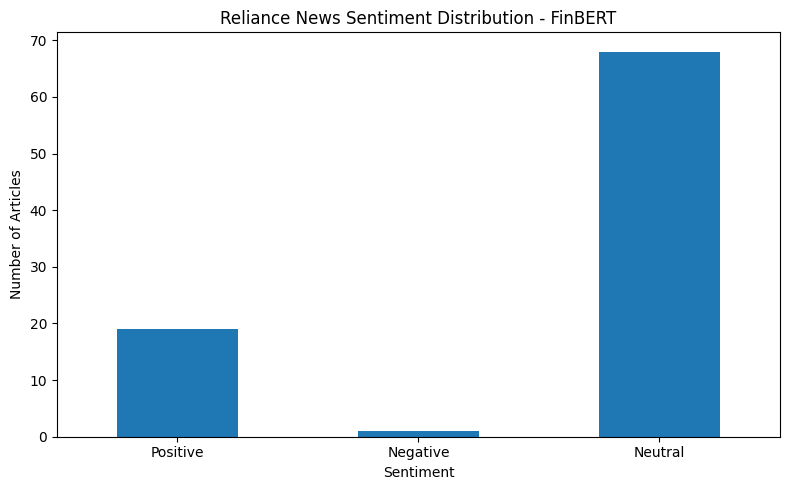


Summary saved: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_sentiment_summary.csv
Chart saved: C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol\moneycontrol_reliance_sentiment_distribution.png

SAMPLE SENTIMENT RESULTS
      Date                                                                                                  Headline Sentiment_Label  Positive_Score  Negative_Score  Neutral_Score  Sentiment_Compound
2017-04-04                       RIL gets green nod for Rs 13,250 cr Dahej unit expansion project - Moneycontrol.com         Neutral        0.382083        0.012909       0.605008            0.369174
2017-07-05                        Reliance Jio to launch 4G VoLTE phone at Rs 500 in July: Report - Moneycontrol.com         Neutral        0.109143        0.034088       0.856770            0.075055
2017-07-21                       Full text: Mukesh Ambani speaks at Reliance Industries' 40th AGM - Moneycontrol.com         Neutral        0.330677  

In [46]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# --------------------------------------------------
# 1. File paths
# --------------------------------------------------
base_path = Path(
    r"C:\Users\Shilpi Chouhan\data\raw\news\moneycontrol"
)

input_file = base_path / "moneycontrol_reliance_first100_clean.csv"

output_file = base_path / "moneycontrol_reliance_sentiment_finbert.csv"
summary_file = base_path / "moneycontrol_reliance_sentiment_summary.csv"
chart_file = base_path / "moneycontrol_reliance_sentiment_distribution.png"

# --------------------------------------------------
# 2. Load dataset
# --------------------------------------------------
df = pd.read_csv(input_file)

required_columns = ["Date", "Headline", "Article_Text"]
missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["Headline"] = df["Headline"].fillna("").astype(str)
df["Article_Text"] = df["Article_Text"].fillna("").astype(str)

if "Snippet" not in df.columns:
    df["Snippet"] = ""
else:
    df["Snippet"] = df["Snippet"].fillna("").astype(str)

print("Records loaded:", len(df))

# --------------------------------------------------
# 3. Load financial sentiment model
# --------------------------------------------------
model_name = "ProsusAI/finbert"

print("Loading FinBERT. First run may download the model...")

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

print("Model loaded successfully.")
print("Device:", device)

# Normalize the model's class names
id2label = {
    int(key): value.lower()
    for key, value in model.config.id2label.items()
}

print("Model labels:", id2label)

# --------------------------------------------------
# 4. Split long text into manageable chunks
# --------------------------------------------------
def split_into_chunks(text, words_per_chunk=180):
    words = str(text).split()

    if not words:
        return [""]

    return [
        " ".join(words[i:i + words_per_chunk])
        for i in range(0, len(words), words_per_chunk)
    ]

# Keep a separate record of every text segment and its article.
segments = []

for article_id, row in df.iterrows():

    # Headline + snippet represent the short-form news signal.
    short_text = (
        row["Headline"].strip()
        + ". "
        + row["Snippet"].strip()
    ).strip()

    segments.append({
        "article_id": article_id,
        "segment_type": "headline",
        "text": short_text
    })

    # Analyze the body in chunks to handle long articles.
    body_chunks = split_into_chunks(row["Article_Text"])

    for chunk in body_chunks:
        segments.append({
            "article_id": article_id,
            "segment_type": "body",
            "text": chunk
        })

print("Total text segments to analyze:", len(segments))

# --------------------------------------------------
# 5. Predict sentiment in batches
# --------------------------------------------------
class_names = ["positive", "negative", "neutral"]
all_probabilities = []

batch_size = 8

for start in range(0, len(segments), batch_size):

    batch = segments[start:start + batch_size]
    texts = [item["text"] for item in batch]

    encoded = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=512,
        return_tensors="pt"
    )

    encoded = {key: value.to(device) for key, value in encoded.items()}

    with torch.no_grad():
        logits = model(**encoded).logits
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()

    for probs in probabilities:
        result = {name: 0.0 for name in class_names}

        for class_id, probability in enumerate(probs):
            raw_label = id2label[class_id]
            normalized_label = raw_label.split("/")[-1].strip().lower()

            if normalized_label in result:
                result[normalized_label] = float(probability)
            else:
                raise ValueError(
                    f"Unexpected FinBERT label: {raw_label}"
                )

        all_probabilities.append(result)

    if (start // batch_size + 1) % 10 == 0:
        print(f"Processed {min(start + batch_size, len(segments))}"
              f" / {len(segments)} segments")

segment_results = pd.DataFrame(all_probabilities)

segments_df = pd.DataFrame(segments)
segments_df = pd.concat(
    [segments_df, segment_results],
    axis=1
)

print("Sentiment predictions completed.")

# --------------------------------------------------
# 6. Aggregate segment predictions per article
# --------------------------------------------------
article_results = []

for article_id in range(len(df)):

    article_segments = segments_df[
        segments_df["article_id"] == article_id
    ]

    headline_scores = article_segments[
        article_segments["segment_type"] == "headline"
    ][class_names].mean()

    body_scores = article_segments[
        article_segments["segment_type"] == "body"
    ][class_names].mean()

    # Combine the short-form headline signal and body signal.
    # These weights are a project choice, not trained parameters.
    combined_scores = 0.40 * headline_scores + 0.60 * body_scores

    combined_scores = combined_scores / combined_scores.sum()

    label = combined_scores.idxmax()

    article_results.append({
        "Sentiment_Label": label.capitalize(),
        "Positive_Score": combined_scores["positive"],
        "Negative_Score": combined_scores["negative"],
        "Neutral_Score": combined_scores["neutral"],
        "Sentiment_Compound": (
            combined_scores["positive"] -
            combined_scores["negative"]
        )
    })

sentiment_df = pd.DataFrame(article_results, index=df.index)

# --------------------------------------------------
# 7. Create final sentiment dataset
# --------------------------------------------------
final_df = pd.concat([df, sentiment_df], axis=1)

final_df.to_csv(output_file, index=False)

print("\nSentiment analysis saved successfully.")
print("Output:", output_file)

# --------------------------------------------------
# 8. Sentiment distribution
# --------------------------------------------------
distribution = (
    final_df["Sentiment_Label"]
    .value_counts()
    .reindex(["Positive", "Negative", "Neutral"], fill_value=0)
)

summary = pd.DataFrame({
    "Sentiment": distribution.index,
    "Article_Count": distribution.values,
    "Percentage": (
        distribution.values / len(final_df) * 100
    ).round(2)
})

summary.to_csv(summary_file, index=False)

print("\nSENTIMENT DISTRIBUTION")
print(summary.to_string(index=False))

# --------------------------------------------------
# 9. Plot sentiment distribution
# --------------------------------------------------
plt.figure(figsize=(8, 5))
distribution.plot(kind="bar")
plt.title("Reliance News Sentiment Distribution - FinBERT")
plt.xlabel("Sentiment")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("\nSummary saved:", summary_file)
print("Chart saved:", chart_file)

# --------------------------------------------------
# 10. Display sample results
# --------------------------------------------------
display_columns = [
    "Date",
    "Headline",
    "Sentiment_Label",
    "Positive_Score",
    "Negative_Score",
    "Neutral_Score",
    "Sentiment_Compound"
]

print("\nSAMPLE SENTIMENT RESULTS")
print(final_df[display_columns].head(10).to_string(index=False))

In [2]:
from pathlib import Path
import pandas as pd
import re
import html
import unicodedata
import time
from urllib.parse import urlparse

import requests
from bs4 import BeautifulSoup

try:
    import trafilatura
except ImportError:
    trafilatura = None

# ============================================================
# 1. FIND PROJECT FOLDER
# ============================================================

PROJECT_NAME = "Stock_Price_Prediction"

possible_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path.home() / "Desktop" / PROJECT_NAME,
    Path.home() / "OneDrive" / "Desktop" / PROJECT_NAME,
    Path.home() / "Documents" / PROJECT_NAME,
    Path.home() / PROJECT_NAME,
]

PROJECT_ROOT = None

for root in possible_roots:
    if root.exists() and root.is_dir():
        if root.name == PROJECT_NAME:
            PROJECT_ROOT = root
            break

        candidate = root / PROJECT_NAME
        if candidate.exists() and candidate.is_dir():
            PROJECT_ROOT = candidate
            break

# Search common locations one level deeper
if PROJECT_ROOT is None:
    search_locations = [
        Path.home() / "Desktop",
        Path.home() / "OneDrive" / "Desktop",
        Path.home() / "Documents",
    ]

    for location in search_locations:
        if location.exists():
            try:
                for candidate in location.glob(PROJECT_NAME):
                    if candidate.is_dir():
                        PROJECT_ROOT = candidate
                        break
            except (PermissionError, OSError):
                pass

        if PROJECT_ROOT is not None:
            break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project folder was not found automatically.\n"
        "Set PROJECT_ROOT manually, for example:\n"
        r'PROJECT_ROOT = Path(r"C:\Users\YourUsername\Desktop'
        r'\Stock_Price_Prediction")'
    )

# ============================================================
# 2. INPUT AND OUTPUT PATHS
# ============================================================

RAW_NEWS_DIR = PROJECT_ROOT / "data" / "raw" / "news"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "news"

MASTER_FILE = OUTPUT_DIR / "reliance_master_news_database.csv"
AUDIT_FILE = OUTPUT_DIR / "reliance_news_file_audit.csv"
REPORT_FILE = OUTPUT_DIR / "reliance_news_quality_report.txt"

# Article fetching settings
FETCH_ARTICLE_TEXT_FROM_URLS = True
MAX_ARTICLES_TO_FETCH = None  # None = try every eligible row; or set e.g. 100 for a test
REQUEST_DELAY_SECONDS = 0.6
REQUEST_TIMEOUT_SECONDS = 15
MIN_ARTICLE_WORDS_TO_KEEP = 50

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not RAW_NEWS_DIR.exists():
    raise FileNotFoundError(
        f"News folder was not found:\n{RAW_NEWS_DIR}\n"
        "Check where your raw news CSV files are stored."
    )

print("Project:", PROJECT_ROOT)
print("Input:", RAW_NEWS_DIR)
print("Output:", OUTPUT_DIR)

# ============================================================
# 3. MASTER DATABASE COLUMNS
# ============================================================

MASTER_COLUMNS = [
    "Company",
    "Date",
    "Publication_Time",
    "Headline",
    "Snippet",
    "Article_Text",
    "Publisher",
    "URL",
    "Source_File",
    "Source_Folder",
    "Source_Type",
    "Article_Text_Word_Count",
    "Article_Text_Status",
    "Headline_Snippet_Status",
]

# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def normalize_column_name(column):
    column = str(column).strip().lower()
    column = re.sub(r"[^a-z0-9]+", "_", column)
    return column.strip("_")


def normalize_columns(df):
    df = df.copy()
    df.columns = [normalize_column_name(c) for c in df.columns]
    return df


def find_column(df, names):
    for name in names:
        key = normalize_column_name(name)
        if key in df.columns:
            return key
    return None


def clean_text(value):
    if pd.isna(value):
        return ""

    value = str(value).strip()

    if value.lower() in {"nan", "none", "null", "nat"}:
        return ""

    return re.sub(r"\s+", " ", value).strip()


def clean_article_text(value):
    """Clean HTML, URLs, control characters, and whitespace."""
    text = clean_text(value)

    if not text:
        return ""

    # Remove scripts and styles
    text = re.sub(
        r"<(script|style)\b[^>]*>.*?</\1>",
        " ",
        text,
        flags=re.IGNORECASE | re.DOTALL,
    )

    # Replace common HTML structural tags with spaces
    text = re.sub(
        r"</?(p|div|br|li|h[1-6]|tr)[^>]*>",
        " ",
        text,
        flags=re.IGNORECASE,
    )

    # Remove remaining HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Decode HTML entities
    text = html.unescape(text)

    # Remove embedded URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove control characters
    text = "".join(
        ch for ch in text
        if ch in "\n\t"
        or unicodedata.category(ch)[0] != "C"
    )

    return re.sub(r"\s+", " ", text).strip()


def looks_like_english(text):
    """Simple English-readability heuristic."""
    if not text or len(text.strip()) < 20:
        return False

    letters = [ch for ch in text if ch.isalpha()]

    if len(letters) < 10:
        return False

    latin_letters = sum(
        1 for ch in letters
        if "LATIN" in unicodedata.name(ch, "")
    )

    return latin_letters / len(letters) >= 0.80


def word_count(text):
    return len(re.findall(r"\b[\w'-]+\b", text))


def is_probably_url(value):
    value = clean_text(value).lower()
    return value.startswith(("http://", "https://", "www."))


def extract_article_from_url(url):
    """Best-effort extraction of readable article text from a source URL."""
    url = clean_text(url)
    if not url or not url.startswith(("http://", "https://")):
        return "", url, "No usable URL"

    headers = {
        "User-Agent": (
            "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
            "AppleWebKit/537.36 (KHTML, like Gecko) "
            "Chrome/131.0.0.0 Safari/537.36"
        ),
        "Accept-Language": "en-US,en;q=0.9",
    }

    try:
        response = requests.get(
            url, headers=headers, timeout=REQUEST_TIMEOUT_SECONDS,
            allow_redirects=True
        )
        final_url = response.url
        response.raise_for_status()

        content_type = response.headers.get("Content-Type", "").lower()
        if "html" not in content_type and "text/" not in content_type:
            return "", final_url, "Skipped non-HTML content"

        article_text = ""
        if trafilatura is not None:
            try:
                article_text = trafilatura.extract(
                    response.text,
                    include_comments=False,
                    include_tables=True,
                    favor_precision=True,
                ) or ""
            except Exception:
                article_text = ""

        if not article_text:
            soup = BeautifulSoup(response.text, "html.parser")
            for tag in soup([
                "script", "style", "noscript", "nav", "footer",
                "header", "aside", "form", "button", "svg"
            ]):
                tag.decompose()

            containers = soup.find_all(["article", "main"])
            best_text = ""
            for container in containers:
                paragraphs = [
                    clean_text(p.get_text(" ", strip=True))
                    for p in container.find_all(["p", "h2", "h3"])
                ]
                candidate = " ".join(p for p in paragraphs if p)
                if word_count(candidate) > word_count(best_text):
                    best_text = candidate

            if not best_text:
                paragraphs = [
                    clean_text(p.get_text(" ", strip=True))
                    for p in soup.find_all("p")
                ]
                best_text = " ".join(
                    p for p in paragraphs if word_count(p) >= 8
                )
            article_text = best_text

        article_text = clean_article_text(article_text)
        lower_text = article_text.lower()
        blocked_phrases = [
            "enable javascript", "access denied", "captcha",
            "please verify you are a human", "subscribe to continue reading",
        ]
        if any(phrase in lower_text for phrase in blocked_phrases):
            return "", final_url, "Blocked/paywall/interstitial page"

        if word_count(article_text) < MIN_ARTICLE_WORDS_TO_KEEP:
            return article_text, final_url, "Fetched but text is short; review source"

        return article_text, final_url, "Fetched article text"

    except requests.exceptions.Timeout:
        return "", url, "Request timed out"
    except requests.exceptions.RequestException as exc:
        return "", url, f"Request failed: {type(exc).__name__}"
    except Exception as exc:
        return "", url, f"Extraction failed: {type(exc).__name__}"


def create_snippet(article_text, headline, max_words=35):
    """
    Create a short excerpt from existing article text.
    Does not invent content if article text is missing.
    """
    article_text = clean_article_text(article_text)
    headline = clean_article_text(headline)

    if not article_text:
        return ""

    # Remove headline from the start if it is repeated there
    if (
        headline
        and article_text[:len(headline)].lower() == headline.lower()
    ):
        article_text = article_text[len(headline):].strip(
            " \t\n:|-"
        )

    if not article_text:
        return ""

    # Prefer a complete first sentence when reasonably short
    sentences = re.split(r"(?<=[.!?])\s+", article_text)
    first_sentence = sentences[0].strip() if sentences else ""

    if 5 <= len(first_sentence.split()) <= max_words:
        snippet = first_sentence
    else:
        snippet = " ".join(article_text.split()[:max_words])

    snippet = snippet.strip()

    # Avoid a snippet that is just the headline
    if (
        headline
        and snippet.lower().strip(" .!?")
        == headline.lower().strip(" .!?")
    ):
        snippet = " ".join(article_text.split()[:max_words])

    return snippet


def detect_source_type(path):
    text = str(path).lower()

    if "moneycontrol" in text:
        return "MoneyControl"
    if "indic" in text and "finance" in text:
        return "Indic-Finance"
    if "sentfin" in text:
        return "SEntFiN"
    if "2026" in text:
        return "2026 News Collection"

    return "Other"


# ============================================================
# 5. IDENTIFY RELIANCE ROWS
# ============================================================

def is_reliance_company(value):
    value = clean_text(value).lower()
    value = re.sub(r"[^a-z0-9]+", " ", value).strip()

    accepted_names = {
        "reliance",
        "reliance industries",
        "reliance industries limited",
        "reliance industries ltd",
        "reliance industries nse",
        "reliance industries bse",
        "reliance industries ltd nse",
        "reliance industries ltd bse",
        "reliance ns",
        "reliance nse",
        "reliance bse",
        "reliance industries nse reliance",
    }

    if value in accepted_names:
        return True

    # Handle common ticker variations
    if re.fullmatch(
        r"reliance(\s+industries)?"
        r"(\s+limited|\s+ltd)?\s+ns",
        value,
    ):
        return True

    if re.fullmatch(
        r"reliance(\s+industries)?"
        r"(\s+limited|\s+ltd)?\s+nse",
        value,
    ):
        return True

    return False


def filename_indicates_reliance(path):
    """Used only when the CSV has no company column."""
    return "reliance" in path.stem.lower()


# ============================================================
# 6. STANDARDIZE EACH CSV FILE
# ============================================================

def standardize_reliance_file(df, csv_path):
    df = normalize_columns(df)

    date_col = find_column(df, [
        "date", "parsed_date", "publication_date",
        "published_date", "published", "datetime", "timestamp",
    ])

    headline_col = find_column(df, [
        "headline", "title", "news_title", "article_title",
    ])

    company_col = find_column(df, [
        "company", "company_name", "ticker",
        "symbol", "stock", "entity", "security",
    ])

    snippet_col = find_column(df, [
        "snippet", "description", "summary",
        "article_description", "short_description",
    ])

    text_col = find_column(df, [
        "article_text", "full_text", "content",
        "article_content", "article_body", "body", "text",
    ])

    publisher_col = find_column(df, [
        "publisher", "source", "publication", "news_source",
    ])

    url_col = find_column(df, [
        "url", "article_url", "link", "source_url",
    ])

    time_col = find_column(df, [
        "publication_time", "published_time", "time",
    ])

    # Date and headline are essential
    if date_col is None or headline_col is None:
        raise ValueError("Date or Headline/Title column is missing.")

    # Do not assume an unidentified CSV contains Reliance news
    if company_col is None and not filename_indicates_reliance(csv_path):
        raise ValueError(
            "No company column and filename does not identify Reliance."
        )

    # Filter Reliance rows when a company field exists
    if company_col is not None:
        company_mask = df[company_col].apply(is_reliance_company)
        df = df.loc[company_mask].copy()

        if df.empty:
            return pd.DataFrame(columns=MASTER_COLUMNS)

    out = pd.DataFrame(index=df.index)
    out["Company"] = "Reliance Industries"

    # Parse dates
    parsed_dates = pd.to_datetime(
        df[date_col], errors="coerce", utc=True
    )

    out["Date"] = parsed_dates.dt.strftime("%Y-%m-%d")
    out["Date"] = out["Date"].fillna("")

    # Preserve the supplied publication time
    if time_col is not None:
        out["Publication_Time"] = df[time_col].apply(clean_text)
    else:
        out["Publication_Time"] = ""

    # Clean headline
    out["Headline"] = df[headline_col].apply(clean_article_text)

    # Clean article text before creating a snippet
    if text_col is not None:
        out["Article_Text"] = df[text_col].apply(clean_article_text)
    else:
        out["Article_Text"] = ""

    # Read existing snippets if available
    if snippet_col is not None:
        out["Snippet"] = df[snippet_col].apply(clean_article_text)
    else:
        out["Snippet"] = ""

    # Generate snippets when missing or identical to headline
    snippet_statuses = []

    for idx in out.index:
        headline = out.at[idx, "Headline"]
        article_text = out.at[idx, "Article_Text"]
        existing_snippet = out.at[idx, "Snippet"]

        headline_key = headline.lower().strip(" .!?")
        snippet_key = existing_snippet.lower().strip(" .!?")

        if not existing_snippet:
            generated = create_snippet(article_text, headline)

            if generated:
                out.at[idx, "Snippet"] = generated
                snippet_statuses.append("Generated from article text")
            else:
                snippet_statuses.append(
                    "Snippet unavailable: article text missing"
                )

        elif snippet_key == headline_key:
            generated = create_snippet(article_text, headline)

            if generated:
                out.at[idx, "Snippet"] = generated
                snippet_statuses.append(
                    "Replaced duplicate headline with article excerpt"
                )
            else:
                out.at[idx, "Snippet"] = ""
                snippet_statuses.append(
                    "Snippet unavailable: article text missing"
                )

        else:
            snippet_statuses.append("Existing snippet retained")

    out["Headline_Snippet_Status"] = snippet_statuses

    # Publisher and URL
    if publisher_col is not None:
        out["Publisher"] = df[publisher_col].apply(clean_text)
    else:
        out["Publisher"] = ""

    if url_col is not None:
        out["URL"] = df[url_col].apply(clean_text)
    else:
        out["URL"] = ""

    # Source tracking
    out["Source_File"] = csv_path.name
    out["Source_Folder"] = str(
        csv_path.parent.relative_to(PROJECT_ROOT)
    )
    out["Source_Type"] = detect_source_type(csv_path)

    # Article text word count
    out["Article_Text_Word_Count"] = (
        out["Article_Text"].apply(word_count)
    )

    def assess_text(text, count):
        if not text:
            return "Missing article text"

        if count < 50:
            return "Short text - review full article"

        if not looks_like_english(text):
            return "English readability uncertain - review"

        return "Readable English-like text - review source"

    out["Article_Text_Status"] = [
        assess_text(text, count)
        for text, count in zip(
            out["Article_Text"],
            out["Article_Text_Word_Count"],
        )
    ]

    # Remove invalid dates and empty headlines
    out = out[
        (out["Date"] != "")
        & (out["Headline"].str.strip() != "")
    ].copy()

    return out[MASTER_COLUMNS]


# ============================================================
# 7. FIND INPUT CSV FILES
# ============================================================

# Only scan the raw news folder, not the processed output folder
csv_files = sorted(
    path for path in RAW_NEWS_DIR.rglob("*.csv")
    if path.resolve() not in {
        MASTER_FILE.resolve(),
        AUDIT_FILE.resolve(),
    }
)

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {RAW_NEWS_DIR}"
    )

print("\nCSV files found:", len(csv_files))


# ============================================================
# 8. PROCESS ALL FILES
# ============================================================

master_parts = []
audit_rows = []

for csv_path in csv_files:
    try:
        try:
            df = pd.read_csv(
                csv_path,
                encoding="utf-8-sig",
                low_memory=False,
            )
        except UnicodeDecodeError:
            df = pd.read_csv(
                csv_path,
                encoding="latin-1",
                low_memory=False,
            )

        if df.empty:
            audit_rows.append({
                "File": csv_path.name,
                "Rows_Read": 0,
                "Reliance_Rows_Kept": 0,
                "Decision": "EXCLUDE",
                "Reason": "Empty CSV",
            })
            continue

        standardized = standardize_reliance_file(df, csv_path)

        if not standardized.empty:
            master_parts.append(standardized)
            decision = "INCLUDED"
            reason = "Reliance records standardized"
        else:
            decision = "EXCLUDE"
            reason = "No valid Reliance records"

        audit_rows.append({
            "File": csv_path.name,
            "Rows_Read": len(df),
            "Reliance_Rows_Kept": len(standardized),
            "Decision": decision,
            "Reason": reason,
        })

        print(
            f"{decision}: {csv_path.name} "
            f"({len(standardized)} Reliance records)"
        )

    except Exception as error:
        audit_rows.append({
            "File": csv_path.name,
            "Rows_Read": 0,
            "Reliance_Rows_Kept": 0,
            "Decision": "EXCLUDE",
            "Reason": str(error),
        })

        print(f"SKIPPED: {csv_path.name} -> {error}")


# ============================================================
# 9. COMBINE AND REMOVE DUPLICATES
# ============================================================

if master_parts:
    master = pd.concat(master_parts, ignore_index=True)
else:
    master = pd.DataFrame(columns=MASTER_COLUMNS)

master = master.reindex(columns=MASTER_COLUMNS)

before_dedup = len(master)

# Duplicate key: company + date + normalized headline
master["_Company_Key"] = master["Company"].str.lower().str.strip()
master["_Date_Key"] = master["Date"].astype(str).str.strip()

master["_Headline_Key"] = (
    master["Headline"]
    .str.lower()
    .str.replace(r"\W+", " ", regex=True)
    .str.strip()
)

master = master.drop_duplicates(
    subset=["_Company_Key", "_Date_Key", "_Headline_Key"],
    keep="first",
).copy()

duplicates_removed = before_dedup - len(master)

master.drop(
    columns=["_Company_Key", "_Date_Key", "_Headline_Key"],
    inplace=True,
)

master = master.sort_values(
    by=["Date", "Headline"]
).reset_index(drop=True)

# Final company check
master = master[
    master["Company"].eq("Reliance Industries")
].copy()


# ============================================================
# 10. FETCH FULL ARTICLE TEXT AND MAKE SNIPPETS DISTINCT
# ============================================================

if not master.empty and FETCH_ARTICLE_TEXT_FROM_URLS:
    # If Article_Text contains a URL, treat it as missing article content.
    master["Article_Text"] = master["Article_Text"].apply(
        lambda value: "" if is_probably_url(value) else clean_article_text(value)
    )

    eligible_indices = [
        idx for idx, row in master.iterrows()
        if row["URL"].strip().startswith(("http://", "https://"))
        and (
            not row["Article_Text"].strip()
            or word_count(row["Article_Text"]) < MIN_ARTICLE_WORDS_TO_KEEP
        )
    ]

    if MAX_ARTICLES_TO_FETCH is not None:
        eligible_indices = eligible_indices[:MAX_ARTICLES_TO_FETCH]

    print(f"\\nEligible articles to fetch: {len(eligible_indices)}")

    fetch_status = {}
    for number, idx in enumerate(eligible_indices, start=1):
        article_text, final_url, status = extract_article_from_url(
            master.at[idx, "URL"]
        )

        # Replace existing text only when fetched text is longer.
        existing_text = clean_article_text(master.at[idx, "Article_Text"])
        if article_text and word_count(article_text) > word_count(existing_text):
            master.at[idx, "Article_Text"] = article_text
            fetch_status[idx] = status
        else:
            fetch_status[idx] = (
                status if not article_text
                else "Existing text retained; fetched text was not longer"
            )

        # Save the final destination if the source redirected to a real page.
        if final_url and final_url.startswith(("http://", "https://")):
            master.at[idx, "URL"] = final_url

        if number % 10 == 0 or number == len(eligible_indices):
            print(f"Article fetch progress: {number}/{len(eligible_indices)}")

        time.sleep(REQUEST_DELAY_SECONDS)

    # Rebuild snippet when missing or identical to headline.
    for idx in master.index:
        headline = clean_article_text(master.at[idx, "Headline"])
        snippet = clean_article_text(master.at[idx, "Snippet"])
        article_text = clean_article_text(master.at[idx, "Article_Text"])

        same_as_headline = (
            snippet and headline
            and snippet.lower().strip(" .!?") == headline.lower().strip(" .!?")
        )

        if not snippet or is_probably_url(snippet) or same_as_headline:
            generated = create_snippet(article_text, headline)
            master.at[idx, "Snippet"] = generated
            if generated:
                master.at[idx, "Headline_Snippet_Status"] = (
                    "Generated from article text; differs from headline"
                )
            else:
                master.at[idx, "Headline_Snippet_Status"] = (
                    "Snippet unavailable: article text unavailable"
                )
        elif snippet and headline and snippet.lower() == headline.lower():
            master.at[idx, "Snippet"] = ""

    # Refresh word counts and text quality status after fetching.
    master["Article_Text_Word_Count"] = master["Article_Text"].apply(word_count)

    def final_text_status(row):
        text = clean_article_text(row["Article_Text"])
        count = word_count(text)
        if not text:
            return fetch_status.get(row.name, "Missing article text")
        if count < MIN_ARTICLE_WORDS_TO_KEEP:
            return fetch_status.get(
                row.name, "Short text - review full article"
            )
        if not looks_like_english(text):
            return "English readability uncertain - review"
        return fetch_status.get(
            row.name, "Readable article text - review source"
        )

    master["Article_Text_Status"] = [
        final_text_status(row) for _, row in master.iterrows()
    ]


# ============================================================
# 11. SAVE MASTER DATABASE AND FILE AUDIT
# ============================================================

master.to_csv(
    MASTER_FILE,
    index=False,
    encoding="utf-8-sig",
)

audit_df = pd.DataFrame(
    audit_rows,
    columns=[
        "File",
        "Rows_Read",
        "Reliance_Rows_Kept",
        "Decision",
        "Reason",
    ],
)

audit_df.to_csv(
    AUDIT_FILE,
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 12. CREATE QUALITY REPORT
# ============================================================

with open(REPORT_FILE, "w", encoding="utf-8") as file:
    file.write("RELIANCE NEWS DATABASE QUALITY REPORT\n")
    file.write("=" * 60 + "\n")
    file.write(f"Project folder: {PROJECT_ROOT}\n")
    file.write(f"Input folder: {RAW_NEWS_DIR}\n")
    file.write(f"CSV files scanned: {len(csv_files)}\n")
    file.write(f"Records before deduplication: {before_dedup}\n")
    file.write(f"Duplicate records removed: {duplicates_removed}\n")
    file.write(f"Final Reliance records: {len(master)}\n\n")

    file.write("NEWS DATE RANGE\n")
    file.write("-" * 60 + "\n")

    if not master.empty:
        file.write(f"Earliest date: {master['Date'].min()}\n")
        file.write(f"Latest date: {master['Date'].max()}\n")
    else:
        file.write("No valid records available.\n")

    file.write("\nARTICLE TEXT QUALITY\n")
    file.write("-" * 60 + "\n")

    if not master.empty:
        for status, count in master[
            "Article_Text_Status"
        ].value_counts().items():
            file.write(f"{status}: {count}\n")

        file.write("\nHEADLINE AND SNIPPET CHECK\n")
        file.write("-" * 60 + "\n")

        for status, count in master[
            "Headline_Snippet_Status"
        ].value_counts().items():
            file.write(f"{status}: {count}\n")

        file.write("\nMISSING FIELD COUNTS\n")
        file.write("-" * 60 + "\n")

        for column in [
            "Date",
            "Publication_Time",
            "Headline",
            "Snippet",
            "Article_Text",
            "Publisher",
            "URL",
        ]:
            missing_count = (
                master[column].fillna("").astype(str).str.strip().eq("")
            ).sum()

            file.write(f"{column}: {missing_count}\n")

    file.write("\nFILE AUDIT\n")
    file.write("-" * 60 + "\n")

    for _, row in audit_df.iterrows():
        file.write(
            f"{row['File']} | {row['Decision']} | "
            f"{row['Reliance_Rows_Kept']} rows | "
            f"{row['Reason']}\n"
        )


# ============================================================
# 13. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("RELIANCE MASTER NEWS DATABASE CREATED")
print("=" * 65)

print("Total CSV files scanned:", len(csv_files))
print("Records before deduplication:", before_dedup)
print("Duplicates removed:", duplicates_removed)
print("Final Reliance records:", len(master))

if not master.empty:
    print("\nNews date range:")
    print("Earliest date:", master["Date"].min())
    print("Latest date:", master["Date"].max())

    print("\nArticle text quality:")
    print(master["Article_Text_Status"].value_counts())

    print("\nHeadline/snippet status:")
    print(master["Headline_Snippet_Status"].value_counts())

    print("\nMissing field counts:")
    for column in [
        "Date",
        "Publication_Time",
        "Headline",
        "Snippet",
        "Article_Text",
        "Publisher",
        "URL",
    ]:
        missing = (
            master[column].fillna("").astype(str).str.strip().eq("")
        ).sum()
        print(f"{column}: {missing}")

print("\nSaved files:")
print("Master database:", MASTER_FILE)
print("Audit report:", AUDIT_FILE)
print("Quality report:", REPORT_FILE)

print("\nPreview:")
display(master.head(10))


Project: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction
Input: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\raw\news
Output: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news

CSV files found: 7
INCLUDED: news_2026_raw.csv (1892 Reliance records)
INCLUDED: news_2026_raw_v2.csv (3347 Reliance records)
INCLUDED: indic-finance.csv (199 Reliance records)
INCLUDED: moneycontrol_reliance_articles.csv (573 Reliance records)
INCLUDED: moneycontrol_reliance_bulk.csv (575 Reliance records)
SKIPPED: SEntFiN.csv -> Date or Headline/Title column is missing.
SKIPPED: sentfin_reliance_tcs.csv -> Date or Headline/Title column is missing.
\nEligible articles to fetch: 4582
Article fetch progress: 10/4582
Article fetch progress: 20/4582
Article fetch progress: 30/4582
Article fetch progress: 40/4582
Article fetch progress: 50/4582
Article fetch progress: 60/4582
Article fetch progress: 70/4582
Article fetch progress: 80/4582
Article fetch progress: 90/4582

,Company,Date,Publication_Time,Headline,Snippet,Article_Text,Publisher,URL,Source_File,Source_Folder,Source_Type,Article_Text_Word_Count,Article_Text_Status,Headline_Snippet_Status
0,Reliance Industries,2016-09-02,,Jio jitters for telecom stocks - Telegraph India,Jio jitters for telecom stocks Telegraph India,,Telegraph India,https://news.google.com/rss/articles/CBMiigFBV...,indic-finance.csv,data\raw\news\indic_finance,Indic-Finance,0,Fetched but text is short; review source,Existing snippet retained
1,Reliance Industries,2017-03-21,2017-03-21 07:00:00,Srichakra Commercials buys 34.44 crore shares ...,Srichakra Commercials buys 34.44 crore shares ...,"On March 20, 2017 Adisesh Enterprises LLP sold...",Moneycontrol.com,https://www.moneycontrol.com/news/business/sto...,moneycontrol_reliance_articles.csv,data\raw\news\moneycontrol,MoneyControl,198,Fetched article text,Existing snippet retained
2,Reliance Industries,2017-03-21,,Vodafone-Idea merger: A telecom giant is born ...,Vodafone-Idea merger: A telecom giant is born ...,,Business Standard,https://news.google.com/rss/articles/CBMi2AFBV...,indic-finance.csv,data\raw\news\indic_finance,Indic-Finance,0,Fetched but text is short; review source,Existing snippet retained
3,Reliance Industries,2017-04-04,2017-04-04 07:00:00,"RIL gets green nod for Rs 13,250 cr Dahej unit...","RIL gets green nod for Rs 13,250 cr Dahej unit...",Reliance Industries Ltd (RIL) has received env...,Moneycontrol.com,https://www.moneycontrol.com/news/business/ril...,moneycontrol_reliance_articles.csv,data\raw\news\moneycontrol,MoneyControl,323,Fetched article text,Existing snippet retained
4,Reliance Industries,2017-04-07,2017-04-07 07:00:00,Reliance Jio pulls Summer Surprise offer: What...,Reliance Jio pulls Summer Surprise offer: What...,Reliance Jio late on Thursday decided to withd...,Moneycontrol.com,https://www.moneycontrol.com/news/business/com...,moneycontrol_reliance_articles.csv,data\raw\news\moneycontrol,MoneyControl,387,Fetched article text,Existing snippet retained
5,Reliance Industries,2017-04-11,2017-04-11 07:00:00,From 'Welcome' to 'Dhan Dhana Dhan': A journey...,From 'Welcome' to 'Dhan Dhana Dhan': A journey...,Reliance Jio offers have rained 'Dhan Dhana Dh...,Moneycontrol.com,https://www.moneycontrol.com/news/business/com...,moneycontrol_reliance_articles.csv,data\raw\news\moneycontrol,MoneyControl,653,Fetched article text,Existing snippet retained
6,Reliance Industries,2017-04-24,2017-04-24 07:00:00,Reliance Industries quarterly result: GRM at 8...,Reliance Industries quarterly result: GRM at 8...,Reliance Industries on Monday reported a good ...,Moneycontrol.com,https://www.moneycontrol.com/news/business/ear...,moneycontrol_reliance_articles.csv,data\raw\news\moneycontrol,MoneyControl,251,Fetched article text,Existing snippet retained
7,Reliance Industries,2017-07-03,2017-07-03 07:00:00,Jio eats into market share of large telcos in ...,Jio eats into market share of large telcos in ...,"Leading telecom majors Bharti Airtel, Vodafone...",Moneycontrol.com,https://www.moneycontrol.com/news/telecom/jio-...,moneycontrol_reliance_articles.csv,data\raw\news\moneycontrol,MoneyControl,304,Fetched article text,Existing snippet retained
8,Reliance Industries,2017-07-11,2017-07-11 07:00:00,The sequel to Dhan Dhana Dhan? Reliance Jio un...,The sequel to Dhan Dhana Dhan? Reliance Jio un...,As Reliance Jio’s ‘dhan dhana dhan’ offer is s...,Moneycontrol.com,https://www.moneycontrol.com/news/business/com...,moneycontrol_reliance_articles.csv,data\raw\news\moneycontrol,MoneyControl,474,Fetched article text,Existing snippet retained
9,Reliance Industries,2017-07-21,2017-07-21 07:00:00,Full text: Mukesh Ambani speaks at Reliance In...,Full text: Mukesh Ambani speaks at Reliance In...,"My Dear Shareowners, A very warm good morning ...",Moneycontrol.com,https://www.moneycontrol.com/news/business/ful...,moneycontrol_reliance_articles.csv,data\raw\news\moneycontrol,MoneyControl,6293,Fetched article text,Existing

In [6]:
from pathlib import Path
import re
import pandas as pd

# ============================================================
# RELIANCE MASTER NEWS DATABASE VERIFICATION
# ============================================================

PROJECT_NAME = "Stock_Price_Prediction"

# OPTION 1: Automatic project folder detection
PROJECT_ROOT = None

# OPTION 2: If automatic detection fails, uncomment and set
# your actual project folder path, for example:
# PROJECT_ROOT = Path(
#     r"C:\Users\YourUsername\Desktop\Stock_Price_Prediction"
# )

# ============================================================
# 1. FIND PROJECT FOLDER
# ============================================================

if PROJECT_ROOT is None:

    current = Path.cwd()

    # Search the current directory and its parents.
    roots = [current, *current.parents]

    # Also check common Windows locations.
    roots.extend([
        Path.home() / "Desktop" / PROJECT_NAME,
        Path.home() / "OneDrive" / "Desktop" / PROJECT_NAME,
        Path.home() / "Documents" / PROJECT_NAME,
        Path.home() / PROJECT_NAME,
    ])

    for root in roots:
        if root.exists() and root.is_dir():

            if root.name == PROJECT_NAME:
                PROJECT_ROOT = root
                break

            candidate = root / PROJECT_NAME

            if candidate.is_dir():
                PROJECT_ROOT = candidate
                break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project folder could not be found automatically.\n"
        "Set PROJECT_ROOT manually in Section 1."
    )

PROJECT_ROOT = Path(PROJECT_ROOT)

NEWS_DIR = PROJECT_ROOT / "data" / "processed" / "news"

MASTER_FILE = NEWS_DIR / "reliance_master_news_database.csv"

REPORT_FILE = NEWS_DIR / "reliance_master_verification_report.txt"

ISSUES_FILE = NEWS_DIR / "reliance_master_verification_issues.csv"

CHECKS_FILE = NEWS_DIR / "reliance_master_verification_checks.csv"

print("Project folder:", PROJECT_ROOT)
print("Master CSV:", MASTER_FILE)

if not MASTER_FILE.exists():
    raise FileNotFoundError(
        f"\nMaster CSV not found:\n{MASTER_FILE}\n\n"
        "Check the file location or set PROJECT_ROOT manually."
    )

# ============================================================
# 2. EXPECTED COLUMNS
# ============================================================

EXPECTED_COLUMNS = [
    "Company",
    "Date",
    "Publication_Time",
    "Headline",
    "Snippet",
    "Article_Text",
    "Publisher",
    "URL",
    "Source_File",
    "Source_Folder",
    "Source_Type",
    "Article_Text_Word_Count",
    "Article_Text_Status",
    "Headline_Snippet_Status",
]

# ============================================================
# 3. HELPER FUNCTIONS
# ============================================================

def clean(value):
    """Convert missing values to empty strings."""
    if pd.isna(value):
        return ""

    value = str(value).strip()

    if value.lower() in {"nan", "none", "null", "nat"}:
        return ""

    return value


def norm(value):
    """Normalize text for comparisons."""
    value = clean(value).lower()
    value = re.sub(r"\s+", " ", value)
    value = re.sub(r"[^\w\s]", "", value)
    return value.strip()


def count_words(value):
    """Count words in article text."""
    return len(re.findall(r"\b[\w'-]+\b", clean(value)))


def is_url_only(value):
    """Check whether the text contains only a URL."""
    return bool(
        re.fullmatch(
            r"(https?://\S+|www\.\S+)",
            clean(value),
            flags=re.I,
        )
    )


def is_possible_error_page(value):
    """Identify common blocked-page or error-page messages."""
    text = clean(value).lower()

    markers = [
        "enable javascript",
        "access denied",
        "captcha",
        "403 forbidden",
        "404 not found",
        "subscribe to read",
        "sign in to continue",
        "verify you are human",
        "robot or human",
    ]

    return any(marker in text for marker in markers)


# ============================================================
# 4. READ THE MASTER CSV
# ============================================================

try:
    df = pd.read_csv(
        MASTER_FILE,
        encoding="utf-8-sig",
        low_memory=False,
    )
except UnicodeDecodeError:
    df = pd.read_csv(
        MASTER_FILE,
        encoding="latin-1",
        low_memory=False,
    )

original_columns = list(df.columns)

# Remove accidental spaces from column names.
df.columns = [str(col).strip() for col in df.columns]

missing_columns = [
    col for col in EXPECTED_COLUMNS
    if col not in df.columns
]

# Add missing columns only in memory so checks can continue.
# The original CSV is not changed.
for col in EXPECTED_COLUMNS:
    if col not in df.columns:
        df[col] = ""

total_rows = len(df)

print("\nCSV successfully loaded.")
print("Total rows:", total_rows)
print("Original column count:", len(original_columns))

# ============================================================
# 5. INITIALIZE CHECKS AND ISSUES
# ============================================================

checks = []
issues = []


def add_check(name, result, details):
    checks.append({
        "Check": name,
        "Result": result,
        "Details": details,
    })


def add_issue(idx, label, details=""):
    row = df.iloc[idx]

    issues.append({
        # Header is row 1, so the first data row is row 2.
        "CSV_Row_Number": idx + 2,
        "Issue": label,
        "Details": details,
        "Company": clean(row.get("Company", "")),
        "Date": clean(row.get("Date", "")),
        "Headline": clean(row.get("Headline", "")),
        "Snippet": clean(row.get("Snippet", "")),
        "Article_Text": clean(row.get("Article_Text", "")),
        "URL": clean(row.get("URL", "")),
    })


add_check(
    "CSV readable and rows present",
    "PASS" if total_rows > 0 else "FAIL",
    f"{total_rows} rows",
)

add_check(
    "Expected columns",
    "PASS" if not missing_columns else "FAIL",
    (
        "All expected columns present"
        if not missing_columns
        else "Missing: " + ", ".join(missing_columns)
    ),
)

# ============================================================
# 6. CHECK REQUIRED FIELDS
# ============================================================

required_fields = [
    "Company",
    "Date",
    "Headline",
    "Snippet",
    "Article_Text",
    "Publisher",
    "URL",
]

for col in required_fields:

    blank_mask = df[col].apply(clean).eq("")
    blank_count = int(blank_mask.sum())

    add_check(
        f"Missing {col}",
        "PASS" if blank_count == 0 else "WARNING",
        f"{blank_count} of {total_rows} rows blank",
    )

    for idx in range(total_rows):
        if blank_mask.iloc[idx]:
            add_issue(idx, f"Missing {col}")

# ============================================================
# 7. CHECK COMPANY NAMES
# ============================================================

companies = df["Company"].apply(norm)

valid_company_names = {
    "reliance",
    "reliance industries",
    "reliance industries limited",
    "reliance industries ltd",
    "reliance ltd",
    "reliance limited",
}

wrong_company = ~companies.isin(valid_company_names)

add_check(
    "Company values",
    "PASS" if not wrong_company.any() else "WARNING",
    f"{int(wrong_company.sum())} rows have unexpected company values",
)

for idx in range(total_rows):
    if wrong_company.iloc[idx]:
        add_issue(
            idx,
            "Unexpected company value",
            clean(df.iloc[idx]["Company"]),
        )

# ============================================================
# 8. CHECK DATE VALIDITY
# ============================================================

dates = pd.to_datetime(
    df["Date"],
    errors="coerce",
)

bad_dates = dates.isna()

add_check(
    "Date validity",
    "PASS" if not bad_dates.any() else "WARNING",
    f"{int(bad_dates.sum())} missing or invalid dates",
)

for idx in range(total_rows):
    if bad_dates.iloc[idx]:
        add_issue(
            idx,
            "Missing or invalid date",
            clean(df.iloc[idx]["Date"]),
        )

# ============================================================
# 9. CHECK DUPLICATES
# ============================================================

# Normalize dates so different representations of the same
# calendar date are compared consistently.
normalized_dates = dates.dt.strftime("%Y-%m-%d").fillna("")

duplicate_data = pd.DataFrame({
    "company": df["Company"].apply(norm),
    "date": normalized_dates,
    "headline": df["Headline"].apply(norm),
})

duplicate_mask = duplicate_data.duplicated(keep="first")

add_check(
    "Duplicate company/date/headline",
    "PASS" if not duplicate_mask.any() else "WARNING",
    f"{int(duplicate_mask.sum())} duplicate rows",
)

for idx in range(total_rows):
    if duplicate_mask.iloc[idx]:
        add_issue(
            idx,
            "Duplicate company/date/headline",
        )

# ============================================================
# 10. CHECK HEADLINE AND SNIPPET
# ============================================================

headlines = df["Headline"].apply(norm)
snippets = df["Snippet"].apply(norm)

identical_mask = (
    headlines.ne("")
    & headlines.eq(snippets)
)

add_check(
    "Headline differs from snippet",
    "PASS" if not identical_mask.any() else "WARNING",
    f"{int(identical_mask.sum())} identical headline/snippet pairs",
)

for idx in range(total_rows):
    if identical_mask.iloc[idx]:
        add_issue(
            idx,
            "Headline and snippet are identical",
        )

# ============================================================
# 11. CHECK ARTICLE TEXT
# ============================================================

article_text = df["Article_Text"].apply(clean)

word_counts = article_text.apply(count_words)

url_only_mask = article_text.apply(is_url_only)
missing_text_mask = article_text.eq("")

short_text_mask = (
    article_text.ne("")
    & word_counts.lt(50)
)

error_page_mask = article_text.apply(is_possible_error_page)

article_checks = [
    (
        "Article_Text is only a URL",
        url_only_mask,
        "Article_Text contains only a URL",
    ),
    (
        "Article_Text missing",
        missing_text_mask,
        "Missing article text",
    ),
    (
        "Article_Text under 50 words",
        short_text_mask,
        "Article text shorter than 50 words",
    ),
    (
        "Possible paywall/block/error page",
        error_page_mask,
        "Possible blocked/error page",
    ),
]

for check_name, mask, issue_name in article_checks:

    issue_count = int(mask.sum())

    add_check(
        check_name,
        "PASS" if issue_count == 0 else "WARNING",
        f"{issue_count} rows",
    )

    for idx in range(total_rows):
        if mask.iloc[idx]:
            add_issue(
                idx,
                issue_name,
                f"Calculated words: {word_counts.iloc[idx]}",
            )

# ============================================================
# 12. CHECK STORED WORD COUNTS
# ============================================================

stored_counts = pd.to_numeric(
    df["Article_Text_Word_Count"],
    errors="coerce",
)

count_mismatch = (
    stored_counts.notna()
    & stored_counts.ne(word_counts)
)

add_check(
    "Stored word count matches text",
    "PASS" if not count_mismatch.any() else "WARNING",
    f"{int(count_mismatch.sum())} mismatches",
)

for idx in range(total_rows):
    if count_mismatch.iloc[idx]:
        add_issue(
            idx,
            "Word count mismatch",
            (
                f"Stored={stored_counts.iloc[idx]}, "
                f"calculated={word_counts.iloc[idx]}"
            ),
        )

# ============================================================
# 13. CHECK URL FORMAT
# ============================================================

urls = df["URL"].apply(clean)

bad_url_mask = (
    urls.ne("")
    & ~urls.str.match(
        r"^https?://",
        case=False,
        na=False,
    )
)

add_check(
    "URL format",
    "PASS" if not bad_url_mask.any() else "WARNING",
    (
        f"{int(bad_url_mask.sum())} non-empty URLs do not start "
        "with http:// or https://"
    ),
)

for idx in range(total_rows):
    if bad_url_mask.iloc[idx]:
        add_issue(
            idx,
            "URL may be invalid",
            urls.iloc[idx],
        )

# ============================================================
# 14. CREATE DATAFRAMES FOR REPORTS
# ============================================================

checks_df = pd.DataFrame(
    checks,
    columns=["Check", "Result", "Details"],
)

issues_df = pd.DataFrame(
    issues,
    columns=[
        "CSV_Row_Number",
        "Issue",
        "Details",
        "Company",
        "Date",
        "Headline",
        "Snippet",
        "Article_Text",
        "URL",
    ],
)

# ============================================================
# 15. SAVE CSV REPORTS
# ============================================================

NEWS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

checks_df.to_csv(
    CHECKS_FILE,
    index=False,
    encoding="utf-8-sig",
)

issues_df.to_csv(
    ISSUES_FILE,
    index=False,
    encoding="utf-8-sig",
)

# ============================================================
# 16. CREATE TEXT REPORT
# ============================================================

valid_dates = dates.dropna()

with open(REPORT_FILE, "w", encoding="utf-8") as file:

    file.write(
        "RELIANCE MASTER NEWS DATABASE VERIFICATION REPORT\n"
    )
    file.write("=" * 70 + "\n")
    file.write(f"Master file: {MASTER_FILE}\n")
    file.write(f"Total rows: {total_rows}\n")
    file.write(
        f"Original columns: {len(original_columns)}\n\n"
    )

    file.write("DATE RANGE\n")
    file.write("-" * 70 + "\n")

    if not valid_dates.empty:
        file.write(
            f"Earliest date: {valid_dates.min().date()}\n"
        )
        file.write(
            f"Latest date: {valid_dates.max().date()}\n"
        )
    else:
        file.write("No valid dates found.\n")

    file.write("\nARTICLE TEXT SUMMARY\n")
    file.write("-" * 70 + "\n")
    file.write(
        f"Rows with article text: "
        f"{int(article_text.ne('').sum())}\n"
    )
    file.write(
        f"Rows missing article text: "
        f"{int(missing_text_mask.sum())}\n"
    )
    file.write(
        f"Rows containing only a URL: "
        f"{int(url_only_mask.sum())}\n"
    )
    file.write(
        f"Rows with fewer than 50 words: "
        f"{int(short_text_mask.sum())}\n"
    )
    file.write(
        f"Possible blocked/error pages: "
        f"{int(error_page_mask.sum())}\n"
    )

    file.write("\nCHECK RESULTS\n")
    file.write("-" * 70 + "\n")

    for _, row in checks_df.iterrows():
        file.write(
            f"[{row['Result']}] {row['Check']}: "
            f"{row['Details']}\n"
        )

    file.write("\nOUTPUT FILES\n")
    file.write("-" * 70 + "\n")
    file.write(f"Checks: {CHECKS_FILE}\n")
    file.write(f"Issues: {ISSUES_FILE}\n")
    file.write(f"Report: {REPORT_FILE}\n")

# ============================================================
# 17. DISPLAY RESULTS IN JUPYTER
# ============================================================

print("\n" + "=" * 70)
print("RELIANCE MASTER DATABASE VERIFICATION COMPLETE")
print("=" * 70)

print("\nMaster file:")
print(MASTER_FILE)

print("\nTotal rows:", total_rows)

if not valid_dates.empty:
    print(
        "Date range:",
        valid_dates.min().date(),
        "to",
        valid_dates.max().date(),
    )

print("\nCHECK RESULTS")
display(checks_df)

print("\nTotal issue records:", len(issues_df))

if not issues_df.empty:
    print("\nIssue counts by type:")
    display(
        issues_df["Issue"]
        .value_counts()
        .rename_axis("Issue")
        .reset_index(name="Count")
    )

    print("\nFirst 20 issue records:")
    display(issues_df.head(20))
else:
    print("No issues detected by these checks.")

print("\nARTICLE TEXT PREVIEW")
preview_columns = [
    "Date",
    "Headline",
    "Snippet",
    "Article_Text_Word_Count",
    "Article_Text_Status",
]

display(df[preview_columns].head(10))

print("\nSAVED REPORTS")
print("1. Verification report:", REPORT_FILE)
print("2. Issue list:", ISSUES_FILE)
print("3. Check results:", CHECKS_FILE)

print(
    "\nImportant: These checks identify potential data-quality "
    "problems. They do not prove that article text is authentic "
    "or complete."
)


Project folder: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction
Master CSV: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\reliance_master_news_database.csv

CSV successfully loaded.
Total rows: 4582
Original column count: 14

RELIANCE MASTER DATABASE VERIFICATION COMPLETE

Master file:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\reliance_master_news_database.csv

Total rows: 4582
Date range: 2016-09-02 to 2026-09-19

CHECK RESULTS


,Check,Result,Details
0,CSV readable and rows present,PASS,4582 rows
1,Expected columns,PASS,All expected columns present
2,Missing Company,PASS,0 of 4582 rows blank
3,Missing Date,PASS,0 of 4582 rows blank
4,Missing Headline,PASS,0 of 4582 rows blank
5,Missing Snippet,WARNING,3 of 4582 rows blank
6,Missing Article_Text,WARNING,4073 of 4582 rows blank
7,Missing Publisher,PASS,0 of 4582 rows blank
8,Missing URL,PASS,0 of 4582 rows blank
9,Company values,PASS,0 rows have unexpected company values



Total issue records: 8154

Issue counts by type:


,Issue,Count
0,Missing Article_Text,4073
1,Missing article text,4073
2,Article text shorter than 50 words,5
3,Missing Snippet,3



First 20 issue records:


,CSV_Row_Number,Issue,Details,Company,Date,Headline,Snippet,Article_Text,URL
0,1738,Missing Snippet,,Reliance Industries,2026-03-24,Huawei responded to sanctions by burning $25B ...,,,https://www.reddit.com/r/IndianStreetBets/comm...
1,1747,Missing Snippet,,Reliance Industries,2026-03-25,Best time to stop an SIP was 10 years ago; the...,,,https://www.reddit.com/r/IndianStreetBets/comm...
2,1811,Missing Snippet,,Reliance Industries,2026-03-27,Reliance 📉 Lower circuit,,,https://www.reddit.com/r/IndianStreetBets/comm...
3,2,Missing Article_Text,,Reliance Industries,2016-09-02,Jio jitters for telecom stocks - Telegraph India,Jio jitters for telecom stocks Telegraph India,,https://news.google.com/rss/articles/CBMiigFBV...
4,4,Missing Article_Text,,Reliance Industries,2017-03-21,Vodafone-Idea merger: A telecom giant is born ...,Vodafone-Idea merger: A telecom giant is born ...,,https://news.google.com/rss/articles/CBMi2AFBV...
5,116,Missing Article_Text,,Reliance Industries,2020-09-01,Brookfield Infrastructure Acquires Indian Tele...,Brookfield Infrastructure Acquires Indian Tele...,,https://news.google.com/rss/articles/CBMimAFBV...
6,283,Missing Article_Text,,Reliance Industries,2023-12-22,"Suzlon, Reliance Power to Vodafone Idea: These...","Suzlon, Reliance Power to Vodafone Idea: These...",,https://news.google.com/rss/articles/CBMikgJBV...
7,361,Missing Article_Text,,Reliance Industries,2024-12-04,Steelman Telecom stock hits 20% upper circuit ...,Steelman Telecom stock hits 20% upper circuit ...,,https://news.google.com/rss/articles/CBMi-AFBV...
8,380,Missing Article_Text,,Reliance Industries,2025-05-27,"Stock market today, 27 May: India VIX up, Sens...","Stock market today, 27 May: India VIX up, Sens...",,https://news.google.com/rss/articles/CBMi6AFBV...
9,396,Missing Article_Text,,Reliance Industries,2025-07-16,Jio BlackRock gets India markets regulator nod...,Jio BlackRock gets India markets regulator nod...,,https://news.google.com/rss/articles/CBMivgFBV...



ARTICLE TEXT PREVIEW


,Date,Headline,Snippet,Article_Text_Word_Count,Article_Text_Status
0,2016-09-02,Jio jitters for telecom stocks - Telegraph India,Jio jitters for telecom stocks Telegraph India,0,Fetched but text is short; review source
1,2017-03-21,Srichakra Commercials buys 34.44 crore shares ...,Srichakra Commercials buys 34.44 crore shares ...,198,Fetched article text
2,2017-03-21,Vodafone-Idea merger: A telecom giant is born ...,Vodafone-Idea merger: A telecom giant is born ...,0,Fetched but text is short; review source
3,2017-04-04,"RIL gets green nod for Rs 13,250 cr Dahej unit...","RIL gets green nod for Rs 13,250 cr Dahej unit...",323,Fetched article text
4,2017-04-07,Reliance Jio pulls Summer Surprise offer: What...,Reliance Jio pulls Summer Surprise offer: What...,387,Fetched article text
5,2017-04-11,From 'Welcome' to 'Dhan Dhana Dhan': A journey...,From 'Welcome' to 'Dhan Dhana Dhan': A journey...,653,Fetched article text
6,2017-04-24,Reliance Industries quarterly result: GRM at 8...,Reliance Industries quarterly result: GRM at 8...,251,Fetched article text
7,2017-07-03,Jio eats into market share of large telcos in ...,Jio eats into market share of large telcos in ...,304,Fetched article text
8,2017-07-11,The sequel to Dhan Dhana Dhan? Reliance Jio un...,The sequel to Dhan Dhana Dhan? Reliance Jio un...,474,Fetched article text
9,2017-07-21,Full text: Mukesh Ambani speaks at Reliance In...,Full text: Mukesh Ambani speaks at Reliance In...,6293,Fetched article text



SAVED REPORTS
1. Verification report: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\reliance_master_verification_report.txt
2. Issue list: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\reliance_master_verification_issues.csv
3. Check results: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\reliance_master_verification_checks.csv

Important: These checks identify potential data-quality problems. They do not prove that article text is authentic or complete.


In [8]:

from pathlib import Path

filename = "reliance_master_news_database.csv"

search_locations = [
    Path.cwd(),
    Path.home() / "Desktop",
    Path.home() / "OneDrive" / "Desktop",
    Path.home() / "Documents",
    Path.home() / "OneDrive" / "Documents",
]

matches = []

for folder in search_locations:
    if folder.exists():
        try:
            matches.extend(folder.rglob(filename))
        except PermissionError:
            pass

# Remove duplicate paths
matches = list(dict.fromkeys(matches))

if matches:
    print("CSV file found:")
    for i, path in enumerate(matches, start=1):
        print(f"{i}. {path}")
else:
    print("CSV not found in the common folders.")
    print("Current notebook folder:", Path.cwd())


CSV file found:
1. C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\reliance_master_news_database.csv


In [9]:
import pandas as pd
from pathlib import Path

file_path = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\reliance_master_news_database.csv"
)

df = pd.read_csv(file_path, low_memory=False)

print("=" * 60)
print("RELIANCE NEWS DATABASE CHECK")
print("=" * 60)

print("Total news rows:", len(df))
print("Missing Article_Text:", df["Article_Text"].isna().sum())
print(
    "Empty Article_Text:",
    df["Article_Text"].fillna("").astype(str).str.strip().eq("").sum()
)

for col in ["Article_Text_Status", "Headline_Snippet_Status"]:
    if col in df.columns:
        print(f"\n{col} distribution:")
        print(df[col].fillna("MISSING").value_counts().to_string())

print("\nAvailable text and URL counts:")
for col in ["Headline", "Snippet", "URL"]:
    if col in df.columns:
        count = df[col].fillna("").astype(str).str.strip().ne("").sum()
        print(f"{col}: {count} non-empty rows")

print("\nSample of rows with missing article text:")
missing = df[
    df["Article_Text"].fillna("").astype(str).str.strip().eq("")
]

cols = [
    c for c in [
        "Date", "Headline", "Snippet", "URL",
        "Article_Text_Status", "Article_Text_Word_Count"
    ] if c in df.columns
]

display(missing[cols].head(10))


RELIANCE NEWS DATABASE CHECK
Total news rows: 4582
Missing Article_Text: 4073
Empty Article_Text: 4073

Article_Text_Status distribution:
Article_Text_Status
Fetched but text is short; review source    4059
Fetched article text                         504
Request failed: ConnectionError               13
Request failed: ChunkedEncodingError           4
Blocked/paywall/interstitial page              1
Request timed out                              1

Headline_Snippet_Status distribution:
Headline_Snippet_Status
Existing snippet retained                             4574
Generated from article text; differs from headline       5
Snippet unavailable: article text unavailable            3

Available text and URL counts:
Headline: 4582 non-empty rows
Snippet: 4579 non-empty rows
URL: 4582 non-empty rows

Sample of rows with missing article text:


,Date,Headline,Snippet,URL,Article_Text_Status,Article_Text_Word_Count
0,2016-09-02,Jio jitters for telecom stocks - Telegraph India,Jio jitters for telecom stocks Telegraph India,https://news.google.com/rss/articles/CBMiigFBV...,Fetched but text is short; review source,0
2,2017-03-21,Vodafone-Idea merger: A telecom giant is born ...,Vodafone-Idea merger: A telecom giant is born ...,https://news.google.com/rss/articles/CBMi2AFBV...,Fetched but text is short; review source,0
114,2020-09-01,Brookfield Infrastructure Acquires Indian Tele...,Brookfield Infrastructure Acquires Indian Tele...,https://news.google.com/rss/articles/CBMimAFBV...,Fetched but text is short; review source,0
281,2023-12-22,"Suzlon, Reliance Power to Vodafone Idea: These...","Suzlon, Reliance Power to Vodafone Idea: These...",https://news.google.com/rss/articles/CBMikgJBV...,Fetched but text is short; review source,0
359,2024-12-04,Steelman Telecom stock hits 20% upper circuit ...,Steelman Telecom stock hits 20% upper circuit ...,https://news.google.com/rss/articles/CBMi-AFBV...,Fetched but text is short; review source,0
378,2025-05-27,"Stock market today, 27 May: India VIX up, Sens...","Stock market today, 27 May: India VIX up, Sens...",https://news.google.com/rss/articles/CBMi6AFBV...,Fetched but text is short; review source,0
394,2025-07-16,Jio BlackRock gets India markets regulator nod...,Jio BlackRock gets India markets regulator nod...,https://news.google.com/rss/articles/CBMivgFBV...,Fetched but text is short; review source,0
397,2025-07-17,Jio BlackRock Nifty Smallcap 250 Index Fund NF...,Jio BlackRock Nifty Smallcap 250 Index Fund NF...,https://news.google.com/rss/articles/CBMi8AFBV...,Fetched but text is short; review source,0
411,2025-08-05,JioBlackRock Nifty Smallcap 250 Index Fund ope...,JioBlackRock Nifty Smallcap 250 Index Fund ope...,https://news.google.com/rss/articles/CBMijgJBV...,Fetched but text is short; review source,0
417,2025-08-19,Reliance Industries shares rally 3%: Three rea...,Reliance Industries shares rally 3%: Three rea...,https://news.google.com/rss/articles/CBMi7wFBV...,Fetched but text is short; review source,0


In [10]:
%pip install -q transformers torch


Note: you may need to restart the kernel to use updated packages.


In [11]:
import pandas as pd
import numpy as np
import torch
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

# --------------------------------------------------
# 1. File paths
# --------------------------------------------------
project = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

input_file = (
    project / "data" / "processed" / "news"
    / "reliance_master_news_database.csv"
)

output_file = (
    project / "data" / "processed" / "news"
    / "reliance_finbert_sentiment_results.csv"
)

checkpoint_file = (
    project / "data" / "processed" / "news"
    / "reliance_finbert_checkpoint.csv"
)

output_file.parent.mkdir(parents=True, exist_ok=True)

if not input_file.exists():
    raise FileNotFoundError(f"Input CSV not found: {input_file}")

df = pd.read_csv(input_file, low_memory=False)
df = df.reset_index(drop=True)

print("Total news records:", len(df))

# --------------------------------------------------
# 2. Check required columns
# --------------------------------------------------
for col in ["Headline", "Snippet", "Article_Text"]:
    if col not in df.columns:
        df[col] = ""

def clean_text(value):
    if pd.isna(value):
        return ""
    return str(value).strip()

# --------------------------------------------------
# 3. Select text for sentiment analysis
# --------------------------------------------------
sentiment_text = []
text_sources = []

for _, row in df.iterrows():
    article = clean_text(row["Article_Text"])
    headline = clean_text(row["Headline"])
    snippet = clean_text(row["Snippet"])

    # Prefer article text if it contains meaningful content.
    # Otherwise, use available headline and snippet.
    if len(article.split()) >= 30:
        text = article
        source = "Article_Text"
    else:
        text = " ".join(
            part for part in [headline, snippet] if part
        ).strip()

        if headline and snippet:
            source = "Headline + Snippet"
        elif headline:
            source = "Headline"
        elif snippet:
            source = "Snippet"
        else:
            source = "Missing"

    sentiment_text.append(text)
    text_sources.append(source)

df["Sentiment_Text_Source"] = text_sources
df["Sentiment_Input_Text"] = sentiment_text

valid_indices = [
    i for i, text in enumerate(sentiment_text) if text.strip()
]

print("Records with usable sentiment text:", len(valid_indices))
print("Records without usable text:", len(df) - len(valid_indices))
print("\nText-source distribution:")
print(df["Sentiment_Text_Source"].value_counts())

# --------------------------------------------------
# 4. Load FinBERT
# --------------------------------------------------
model_name = "ProsusAI/finbert"

device = 0 if torch.cuda.is_available() else -1
print("\nDevice:", "GPU" if device == 0 else "CPU")
print("Loading FinBERT model...")

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

classifier = pipeline(
    "text-classification",
    model=model,
    tokenizer=tokenizer,
    device=device
)

print("FinBERT loaded successfully.")

# --------------------------------------------------
# 5. Initialize sentiment columns
# --------------------------------------------------
score_columns = [
    "Positive_Score",
    "Negative_Score",
    "Neutral_Score"
]

for col in score_columns:
    df[col] = np.nan

df["Sentiment_Label"] = "Missing"
df["Sentiment_Score"] = np.nan

# --------------------------------------------------
# 6. Resume from checkpoint, if available
# --------------------------------------------------
if checkpoint_file.exists():
    previous = pd.read_csv(checkpoint_file)

    if (
        len(previous) == len(df)
        and "Sentiment_Label" in previous.columns
    ):
        for col in score_columns + [
            "Sentiment_Label", "Sentiment_Score"
        ]:
            if col in previous.columns:
                df[col] = previous[col].values

        print("Existing checkpoint found. Resuming completed records.")

completed = set(
    i for i in valid_indices
    if df.loc[i, "Sentiment_Label"] in
    ["positive", "negative", "neutral"]
)

remaining_indices = [
    i for i in valid_indices if i not in completed
]

# --------------------------------------------------
# 7. Predict sentiment in batches
# --------------------------------------------------
BATCH_SIZE = 8

for start in range(0, len(remaining_indices), BATCH_SIZE):
    batch_indices = remaining_indices[start:start + BATCH_SIZE]
    batch_texts = [
        sentiment_text[i] for i in batch_indices
    ]

    try:
        predictions = classifier(
            batch_texts,
            batch_size=BATCH_SIZE,
            truncation=True,
            max_length=512,
            top_k=None
        )

        for idx, result in zip(batch_indices, predictions):
            # Handle output format across Transformers versions.
            if isinstance(result, dict):
                result = [result]

            scores = {
                item["label"].lower(): float(item["score"])
                for item in result
            }

            positive = scores.get("positive", 0.0)
            negative = scores.get("negative", 0.0)
            neutral = scores.get("neutral", 0.0)

            label = max(
                [
                    ("positive", positive),
                    ("negative", negative),
                    ("neutral", neutral)
                ],
                key=lambda item: item[1]
            )[0]

            df.loc[idx, "Positive_Score"] = positive
            df.loc[idx, "Negative_Score"] = negative
            df.loc[idx, "Neutral_Score"] = neutral
            df.loc[idx, "Sentiment_Label"] = label

            # Continuous score: positive probability minus negative.
            df.loc[idx, "Sentiment_Score"] = positive - negative

    except Exception as e:
        print(f"Batch error at record {start}: {e}")
        # Save completed predictions before stopping.
        df.to_csv(checkpoint_file, index=False)
        raise

    # Save a checkpoint after every batch.
    df.to_csv(checkpoint_file, index=False)

    processed = min(start + BATCH_SIZE, len(remaining_indices))
    print(
        f"Processed {processed}/{len(remaining_indices)} "
        f"remaining records"
    )

# --------------------------------------------------
# 8. Save final sentiment dataset
# --------------------------------------------------
df.to_csv(output_file, index=False)

print("\nSentiment analysis completed.")
print("Output saved to:", output_file)

print("\nSentiment distribution:")
print(df["Sentiment_Label"].value_counts())

print("\nAverage sentiment score:",
      round(df["Sentiment_Score"].mean(), 4))

display(
    df[
        [
            "Date", "Headline", "Sentiment_Text_Source",
            "Sentiment_Label", "Positive_Score",
            "Negative_Score", "Neutral_Score",
            "Sentiment_Score"
        ]
    ].head(10)
)


Total news records: 4582
Records with usable sentiment text: 4582
Records without usable text: 0

Text-source distribution:
Sentiment_Text_Source
Headline + Snippet    4075
Article_Text           504
Headline                 3
Name: count, dtype: int64

Device: CPU
Loading FinBERT model...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

FinBERT loaded successfully.
Processed 8/4582 remaining records
Processed 16/4582 remaining records
Processed 24/4582 remaining records
Processed 32/4582 remaining records
Processed 40/4582 remaining records
Processed 48/4582 remaining records
Processed 56/4582 remaining records
Processed 64/4582 remaining records
Processed 72/4582 remaining records
Processed 80/4582 remaining records
Processed 88/4582 remaining records
Processed 96/4582 remaining records
Processed 104/4582 remaining records
Processed 112/4582 remaining records
Processed 120/4582 remaining records
Processed 128/4582 remaining records
Processed 136/4582 remaining records
Processed 144/4582 remaining records
Processed 152/4582 remaining records
Processed 160/4582 remaining records
Processed 168/4582 remaining records
Processed 176/4582 remaining records
Processed 184/4582 remaining records
Processed 192/4582 remaining records
Processed 200/4582 remaining records
Processed 208/4582 remaining records
Processed 216/4582 rem

,Date,Headline,Sentiment_Text_Source,Sentiment_Label,Positive_Score,Negative_Score,Neutral_Score,Sentiment_Score
0,2016-09-02,Jio jitters for telecom stocks - Telegraph India,Headline + Snippet,neutral,0.021772,0.130356,0.847872,-0.108584
1,2017-03-21,Srichakra Commercials buys 34.44 crore shares ...,Article_Text,negative,0.016394,0.664790,0.318816,-0.648397
2,2017-03-21,Vodafone-Idea merger: A telecom giant is born ...,Headline + Snippet,neutral,0.061828,0.015135,0.923037,0.046693
3,2017-04-04,"RIL gets green nod for Rs 13,250 cr Dahej unit...",Article_Text,neutral,0.155048,0.011807,0.833145,0.143241
4,2017-04-07,Reliance Jio pulls Summer Surprise offer: What...,Article_Text,neutral,0.043163,0.270806,0.686031,-0.227642
5,2017-04-11,From 'Welcome' to 'Dhan Dhana Dhan': A journey...,Article_Text,neutral,0.099908,0.013705,0.886388,0.086203
6,2017-04-24,Reliance Industries quarterly result: GRM at 8...,Article_Text,positive,0.843221,0.027904,0.128875,0.815316
7,2017-07-03,Jio eats into market share of large telcos in ...,Article_Text,negative,0.021952,0.942078,0.035970,-0.920126
8,2017-07-11,The sequel to Dhan Dhana Dhan? Reliance Jio un...,Article_Text,neutral,0.428880,0.031782,0.539338,0.397098
9,2017-07-21,Full text: Mukesh Ambani speaks at Reliance In...,Article_Text,neutral,0.455077,0.013604,0.531319,0.441473


In [12]:
import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------
# 1. Load FinBERT output
# ------------------------------------------
project = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

file_path = (
    project / "data" / "processed" / "news"
    / "reliance_finbert_sentiment_results.csv"
)

if not file_path.exists():
    raise FileNotFoundError(
        f"Output file not found: {file_path}\n"
        "First ensure the FinBERT analysis completed successfully."
    )

df = pd.read_csv(file_path, low_memory=False)

print("=" * 55)
print("RELIANCE FINBERT SENTIMENT VERIFICATION")
print("=" * 55)

print("Total news records:", len(df))

# ------------------------------------------
# 2. Check sentiment labels
# ------------------------------------------
print("\nSentiment label distribution:")
print(df["Sentiment_Label"].value_counts(dropna=False))

valid_labels = ["positive", "negative", "neutral"]

valid_predictions = df["Sentiment_Label"].isin(valid_labels)

print("\nSuccessfully classified:", int(valid_predictions.sum()))
print("Missing/unclassified:", int((~valid_predictions).sum()))

# ------------------------------------------
# 3. Check missing sentiment scores
# ------------------------------------------
score_columns = [
    "Positive_Score",
    "Negative_Score",
    "Neutral_Score",
    "Sentiment_Score"
]

print("\nMissing values in sentiment scores:")
print(df[score_columns].isna().sum())

# ------------------------------------------
# 4. Check probability consistency
# ------------------------------------------
prob_cols = [
    "Positive_Score",
    "Negative_Score",
    "Neutral_Score"
]

complete_scores = df[prob_cols].notna().all(axis=1)

df["Probability_Sum"] = df[prob_cols].sum(axis=1)

probability_check = (
    df.loc[complete_scores, "Probability_Sum"]
    .between(0.98, 1.02)
)

print(
    "\nRows whose three probabilities sum approximately to 1:",
    int(probability_check.sum()),
    "out of",
    int(complete_scores.sum())
)

# ------------------------------------------
# 5. Check which text was analyzed
# ------------------------------------------
print("\nText source distribution:")
print(df["Sentiment_Text_Source"].value_counts(dropna=False))

# ------------------------------------------
# 6. Review examples
# ------------------------------------------
columns_to_show = [
    "Date",
    "Headline",
    "Sentiment_Text_Source",
    "Sentiment_Label",
    "Positive_Score",
    "Negative_Score",
    "Neutral_Score",
    "Sentiment_Score"
]

display(df[columns_to_show].head(15))

# ------------------------------------------
# 7. Save verification report
# ------------------------------------------
report_file = (
    project / "data" / "processed" / "news"
    / "reliance_finbert_verification_report.txt"
)

with open(report_file, "w", encoding="utf-8") as f:
    f.write(f"Total records: {len(df)}\n")
    f.write(f"Successfully classified: {int(valid_predictions.sum())}\n")
    f.write(f"Missing/unclassified: {int((~valid_predictions).sum())}\n")
    f.write("\nSentiment distribution:\n")
    f.write(df["Sentiment_Label"].value_counts(dropna=False).to_string())
    f.write("\n\nMissing score values:\n")
    f.write(df[score_columns].isna().sum().to_string())
    f.write("\n\nText source distribution:\n")
    f.write(df["Sentiment_Text_Source"].value_counts(dropna=False).to_string())

print("\nVerification report saved to:")
print(report_file)


RELIANCE FINBERT SENTIMENT VERIFICATION
Total news records: 4582

Sentiment label distribution:
Sentiment_Label
neutral     2965
positive    1086
negative     531
Name: count, dtype: int64

Successfully classified: 4582
Missing/unclassified: 0

Missing values in sentiment scores:
Positive_Score     0
Negative_Score     0
Neutral_Score      0
Sentiment_Score    0
dtype: int64

Rows whose three probabilities sum approximately to 1: 4582 out of 4582

Text source distribution:
Sentiment_Text_Source
Headline + Snippet    4075
Article_Text           504
Headline                 3
Name: count, dtype: int64


,Date,Headline,Sentiment_Text_Source,Sentiment_Label,Positive_Score,Negative_Score,Neutral_Score,Sentiment_Score
0,2016-09-02,Jio jitters for telecom stocks - Telegraph India,Headline + Snippet,neutral,0.021772,0.130356,0.847872,-0.108584
1,2017-03-21,Srichakra Commercials buys 34.44 crore shares ...,Article_Text,negative,0.016394,0.664790,0.318816,-0.648397
2,2017-03-21,Vodafone-Idea merger: A telecom giant is born ...,Headline + Snippet,neutral,0.061828,0.015135,0.923037,0.046693
3,2017-04-04,"RIL gets green nod for Rs 13,250 cr Dahej unit...",Article_Text,neutral,0.155048,0.011807,0.833145,0.143241
4,2017-04-07,Reliance Jio pulls Summer Surprise offer: What...,Article_Text,neutral,0.043163,0.270806,0.686031,-0.227642
5,2017-04-11,From 'Welcome' to 'Dhan Dhana Dhan': A journey...,Article_Text,neutral,0.099908,0.013705,0.886388,0.086203
6,2017-04-24,Reliance Industries quarterly result: GRM at 8...,Article_Text,positive,0.843221,0.027904,0.128875,0.815316
7,2017-07-03,Jio eats into market share of large telcos in ...,Article_Text,negative,0.021952,0.942078,0.035970,-0.920126
8,2017-07-11,The sequel to Dhan Dhana Dhan? Reliance Jio un...,Article_Text,neutral,0.428880,0.031782,0.539338,0.397098
9,2017-07-21,Full text: Mukesh Ambani speaks at Reliance In...,Article_Text,neutral,0.455077,0.013604,0.531319,0.441473



Verification report saved to:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\reliance_finbert_verification_report.txt


In [13]:
import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

input_file = (
    project / "data" / "processed" / "news"
    / "reliance_finbert_sentiment_results.csv"
)

output_file = (
    project / "data" / "processed" / "news"
    / "reliance_daily_sentiment.csv"
)

df = pd.read_csv(input_file, low_memory=False)

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

numeric_columns = [
    "Sentiment_Score",
    "Positive_Score",
    "Negative_Score",
    "Neutral_Score"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Exclude records without a usable date or sentiment prediction.
usable = df.dropna(
    subset=["Date", "Sentiment_Score"]
).copy()

usable["Date"] = usable["Date"].dt.normalize()

daily = (
    usable.groupby("Date")
    .agg(
        Average_Sentiment=("Sentiment_Score", "mean"),
        Average_Positive=("Positive_Score", "mean"),
        Average_Negative=("Negative_Score", "mean"),
        Average_Neutral=("Neutral_Score", "mean"),
        News_Count=("Sentiment_Score", "count")
    )
    .reset_index()
)

daily["Date"] = daily["Date"].dt.strftime("%Y-%m-%d")
daily = daily.sort_values("Date")

daily.to_csv(output_file, index=False)

print("Daily sentiment rows:", len(daily))
print("Date range:", daily["Date"].min(), "to", daily["Date"].max())
print("Saved to:", output_file)

display(daily.head(10))


Daily sentiment rows: 571
Date range: 2016-09-02 to 2026-09-19
Saved to: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\reliance_daily_sentiment.csv


,Date,Average_Sentiment,Average_Positive,Average_Negative,Average_Neutral,News_Count
0,2016-09-02,-0.108584,0.021772,0.130356,0.847872,1
1,2017-03-21,-0.300852,0.039111,0.339963,0.620927,2
2,2017-04-04,0.143241,0.155048,0.011807,0.833145,1
3,2017-04-07,-0.227642,0.043163,0.270806,0.686031,1
4,2017-04-11,0.086203,0.099908,0.013705,0.886388,1
5,2017-04-24,0.815316,0.843221,0.027904,0.128875,1
6,2017-07-03,-0.920126,0.021952,0.942078,0.035970,1
7,2017-07-11,0.397098,0.428880,0.031782,0.539338,1
8,2017-07-21,0.227252,0.243887,0.016635,0.739477,5
9,2017-09-06,0.171078,0.192072,0.020994,0.786935,1


In [14]:
import pandas as pd
import numpy as np
from pathlib import Path

# --------------------------------------------------
# 1. File paths
# --------------------------------------------------
project = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

news_file = (
    project / "data" / "processed" / "news"
    / "reliance_finbert_sentiment_results.csv"
)

daily_file = (
    project / "data" / "processed" / "news"
    / "reliance_daily_sentiment.csv"
)

if not news_file.exists():
    raise FileNotFoundError(f"News sentiment file not found: {news_file}")

if not daily_file.exists():
    raise FileNotFoundError(
        f"Daily sentiment file not found: {daily_file}\n"
        "Run the daily aggregation code first."
    )

news = pd.read_csv(news_file, low_memory=False)
daily = pd.read_csv(daily_file, low_memory=False)

# --------------------------------------------------
# 2. Check date columns
# --------------------------------------------------
news["Date"] = pd.to_datetime(news["Date"], errors="coerce")
daily["Date"] = pd.to_datetime(daily["Date"], errors="coerce")

print("=" * 60)
print("RELIANCE DAILY SENTIMENT DATASET VERIFICATION")
print("=" * 60)

print("\nNEWS-LEVEL DATA")
print("Total news records:", len(news))
print("News records with invalid dates:", news["Date"].isna().sum())

print("\nDAILY DATA")
print("Total daily records:", len(daily))
print("Date range:", daily["Date"].min(), "to", daily["Date"].max())

# --------------------------------------------------
# 3. Check duplicate and invalid dates
# --------------------------------------------------
print("\nDATE CHECKS")
print("Missing dates in daily dataset:", daily["Date"].isna().sum())
print(
    "Duplicate daily dates:",
    daily["Date"].duplicated().sum()
)

# --------------------------------------------------
# 4. Check missing values
# --------------------------------------------------
required_columns = [
    "Average_Sentiment",
    "Average_Positive",
    "Average_Negative",
    "Average_Neutral",
    "News_Count"
]

print("\nMISSING VALUES")
print(daily[required_columns].isna().sum())

# --------------------------------------------------
# 5. Check score ranges
# --------------------------------------------------
score_columns = [
    "Average_Sentiment",
    "Average_Positive",
    "Average_Negative",
    "Average_Neutral"
]

print("\nSCORE RANGES")
print(daily[score_columns].describe())

print(
    "\nSentiment scores outside [-1, 1]:",
    (
        (daily["Average_Sentiment"] < -1) |
        (daily["Average_Sentiment"] > 1)
    ).sum()
)

probability_columns = [
    "Average_Positive",
    "Average_Negative",
    "Average_Neutral"
]

outside_probability_range = (
    (daily[probability_columns] < 0) |
    (daily[probability_columns] > 1)
).any(axis=1)

print(
    "Rows with average probabilities outside [0, 1]:",
    outside_probability_range.sum()
)

# --------------------------------------------------
# 6. Verify article counts
# --------------------------------------------------
valid_news = news.dropna(
    subset=["Date", "Sentiment_Score"]
).copy()

valid_news["Date"] = valid_news["Date"].dt.normalize()

expected_daily = (
    valid_news.groupby("Date")
    .size()
    .rename("Expected_News_Count")
)

actual_daily = daily.set_index(
    daily["Date"].dt.normalize()
)["News_Count"]

count_comparison = pd.concat(
    [expected_daily, actual_daily.rename("Actual_News_Count")],
    axis=1
)

count_comparison["Expected_News_Count"] = (
    count_comparison["Expected_News_Count"].fillna(0)
)

count_comparison["Actual_News_Count"] = (
    count_comparison["Actual_News_Count"].fillna(0)
)

count_comparison["Expected_News_Count"] = (
    count_comparison["Expected_News_Count"].astype(int)
)

count_comparison["Actual_News_Count"] = (
    count_comparison["Actual_News_Count"].astype(int)
)

count_comparison["Match"] = (
    count_comparison["Expected_News_Count"] ==
    count_comparison["Actual_News_Count"]
)

print("\nNEWS COUNT VALIDATION")
print("News records included in aggregation:", len(valid_news))
print("Total daily News_Count:", int(daily["News_Count"].sum()))
print("Dates with matching counts:", int(count_comparison["Match"].sum()))
print("Dates with count mismatches:", int((~count_comparison["Match"]).sum()))

# --------------------------------------------------
# 7. Display daily dataset sample
# --------------------------------------------------
print("\nFIRST 10 DAILY RECORDS")
display(daily.head(10))

print("\nLAST 10 DAILY RECORDS")
display(daily.tail(10))

# --------------------------------------------------
# 8. Save verification report
# --------------------------------------------------
report_file = (
    project / "data" / "processed" / "news"
    / "reliance_daily_sentiment_verification.txt"
)

with open(report_file, "w", encoding="utf-8") as f:
    f.write("RELIANCE DAILY SENTIMENT VERIFICATION\n")
    f.write(f"News records: {len(news)}\n")
    f.write(f"Daily records: {len(daily)}\n")
    f.write(f"Date range: {daily['Date'].min()} to {daily['Date'].max()}\n")
    f.write(f"Duplicate daily dates: {daily['Date'].duplicated().sum()}\n")
    f.write(f"Included news records: {len(valid_news)}\n")
    f.write(f"Sum of daily news counts: {int(daily['News_Count'].sum())}\n")
    f.write(f"Dates with count mismatches: {int((~count_comparison['Match']).sum())}\n")
    f.write("\nMissing values:\n")
    f.write(daily[required_columns].isna().sum().to_string())

print("\nVerification report saved to:")
print(report_file)


RELIANCE DAILY SENTIMENT DATASET VERIFICATION

NEWS-LEVEL DATA
Total news records: 4582
News records with invalid dates: 0

DAILY DATA
Total daily records: 571
Date range: 2016-09-02 00:00:00 to 2026-09-19 00:00:00

DATE CHECKS
Missing dates in daily dataset: 0
Duplicate daily dates: 0

MISSING VALUES
Average_Sentiment    0
Average_Positive     0
Average_Negative     0
Average_Neutral      0
News_Count           0
dtype: int64

SCORE RANGES
       Average_Sentiment  Average_Positive  Average_Negative  Average_Neutral
count         571.000000        571.000000        571.000000       571.000000
mean            0.219481          0.334733          0.115252         0.550015
std             0.376232          0.270135          0.187338         0.273106
min            -0.964144          0.008400          0.006460         0.016243
25%             0.028399          0.122590          0.013011         0.357076
50%             0.172614          0.254594          0.029022         0.612999
75%      

,Date,Average_Sentiment,Average_Positive,Average_Negative,Average_Neutral,News_Count
0,2016-09-02,-0.108584,0.021772,0.130356,0.847872,1
1,2017-03-21,-0.300852,0.039111,0.339963,0.620927,2
2,2017-04-04,0.143241,0.155048,0.011807,0.833145,1
3,2017-04-07,-0.227642,0.043163,0.270806,0.686031,1
4,2017-04-11,0.086203,0.099908,0.013705,0.886388,1
5,2017-04-24,0.815316,0.843221,0.027904,0.128875,1
6,2017-07-03,-0.920126,0.021952,0.942078,0.035970,1
7,2017-07-11,0.397098,0.428880,0.031782,0.539338,1
8,2017-07-21,0.227252,0.243887,0.016635,0.739477,5
9,2017-09-06,0.171078,0.192072,0.020994,0.786935,1



LAST 10 DAILY RECORDS


,Date,Average_Sentiment,Average_Positive,Average_Negative,Average_Neutral,News_Count
561,2026-09-10,-0.034244,0.135294,0.169538,0.695168,25
562,2026-09-11,-0.024083,0.182450,0.206533,0.611017,34
563,2026-09-12,0.199631,0.223740,0.024109,0.752151,5
564,2026-09-13,0.014421,0.051742,0.037320,0.910938,3
565,2026-09-14,0.161936,0.225423,0.063486,0.711091,18
566,2026-09-15,-0.015094,0.125357,0.140451,0.734192,27
567,2026-09-16,0.085748,0.188807,0.103059,0.708134,36
568,2026-09-17,-0.202908,0.071529,0.274437,0.654034,25
569,2026-09-18,0.042937,0.149970,0.107033,0.742997,22
570,2026-09-19,0.022665,0.044937,0.022272,0.932791,4



Verification report saved to:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\reliance_daily_sentiment_verification.txt


Daily records: 571
Date range: 2016-09-02 to 2026-09-19

Monthly summary saved to: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\sentiment_analysis\reliance_monthly_sentiment_summary.csv


,Month,Monthly_Average_Sentiment,Monthly_News_Count,Monthly_Average_Positive,Monthly_Average_Negative,Monthly_Average_Neutral
0,2016-09-01,-0.108584,1.0,0.021772,0.130356,0.847872
1,2017-03-01,-0.300852,2.0,0.039111,0.339963,0.620927
2,2017-04-01,0.204280,4.0,0.285335,0.081055,0.633610
3,2017-07-01,0.087605,7.0,0.238610,0.151005,0.610385
4,2017-09-01,0.171078,1.0,0.192072,0.020994,0.786935
5,2017-12-01,0.299191,2.0,0.319819,0.020628,0.659553
6,2018-01-01,0.649795,3.0,0.656855,0.007061,0.336084
7,2018-03-01,0.771854,1.0,0.778891,0.007036,0.214073
8,2018-04-01,0.702415,1.0,0.840937,0.138522,0.020541
9,2018-06-01,0.839829,1.0,0.846333,0.006503,0.147164


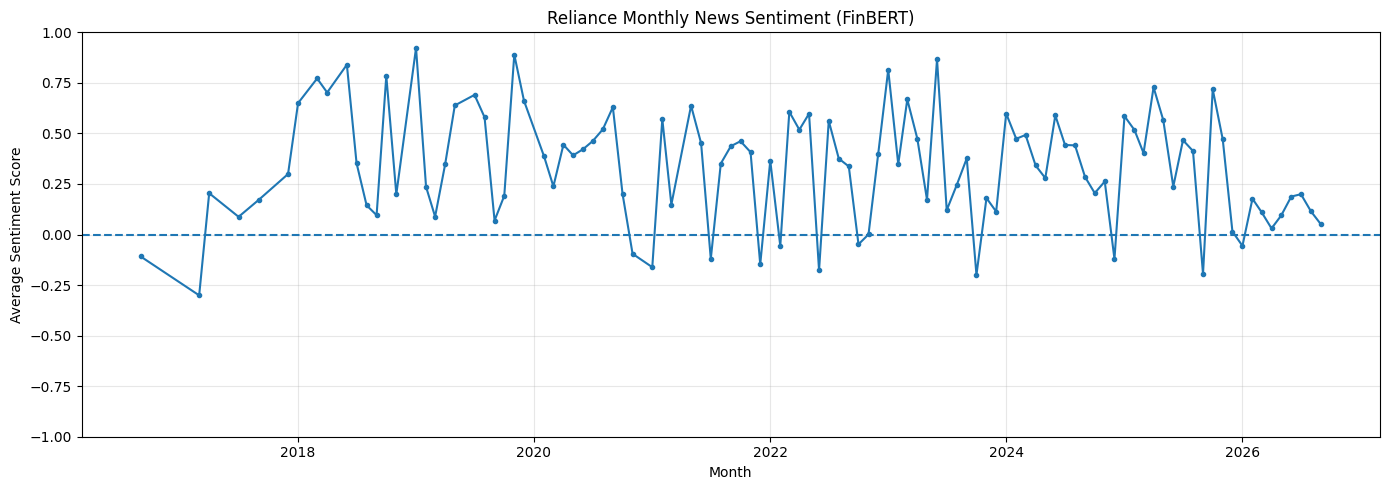

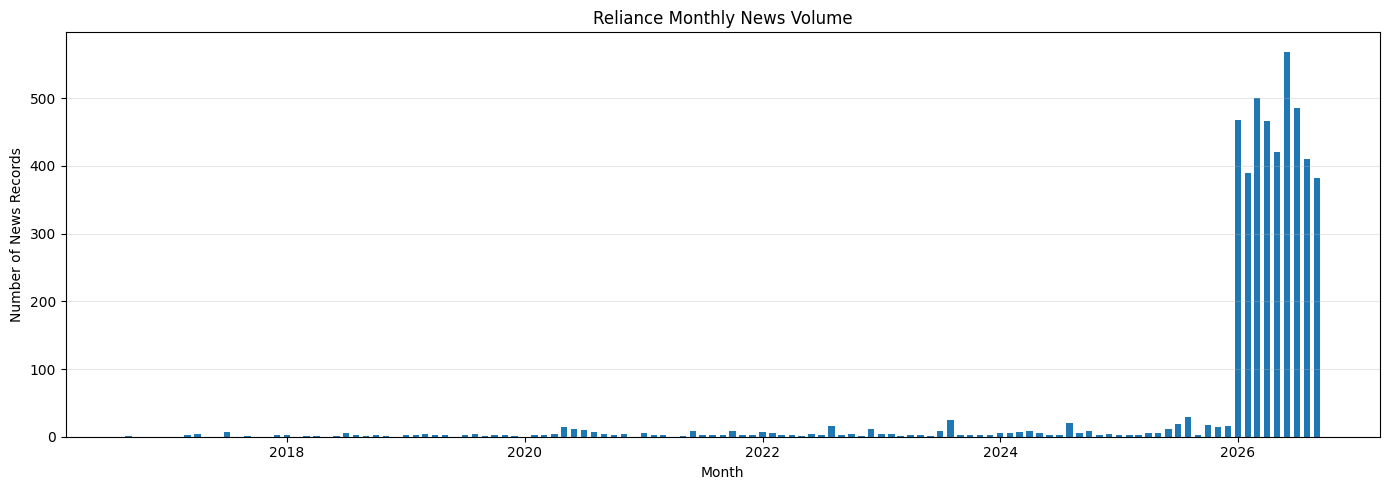


OVERALL SENTIMENT STATISTICS
Average sentiment: 0.2195
Highest daily sentiment: 0.9413
Lowest daily sentiment: -0.9641
Total news records: 4582
Average news records per represented date: 8.02

Monthly news volume statistics:
count    104.000000
mean      44.057692
std      128.167505
min        1.000000
25%        2.000000
50%        3.000000
75%        8.000000
max      569.000000
Name: Monthly_News_Count, dtype: float64

Saved charts and summary in:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\sentiment_analysis


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. Load daily sentiment data
# --------------------------------------------------
project = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

input_file = (
    project / "data" / "processed" / "news"
    / "reliance_daily_sentiment.csv"
)

output_dir = project / "data" / "processed" / "news" / "sentiment_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(input_file)

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in [
    "Average_Sentiment",
    "Average_Positive",
    "Average_Negative",
    "Average_Neutral",
    "News_Count"
]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Date"]).sort_values("Date")

print("Daily records:", len(df))
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

# --------------------------------------------------
# 2. Monthly sentiment and news volume
# --------------------------------------------------
df["Month"] = df["Date"].dt.to_period("M")

monthly = (
    df.groupby("Month")
    .apply(
        lambda group: pd.Series({
            "Monthly_Average_Sentiment": (
                group["Average_Sentiment"] * group["News_Count"]
            ).sum() / group["News_Count"].sum(),
            "Monthly_News_Count": group["News_Count"].sum(),
            "Monthly_Average_Positive": (
                group["Average_Positive"] * group["News_Count"]
            ).sum() / group["News_Count"].sum(),
            "Monthly_Average_Negative": (
                group["Average_Negative"] * group["News_Count"]
            ).sum() / group["News_Count"].sum(),
            "Monthly_Average_Neutral": (
                group["Average_Neutral"] * group["News_Count"]
            ).sum() / group["News_Count"].sum()
        })
    )
    .reset_index()
)

monthly["Month"] = monthly["Month"].dt.to_timestamp()

monthly_file = output_dir / "reliance_monthly_sentiment_summary.csv"
monthly.to_csv(monthly_file, index=False)

print("\nMonthly summary saved to:", monthly_file)
display(monthly.head(10))

# --------------------------------------------------
# 3. Plot monthly average sentiment
# --------------------------------------------------
plt.figure(figsize=(14, 5))
plt.plot(
    monthly["Month"],
    monthly["Monthly_Average_Sentiment"],
    marker="o",
    markersize=3
)
plt.axhline(0, linestyle="--")
plt.title("Reliance Monthly News Sentiment (FinBERT)")
plt.xlabel("Month")
plt.ylabel("Average Sentiment Score")
plt.ylim(-1, 1)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "reliance_monthly_average_sentiment.png",
    dpi=150
)
plt.show()

# --------------------------------------------------
# 4. Plot monthly news volume
# --------------------------------------------------
plt.figure(figsize=(14, 5))
plt.bar(
    monthly["Month"],
    monthly["Monthly_News_Count"],
    width=20
)
plt.title("Reliance Monthly News Volume")
plt.xlabel("Month")
plt.ylabel("Number of News Records")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "reliance_monthly_news_volume.png",
    dpi=150
)
plt.show()

# --------------------------------------------------
# 5. Overall descriptive statistics
# --------------------------------------------------
print("\nOVERALL SENTIMENT STATISTICS")
print("Average sentiment:", round(df["Average_Sentiment"].mean(), 4))
print("Highest daily sentiment:", round(df["Average_Sentiment"].max(), 4))
print("Lowest daily sentiment:", round(df["Average_Sentiment"].min(), 4))
print("Total news records:", int(df["News_Count"].sum()))
print("Average news records per represented date:",
      round(df["News_Count"].mean(), 2))

print("\nMonthly news volume statistics:")
print(monthly["Monthly_News_Count"].describe())

print("\nSaved charts and summary in:")
print(output_dir)


News records loaded: 4592
Daily records loaded: 571


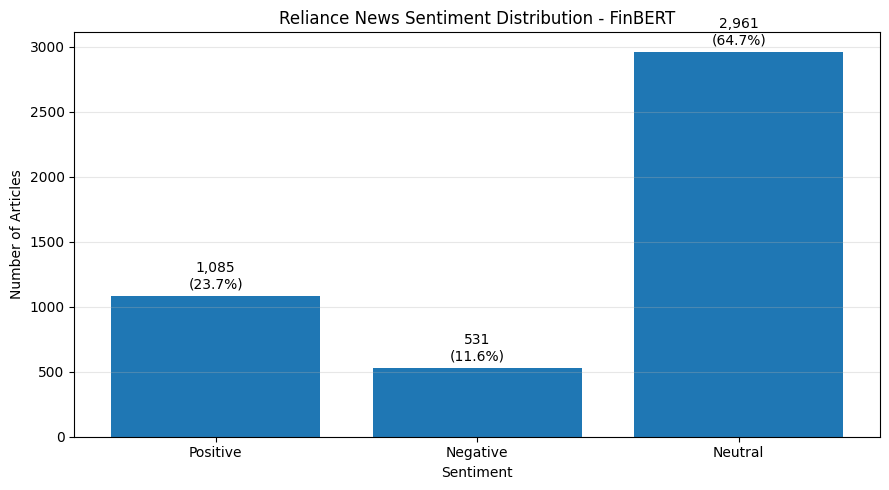

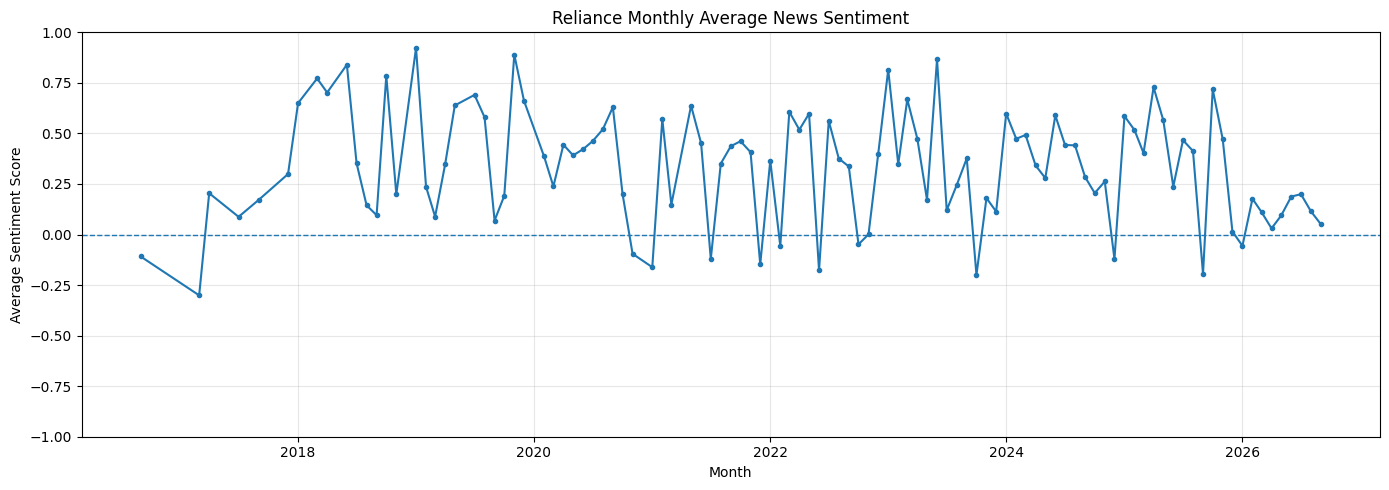

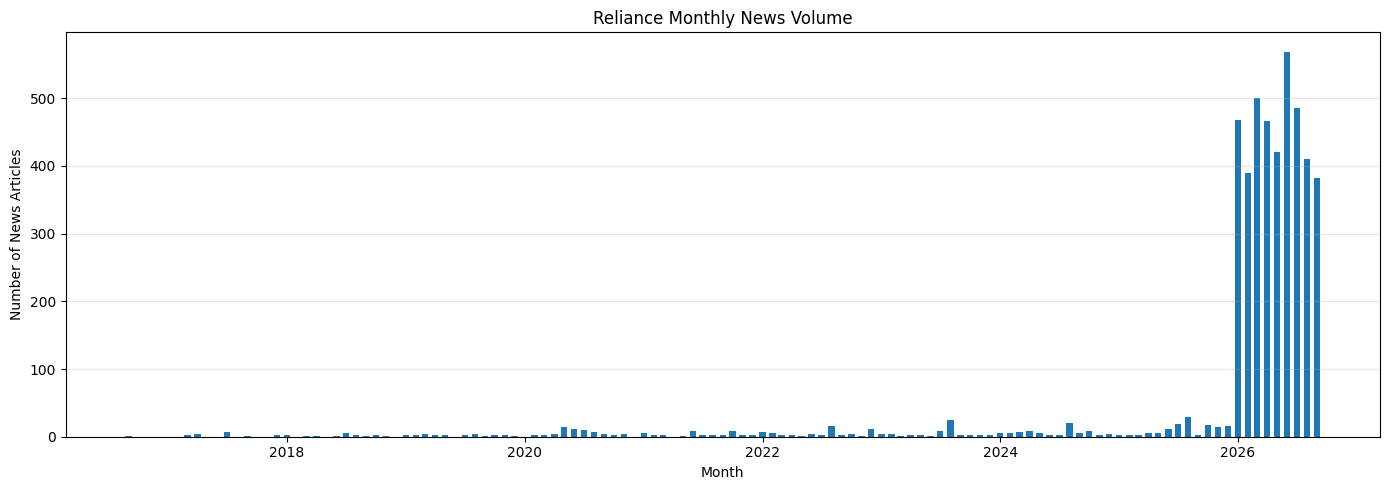

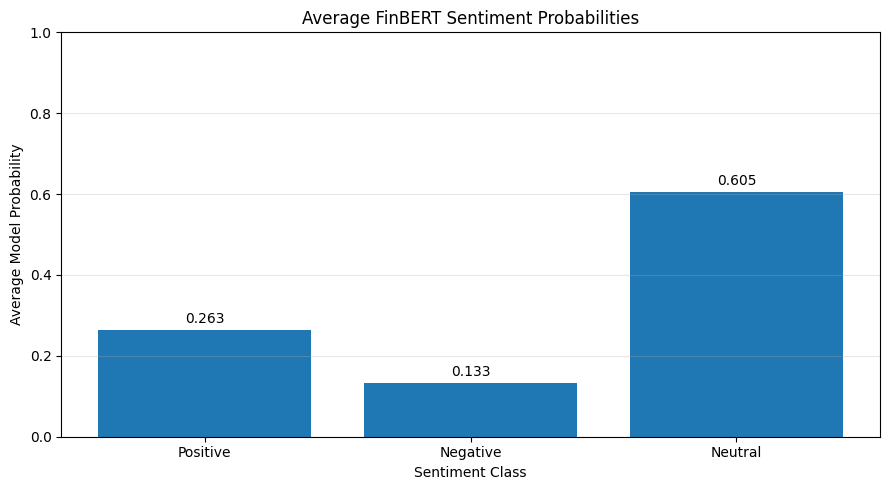

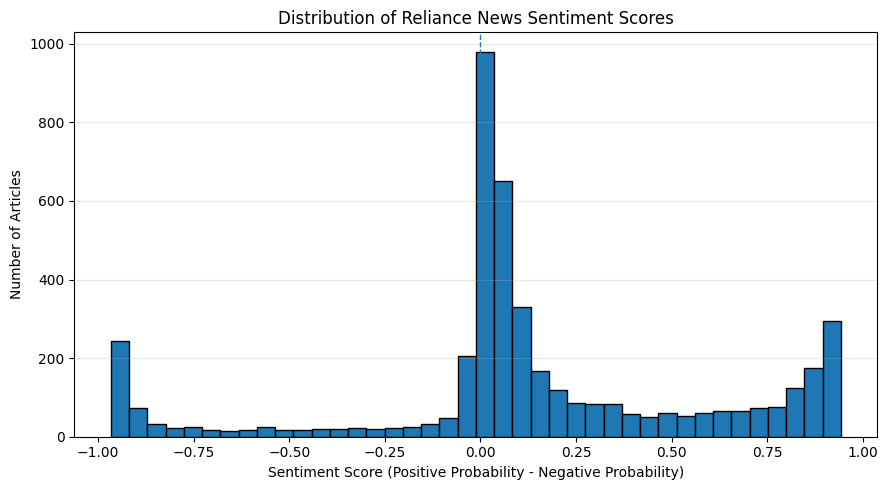


All graphs generated successfully.
Graph and summary folder:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\sentiment_analysis\graphs

Graphs are based on your calculated FinBERT results.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================================
# 1. FILE PATHS
# ==========================================================
PROJECT = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

NEWS_FILE = (
    PROJECT / "data" / "processed" / "news"
    / "reliance_finbert_sentiment_results.csv"
)

DAILY_FILE = (
    PROJECT / "data" / "processed" / "news"
    / "reliance_daily_sentiment.csv"
)

OUTPUT_DIR = (
    PROJECT / "data" / "processed" / "news"
    / "sentiment_analysis" / "graphs"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================================
# 2. LOAD ACTUAL CALCULATED DATA
# ==========================================================
if not NEWS_FILE.exists():
    raise FileNotFoundError(f"File not found: {NEWS_FILE}")

news = pd.read_csv(NEWS_FILE, low_memory=False)

if DAILY_FILE.exists():
    daily = pd.read_csv(DAILY_FILE, low_memory=False)
else:
    print("Daily file not found. Building daily data from news results.")

    news["Date"] = pd.to_datetime(news["Date"], errors="coerce")
    news["Sentiment_Score"] = pd.to_numeric(
        news["Sentiment_Score"], errors="coerce"
    )

    for col in [
        "Positive_Score", "Negative_Score", "Neutral_Score"
    ]:
        news[col] = pd.to_numeric(news[col], errors="coerce")

    valid = news.dropna(
        subset=["Date", "Sentiment_Score"]
    ).copy()

    valid["Date"] = valid["Date"].dt.normalize()

    daily = (
        valid.groupby("Date")
        .agg(
            Average_Sentiment=("Sentiment_Score", "mean"),
            Average_Positive=("Positive_Score", "mean"),
            Average_Negative=("Negative_Score", "mean"),
            Average_Neutral=("Neutral_Score", "mean"),
            News_Count=("Sentiment_Score", "count")
        )
        .reset_index()
    )

news["Date"] = pd.to_datetime(news["Date"], errors="coerce")
daily["Date"] = pd.to_datetime(daily["Date"], errors="coerce")

print("News records loaded:", len(news))
print("Daily records loaded:", len(daily))

# ==========================================================
# 3. GRAPH 1: SENTIMENT DISTRIBUTION
# ==========================================================
sentiment_order = ["positive", "negative", "neutral"]

counts = (
    news["Sentiment_Label"]
    .str.lower()
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)

percentages = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    ["Positive", "Negative", "Neutral"],
    counts.values
)

ax.set_title("Reliance News Sentiment Distribution - FinBERT")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Articles")
ax.grid(axis="y", alpha=0.3)

ax.bar_label(
    bars,
    labels=[
        f"{count:,}\n({pct:.1f}%)"
        for count, pct in zip(counts, percentages)
    ],
    padding=3
)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "01_sentiment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ==========================================================
# 4. GRAPH 2: MONTHLY SENTIMENT TREND
# ==========================================================
daily["Date"] = pd.to_datetime(daily["Date"], errors="coerce")

for col in [
    "Average_Sentiment", "Average_Positive",
    "Average_Negative", "Average_Neutral", "News_Count"
]:
    if col in daily.columns:
        daily[col] = pd.to_numeric(daily[col], errors="coerce")

daily = daily.dropna(subset=["Date"]).copy()
daily["Month"] = daily["Date"].dt.to_period("M")

# Weight each daily average by the number of articles that day.
monthly_rows = daily.dropna(
    subset=["Average_Sentiment", "News_Count"]
).copy()

monthly_rows = monthly_rows[monthly_rows["News_Count"] > 0]

monthly = (
    monthly_rows.groupby("Month")
    .apply(
        lambda g: pd.Series({
            "Average_Sentiment": np.average(
                g["Average_Sentiment"],
                weights=g["News_Count"]
            ),
            "News_Count": g["News_Count"].sum()
        }),
        include_groups=False
    )
    .reset_index()
)

monthly["Month"] = monthly["Month"].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    monthly["Month"],
    monthly["Average_Sentiment"],
    marker="o",
    markersize=3,
    linewidth=1.5
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("Reliance Monthly Average News Sentiment")
ax.set_xlabel("Month")
ax.set_ylabel("Average Sentiment Score")
ax.set_ylim(-1, 1)
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "02_monthly_sentiment_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ==========================================================
# 5. GRAPH 3: MONTHLY NEWS VOLUME
# ==========================================================
fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(
    monthly["Month"],
    monthly["News_Count"],
    width=20
)

ax.set_title("Reliance Monthly News Volume")
ax.set_xlabel("Month")
ax.set_ylabel("Number of News Articles")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "03_monthly_news_volume.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ==========================================================
# 6. GRAPH 4: POSITIVE, NEGATIVE AND NEUTRAL SCORES
# ==========================================================
score_columns = [
    "Positive_Score", "Negative_Score", "Neutral_Score"
]

if all(col in news.columns for col in score_columns):

    scores = news[score_columns].apply(
        pd.to_numeric, errors="coerce"
    ).mean()

    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.bar(
        ["Positive", "Negative", "Neutral"],
        scores.values
    )

    ax.set_title("Average FinBERT Sentiment Probabilities")
    ax.set_xlabel("Sentiment Class")
    ax.set_ylabel("Average Model Probability")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)

    ax.bar_label(
        bars,
        labels=[f"{value:.3f}" for value in scores.values],
        padding=3
    )

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "04_average_sentiment_probabilities.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

# ==========================================================
# 7. GRAPH 5: SENTIMENT SCORE DISTRIBUTION
# ==========================================================
if "Sentiment_Score" in news.columns:

    sentiment_scores = pd.to_numeric(
        news["Sentiment_Score"], errors="coerce"
    ).dropna()

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.hist(
        sentiment_scores,
        bins=40,
        edgecolor="black"
    )

    ax.axvline(0, linestyle="--", linewidth=1)

    ax.set_title("Distribution of Reliance News Sentiment Scores")
    ax.set_xlabel("Sentiment Score (Positive Probability - Negative Probability)")
    ax.set_ylabel("Number of Articles")
    ax.grid(axis="y", alpha=0.3)

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "05_sentiment_score_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

# ==========================================================
# 8. SAVE NUMERICAL SUMMARIES
# ==========================================================
counts_summary = pd.DataFrame({
    "Sentiment": counts.index,
    "Article_Count": counts.values,
    "Percentage": percentages.values
})

counts_summary.to_csv(
    OUTPUT_DIR / "sentiment_distribution_summary.csv",
    index=False
)

monthly.to_csv(
    OUTPUT_DIR / "monthly_sentiment_graph_data.csv",
    index=False
)

print("\nAll graphs generated successfully.")
print("Graph and summary folder:")
print(OUTPUT_DIR)
print("\nGraphs are based on your calculated FinBERT results.")


In [2]:
%pip install vaderSentiment


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
from pathlib import Path
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# ==========================================================
# 1. FILE PATHS
# ==========================================================
PROJECT = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

NEWS_FILE = (
    PROJECT / "data" / "processed" / "news"
    / "reliance_finbert_sentiment_results.csv"
)

OUTPUT_DIR = (
    PROJECT / "data" / "processed" / "news"
)

VADER_NEWS_FILE = (
    OUTPUT_DIR / "reliance_vader_sentiment_results.csv"
)

VADER_DAILY_FILE = (
    OUTPUT_DIR / "reliance_vader_daily_sentiment.csv"
)

if not NEWS_FILE.exists():
    raise FileNotFoundError(
        f"Input file not found: {NEWS_FILE}"
    )

# ==========================================================
# 2. LOAD NEWS DATA
# ==========================================================
df = pd.read_csv(NEWS_FILE, low_memory=False)
df = df.reset_index(drop=True)

print("Total news records:", len(df))

# Ensure necessary columns exist
for col in ["Date", "Headline", "Snippet", "Article_Text"]:
    if col not in df.columns:
        df[col] = ""

def clean_text(value):
    if pd.isna(value):
        return ""
    return str(value).strip()

# ==========================================================
# 3. SELECT TEXT FOR VADER
# ==========================================================
# Reuse FinBERT's exact input text for fair comparison.
if "Sentiment_Input_Text" in df.columns:
    df["VADER_Input_Text"] = (
        df["Sentiment_Input_Text"]
        .fillna("")
        .astype(str)
        .str.strip()
    )
else:
    # Fallback if the saved input-text column is unavailable.
    def select_text(row):
        article = clean_text(row["Article_Text"])
        headline = clean_text(row["Headline"])
        snippet = clean_text(row["Snippet"])

        if len(article.split()) >= 30:
            return article

        return " ".join(
            part for part in [headline, snippet] if part
        ).strip()

    df["VADER_Input_Text"] = df.apply(
        select_text, axis=1
    )

valid_mask = df["VADER_Input_Text"].str.strip().ne("")

print("Records with usable text:", int(valid_mask.sum()))
print("Records without usable text:", int((~valid_mask).sum()))

# ==========================================================
# 4. INITIALIZE VADER
# ==========================================================
analyzer = SentimentIntensityAnalyzer()

# Create output columns
df["VADER_Positive_Score"] = np.nan
df["VADER_Negative_Score"] = np.nan
df["VADER_Neutral_Score"] = np.nan
df["VADER_Compound_Score"] = np.nan
df["VADER_Sentiment_Label"] = "Missing"

# ==========================================================
# 5. CALCULATE SENTIMENT FOR EACH NEWS RECORD
# ==========================================================
valid_indices = df.index[valid_mask]

for count, idx in enumerate(valid_indices, start=1):
    text = df.at[idx, "VADER_Input_Text"]

    scores = analyzer.polarity_scores(text)

    df.at[idx, "VADER_Positive_Score"] = scores["pos"]
    df.at[idx, "VADER_Negative_Score"] = scores["neg"]
    df.at[idx, "VADER_Neutral_Score"] = scores["neu"]
    df.at[idx, "VADER_Compound_Score"] = scores["compound"]

    compound = scores["compound"]

    # Standard VADER compound-score thresholds
    if compound >= 0.05:
        label = "positive"
    elif compound <= -0.05:
        label = "negative"
    else:
        label = "neutral"

    df.at[idx, "VADER_Sentiment_Label"] = label

    if count % 500 == 0:
        print(f"Processed {count}/{len(valid_indices)} records")

# ==========================================================
# 6. SAVE NEWS-LEVEL VADER RESULTS
# ==========================================================
df.to_csv(VADER_NEWS_FILE, index=False)

print("\nVADER analysis completed.")
print("News-level results saved to:")
print(VADER_NEWS_FILE)

print("\nVADER sentiment distribution:")
print(df["VADER_Sentiment_Label"].value_counts())

print("\nMissing VADER compound scores:",
      df["VADER_Compound_Score"].isna().sum())

display(
    df[
        [
            "Date",
            "Headline",
            "VADER_Sentiment_Label",
            "VADER_Positive_Score",
            "VADER_Negative_Score",
            "VADER_Neutral_Score",
            "VADER_Compound_Score"
        ]
    ].head(10)
)

# ==========================================================
# 7. CREATE DAILY VADER SENTIMENT FEATURES
# ==========================================================
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

daily_source = df.dropna(
    subset=["Date", "VADER_Compound_Score"]
).copy()

daily_source["Date"] = daily_source["Date"].dt.normalize()

daily = (
    daily_source.groupby("Date")
    .agg(
        Average_VADER_Sentiment=("VADER_Compound_Score", "mean"),
        Average_VADER_Positive=("VADER_Positive_Score", "mean"),
        Average_VADER_Negative=("VADER_Negative_Score", "mean"),
        Average_VADER_Neutral=("VADER_Neutral_Score", "mean"),
        VADER_News_Count=("VADER_Compound_Score", "count")
    )
    .reset_index()
    .sort_values("Date")
)

daily["Date"] = daily["Date"].dt.strftime("%Y-%m-%d")

daily.to_csv(VADER_DAILY_FILE, index=False)

print("\nDaily VADER dataset created.")
print("Daily records:", len(daily))
print("Date range:", daily["Date"].min(), "to", daily["Date"].max())
print("Saved to:", VADER_DAILY_FILE)

display(daily.head(10))


Total news records: 4592
Records with usable text: 4587
Records without usable text: 5
Processed 500/4587 records
Processed 1000/4587 records
Processed 1500/4587 records
Processed 2000/4587 records
Processed 2500/4587 records
Processed 3000/4587 records
Processed 3500/4587 records
Processed 4000/4587 records
Processed 4500/4587 records

VADER analysis completed.
News-level results saved to:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\reliance_vader_sentiment_results.csv

VADER sentiment distribution:
VADER_Sentiment_Label
positive    2434
neutral     1623
negative     530
Missing        5
Name: count, dtype: int64

Missing VADER compound scores: 5


,Date,Headline,VADER_Sentiment_Label,VADER_Positive_Score,VADER_Negative_Score,VADER_Neutral_Score,VADER_Compound_Score
0,02-09-2016,Jio jitters for telecom stocks - Telegraph India,neutral,0.000,0.000,1.000,0.0000
1,21-03-2017,Srichakra Commercials buys 34.44 crore shares ...,positive,0.163,0.012,0.825,0.9686
2,21-03-2017,Vodafone-Idea merger: A telecom giant is born ...,negative,0.000,0.214,0.786,-0.7783
3,04-04-2017,"RIL gets green nod for Rs 13,250 cr Dahej unit...",positive,0.040,0.000,0.960,0.9042
4,07-04-2017,Reliance Jio pulls Summer Surprise offer: What...,positive,0.127,0.005,0.868,0.9927
5,11-04-2017,From 'Welcome' to 'Dhan Dhana Dhan': A journey...,positive,0.133,0.020,0.848,0.9973
6,24-04-2017,Reliance Industries quarterly result: GRM at 8...,positive,0.129,0.101,0.769,0.4685
7,03-07-2017,Jio eats into market share of large telcos in ...,positive,0.130,0.018,0.852,0.9849
8,11-07-2017,The sequel to Dhan Dhana Dhan? Reliance Jio un...,positive,0.043,0.000,0.957,0.9568
9,21-07-2017,Full text: Mukesh Ambani speaks at Reliance In...,Missing,NaN,NaN,NaN,NaN



Daily VADER dataset created.
Daily records: 220
Date range: 2016-02-09 to 2026-12-09
Saved to: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\reliance_vader_daily_sentiment.csv


,Date,Average_VADER_Sentiment,Average_VADER_Positive,Average_VADER_Negative,Average_VADER_Neutral,VADER_News_Count
0,2016-02-09,0.00000,0.0000,0.0000,1.000,1
1,2017-03-07,0.98490,0.1300,0.0180,0.852,1
2,2017-04-04,0.90420,0.0400,0.0000,0.960,1
3,2017-06-09,0.99560,0.2230,0.0080,0.770,1
4,2017-07-04,0.99270,0.1270,0.0050,0.868,1
5,2017-11-04,0.99730,0.1330,0.0200,0.848,1
6,2017-11-07,0.95680,0.0430,0.0000,0.957,1
7,2018-02-01,0.99100,0.0945,0.0040,0.901,2
8,2018-05-07,0.97756,0.0974,0.0076,0.895,5
9,2018-07-07,0.98990,0.0990,0.0130,0.888,1


In [4]:
import pandas as pd
import numpy as np
from pathlib import Path

# --------------------------------------------------
# 1. File paths
# --------------------------------------------------
PROJECT = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

NEWS_FILE = (
    PROJECT / "data" / "processed" / "news"
    / "reliance_vader_sentiment_results.csv"
)

DAILY_FILE = (
    PROJECT / "data" / "processed" / "news"
    / "reliance_vader_daily_sentiment.csv"
)

if not NEWS_FILE.exists() or not DAILY_FILE.exists():
    raise FileNotFoundError(
        "VADER output files not found. Run the VADER program first."
    )

news = pd.read_csv(NEWS_FILE, low_memory=False)
daily = pd.read_csv(DAILY_FILE, low_memory=False)

# --------------------------------------------------
# 2. News-level verification
# --------------------------------------------------
print("=" * 55)
print("VADER NEWS-LEVEL VERIFICATION")
print("=" * 55)

print("Total news records:", len(news))
print("\nSentiment label distribution:")
print(news["VADER_Sentiment_Label"].value_counts(dropna=False))

score_cols = [
    "VADER_Positive_Score",
    "VADER_Negative_Score",
    "VADER_Neutral_Score",
    "VADER_Compound_Score"
]

print("\nMissing values in VADER scores:")
print(news[score_cols].isna().sum())

print("\nCompound score range:")
print(news["VADER_Compound_Score"].describe())

valid_compound = news["VADER_Compound_Score"].dropna()

print(
    "Compound scores outside [-1, 1]:",
    ((valid_compound < -1) | (valid_compound > 1)).sum()
)

# --------------------------------------------------
# 3. Daily-level verification
# --------------------------------------------------
daily["Date"] = pd.to_datetime(daily["Date"], errors="coerce")

print("\n" + "=" * 55)
print("VADER DAILY DATASET VERIFICATION")
print("=" * 55)

print("Daily records:", len(daily))
print("Date range:", daily["Date"].min(), "to", daily["Date"].max())
print("Missing dates:", daily["Date"].isna().sum())
print("Duplicate dates:", daily["Date"].duplicated().sum())

daily_cols = [
    "Average_VADER_Sentiment",
    "Average_VADER_Positive",
    "Average_VADER_Negative",
    "Average_VADER_Neutral",
    "VADER_News_Count"
]

print("\nMissing values in daily features:")
print(daily[daily_cols].isna().sum())

# --------------------------------------------------
# 4. Validate daily article counts
# --------------------------------------------------
news["Date"] = pd.to_datetime(news["Date"], errors="coerce")

valid_news = news.dropna(
    subset=["Date", "VADER_Compound_Score"]
).copy()

valid_news["Date"] = valid_news["Date"].dt.normalize()

expected = valid_news.groupby("Date").size()

actual = (
    daily.assign(Date=daily["Date"].dt.normalize())
    .set_index("Date")["VADER_News_Count"]
)

check = pd.concat(
    [
        expected.rename("Expected_Count"),
        actual.rename("Daily_Count")
    ],
    axis=1
).fillna(0)

check["Match"] = (
    check["Expected_Count"].astype(int) ==
    check["Daily_Count"].astype(int)
)

print("\nNews records with usable dates and VADER scores:",
      len(valid_news))
print("Sum of daily VADER news counts:",
      int(daily["VADER_News_Count"].sum()))
print("Dates with matching article counts:",
      int(check["Match"].sum()))
print("Dates with count mismatches:",
      int((~check["Match"]).sum()))

# --------------------------------------------------
# 5. Preview and preserve files
# --------------------------------------------------
print("\nSample VADER predictions:")
display(
    news[
        [
            "Date", "Headline",
            "VADER_Sentiment_Label",
            "VADER_Compound_Score"
        ]
    ].head(10)
)

print("\nSample daily VADER features:")
display(daily.head(10))

print("\nVerification complete. No files were modified.")


VADER NEWS-LEVEL VERIFICATION
Total news records: 4592

Sentiment label distribution:
VADER_Sentiment_Label
positive    2434
neutral     1623
negative     530
Missing        5
Name: count, dtype: int64

Missing values in VADER scores:
VADER_Positive_Score    5
VADER_Negative_Score    5
VADER_Neutral_Score     5
VADER_Compound_Score    5
dtype: int64

Compound score range:
count    4587.000000
mean        0.305274
std         0.495910
min        -0.999000
25%         0.000000
50%         0.296000
75%         0.737750
max         0.999800
Name: VADER_Compound_Score, dtype: float64
Compound scores outside [-1, 1]: 0

VADER DAILY DATASET VERIFICATION
Daily records: 220
Date range: 2016-02-09 00:00:00 to 2026-12-09 00:00:00
Missing dates: 0
Duplicate dates: 0

Missing values in daily features:
Average_VADER_Sentiment    0
Average_VADER_Positive     0
Average_VADER_Negative     0
Average_VADER_Neutral      0
VADER_News_Count           0
dtype: int64

News records with usable dates and VADER 

,Date,Headline,VADER_Sentiment_Label,VADER_Compound_Score
0,2016-02-09,Jio jitters for telecom stocks - Telegraph India,neutral,0.0000
1,NaT,Srichakra Commercials buys 34.44 crore shares ...,positive,0.9686
2,NaT,Vodafone-Idea merger: A telecom giant is born ...,negative,-0.7783
3,2017-04-04,"RIL gets green nod for Rs 13,250 cr Dahej unit...",positive,0.9042
4,2017-07-04,Reliance Jio pulls Summer Surprise offer: What...,positive,0.9927
5,2017-11-04,From 'Welcome' to 'Dhan Dhana Dhan': A journey...,positive,0.9973
6,NaT,Reliance Industries quarterly result: GRM at 8...,positive,0.4685
7,2017-03-07,Jio eats into market share of large telcos in ...,positive,0.9849
8,2017-11-07,The sequel to Dhan Dhana Dhan? Reliance Jio un...,positive,0.9568
9,NaT,Full text: Mukesh Ambani speaks at Reliance In...,Missing,NaN



Sample daily VADER features:


,Date,Average_VADER_Sentiment,Average_VADER_Positive,Average_VADER_Negative,Average_VADER_Neutral,VADER_News_Count
0,2016-02-09,0.00000,0.0000,0.0000,1.000,1
1,2017-03-07,0.98490,0.1300,0.0180,0.852,1
2,2017-04-04,0.90420,0.0400,0.0000,0.960,1
3,2017-06-09,0.99560,0.2230,0.0080,0.770,1
4,2017-07-04,0.99270,0.1270,0.0050,0.868,1
5,2017-11-04,0.99730,0.1330,0.0200,0.848,1
6,2017-11-07,0.95680,0.0430,0.0000,0.957,1
7,2018-02-01,0.99100,0.0945,0.0040,0.901,2
8,2018-05-07,0.97756,0.0974,0.0076,0.895,5
9,2018-07-07,0.98990,0.0990,0.0130,0.888,1



Verification complete. No files were modified.


In [5]:
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# 1. File paths (read-only diagnostic)
# --------------------------------------------------
BASE_DIR = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

news_file = BASE_DIR / "data" / "processed" / "news" / "reliance_master_news_database.csv"
vader_file = BASE_DIR / "data" / "processed" / "news" / "reliance_vader_sentiment_results.csv"
daily_file = BASE_DIR / "data" / "processed" / "news" / "reliance_vader_daily_sentiment.csv"

news = pd.read_csv(news_file, low_memory=False)
vader = pd.read_csv(vader_file, low_memory=False)
daily = pd.read_csv(daily_file, low_memory=False)

TODAY = pd.Timestamp("2026-10-12")

print("=" * 65)
print("1. FILE SIZES AND DATE COLUMNS")
print("=" * 65)

for name, df in [
    ("Original news", news),
    ("VADER news-level", vader),
    ("VADER daily", daily)
]:
    print(f"\n{name}: {len(df):,} rows")
    print("Columns:", df.columns.tolist())
    print("Date column present:", "Date" in df.columns)

# --------------------------------------------------
# 2. Check missing dates and VADER scores
# --------------------------------------------------
print("\n" + "=" * 65)
print("2. MISSING VALUES AND USABLE RECORD COUNTS")
print("=" * 65)

if "Date" not in vader.columns:
    raise ValueError("No 'Date' column found in the VADER results.")

vader["Date_Original"] = vader["Date"].astype("string").str.strip()

# Parse dates both ways to identify ambiguous date formats
vader["Date_Parsed_Default"] = pd.to_datetime(
    vader["Date_Original"], errors="coerce"
)
vader["Date_Parsed_DayFirst"] = pd.to_datetime(
    vader["Date_Original"], errors="coerce", dayfirst=True
)

score_cols = [
    "VADER_Positive_Score",
    "VADER_Negative_Score",
    "VADER_Neutral_Score",
    "VADER_Compound_Score"
]

for col in score_cols:
    if col in vader.columns:
        vader[col] = pd.to_numeric(vader[col], errors="coerce")

score_missing = vader[score_cols].isna().any(axis=1)

print("Total VADER records:", len(vader))
print("Blank original dates:", vader["Date_Original"].isna().sum()
      + vader["Date_Original"].eq("").sum())
print("Dates not parsed (default):",
      vader["Date_Parsed_Default"].isna().sum())
print("Dates not parsed (day-first):",
      vader["Date_Parsed_DayFirst"].isna().sum())
print("Records with at least one missing VADER score:", score_missing.sum())

# Reproduce the likely daily-aggregation filter
usable_default = (
    vader["Date_Parsed_Default"].notna() & ~score_missing
)
usable_dayfirst = (
    vader["Date_Parsed_DayFirst"].notna() & ~score_missing
)

print("\nUsable records using default parsing:", usable_default.sum())
print("Usable records using day-first parsing:", usable_dayfirst.sum())
print("Difference between parsing methods:",
      (usable_default != usable_dayfirst).sum())

# --------------------------------------------------
# 3. Inspect future dates
# --------------------------------------------------
print("\n" + "=" * 65)
print("3. FUTURE-DATED NEWS RECORDS")
print("=" * 65)

for label, col in [
    ("Default parsing", "Date_Parsed_Default"),
    ("Day-first parsing", "Date_Parsed_DayFirst")
]:
    future = vader[vader[col] > TODAY]
    print(f"\n{label}: {len(future)} records after {TODAY.date()}")
    if len(future):
        display_cols = [
            c for c in [
                "Date_Original", "Company", "Headline",
                "Publication_Time", "Publisher", "URL"
            ] if c in future.columns
        ]
        print(f"Examples using {label}:")
        print(future[display_cols].head(15).to_string(index=False))

# --------------------------------------------------
# 4. Check whether the date formats are ambiguous
# --------------------------------------------------
print("\n" + "=" * 65)
print("4. DATES PARSED DIFFERENTLY")
print("=" * 65)

different = (
    vader["Date_Parsed_Default"].notna()
    & vader["Date_Parsed_DayFirst"].notna()
    & (
        vader["Date_Parsed_Default"].dt.normalize()
        != vader["Date_Parsed_DayFirst"].dt.normalize()
    )
)

print("Records whose dates differ by parsing method:", different.sum())

if different.any():
    cols = [
        c for c in [
            "Date_Original", "Date_Parsed_Default",
            "Date_Parsed_DayFirst", "Headline", "URL"
        ] if c in vader.columns
    ]
    print(vader.loc[different, cols].head(20).to_string(index=False))

# --------------------------------------------------
# 5. Compare daily counts with source records
# --------------------------------------------------
print("\n" + "=" * 65)
print("5. DAILY DATASET CHECK")
print("=" * 65)

print("Daily rows:", len(daily))
print("Daily columns:", daily.columns.tolist())

if "Date" in daily.columns:
    daily["Date_Check"] = pd.to_datetime(
        daily["Date"], errors="coerce"
    ).dt.normalize()

    print("Daily date minimum:", daily["Date_Check"].min())
    print("Daily date maximum:", daily["Date_Check"].max())
    print("Daily dates after today:",
          (daily["Date_Check"] > TODAY).sum())

    if "VADER_News_Count" in daily.columns:
        print("Sum of daily VADER_News_Count:",
              pd.to_numeric(
                  daily["VADER_News_Count"], errors="coerce"
              ).sum())

print("\nDiagnostic complete. No CSV files were modified.")


1. FILE SIZES AND DATE COLUMNS

Original news: 4,582 rows
Columns: ['Company', 'Date', 'Publication_Time', 'Headline', 'Snippet', 'Article_Text', 'Publisher', 'URL', 'Source_File', 'Source_Folder', 'Source_Type', 'Article_Text_Word_Count', 'Article_Text_Status', 'Headline_Snippet_Status']
Date column present: True

VADER news-level: 4,592 rows
Columns: ['Company', 'Date', 'Publication_Time', 'Headline', 'Snippet', 'Article_Text', 'Publisher', 'URL', 'Source_File', 'Source_Folder', 'Source_Type', 'Article_Text_Word_Count', 'Article_Text_Status', 'Headline_Snippet_Status', 'Sentiment_Text_Source', 'Sentiment_Input_Text', 'Positive_Score', 'Negative_Score', 'Neutral_Score', 'Sentiment_Label', 'Sentiment_Score', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36', 'Unnamed: 37', 'Unnamed: 38', 'Unnamed: 39

In [6]:
import pandas as pd
from pathlib import Path

file_path = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
    r"\data\processed\news\reliance_vader_sentiment_results.csv"
)

df = pd.read_csv(file_path, low_memory=False)

print("FIRST 30 RAW DATE VALUES")
print(df["Date"].head(30).to_string(index=False))

print("\nSAMPLE DATES THAT DEFAULT PARSING FAILED TO READ")
raw_dates = df["Date"].astype("string").str.strip()

default_dates = pd.to_datetime(raw_dates, errors="coerce")
failed = df.loc[default_dates.isna(), ["Date"]]

print(failed.head(30).to_string(index=False))

print("\nSAMPLE DATES THAT DAY-FIRST PARSING FAILED TO READ")
dayfirst_dates = pd.to_datetime(
    raw_dates, errors="coerce", dayfirst=True
)

failed_dayfirst = df.loc[dayfirst_dates.isna(), ["Date"]]
print(failed_dayfirst.head(20).to_string(index=False))

print("\nFUTURE DATES USING DAY-FIRST PARSING")
parsed = pd.to_datetime(
    raw_dates, errors="coerce", dayfirst=True
)

future = df.loc[
    parsed > pd.Timestamp("2026-10-12"),
    ["Date"] + [
        col for col in ["Company", "Headline", "URL"]
        if col in df.columns
    ]
]

print("Future-dated records:", len(future))
print(future.head(30).to_string(index=False))


FIRST 30 RAW DATE VALUES
                                        02-09-2016
                                        21-03-2017
                                        21-03-2017
                                        04-04-2017
                                        07-04-2017
                                        11-04-2017
                                        24-04-2017
                                        03-07-2017
                                        11-07-2017
                                        21-07-2017
000 crore within the next few years. We will in...
000 crore within the next few years. We will in...
                                        21-07-2017
                                        21-07-2017
                                        21-07-2017
                                        21-07-2017
                                        06-09-2017
                                        23-12-2017
                                        28-12-2017
      

In [7]:
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------
BASE_DIR = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

INPUT_FILE = (
    BASE_DIR / "data" / "processed" / "news"
    / "reliance_vader_sentiment_results.csv"
)

OUTPUT_FILE = (
    BASE_DIR / "data" / "processed" / "news"
    / "reliance_vader_daily_sentiment_corrected.csv"
)

INVALID_FILE = (
    BASE_DIR / "data" / "processed" / "news"
    / "reliance_vader_invalid_records_for_review.csv"
)

# --------------------------------------------------
# 2. Read existing VADER results
# --------------------------------------------------
df = pd.read_csv(INPUT_FILE, low_memory=False)

print("Original VADER records:", len(df))

# Preserve original date values for diagnosis
df["Date_Original"] = df["Date"].astype("string").str.strip()

# Explicitly parse DD-MM-YYYY dates
df["Date_Parsed"] = pd.to_datetime(
    df["Date_Original"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Convert sentiment scores to numeric
score_cols = [
    "VADER_Positive_Score",
    "VADER_Negative_Score",
    "VADER_Neutral_Score",
    "VADER_Compound_Score"
]

for col in score_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Identify records with invalid dates or missing scores
invalid_date = df["Date_Parsed"].isna()
missing_scores = df[score_cols].isna().any(axis=1)

invalid_records = df.loc[invalid_date | missing_scores].copy()

print("Invalid date records:", int(invalid_date.sum()))
print("Records with missing VADER scores:", int(missing_scores.sum()))
print("Records excluded from daily aggregation:",
      len(invalid_records))

# Save problematic records separately for review
invalid_records.to_csv(INVALID_FILE, index=False)

# --------------------------------------------------
# 3. Keep valid dates and complete sentiment scores
# --------------------------------------------------
valid = df.loc[
    df["Date_Parsed"].notna() & ~missing_scores
].copy()

valid["Date"] = valid["Date_Parsed"].dt.normalize()

print("\nUsable news records:", len(valid))
print("First valid date:", valid["Date"].min())
print("Last valid date:", valid["Date"].max())

# Check future-dated records
today = pd.Timestamp("2026-10-12")
future_count = int((valid["Date"] > today).sum())
print("Records dated after 12 October 2026:", future_count)

# --------------------------------------------------
# 4. Rebuild daily sentiment dataset
# --------------------------------------------------
daily = (
    valid.groupby("Date", as_index=False)
    .agg(
        Average_VADER_Sentiment=("VADER_Compound_Score", "mean"),
        Average_VADER_Positive=("VADER_Positive_Score", "mean"),
        Average_VADER_Negative=("VADER_Negative_Score", "mean"),
        Average_VADER_Neutral=("VADER_Neutral_Score", "mean"),
        VADER_News_Count=("VADER_Compound_Score", "size")
    )
    .sort_values("Date")
)

# Save to a NEW file, not the old daily CSV
daily.to_csv(OUTPUT_FILE, index=False)

# --------------------------------------------------
# 5. Verify corrected output
# --------------------------------------------------
saved = pd.read_csv(OUTPUT_FILE, parse_dates=["Date"])

print("\n" + "=" * 55)
print("CORRECTED DAILY VADER DATASET")
print("=" * 55)

print("Daily records:", len(saved))
print("Date range:", saved["Date"].min(), "to", saved["Date"].max())
print("Duplicate dates:", saved["Date"].duplicated().sum())
print("Missing feature values:", int(saved.isna().sum().sum()))
print("Sum of daily article counts:", int(saved["VADER_News_Count"].sum()))
print("Usable news records:", len(valid))
print("Article-count reconciliation:",
      int(saved["VADER_News_Count"].sum()) == len(valid))

print("\nCorrected daily dataset preview:")
print(saved.head(10).to_string(index=False))

print("\nSaved corrected daily data to:")
print(OUTPUT_FILE)

print("\nSaved invalid records for review to:")
print(INVALID_FILE)


Original VADER records: 4592
Invalid date records: 10
Records with missing VADER scores: 5
Records excluded from daily aggregation: 15

Usable news records: 4577
First valid date: 2016-09-02 00:00:00
Last valid date: 2026-09-19 00:00:00
Records dated after 12 October 2026: 0

CORRECTED DAILY VADER DATASET
Daily records: 571
Date range: 2016-09-02 00:00:00 to 2026-09-19 00:00:00
Duplicate dates: 0
Missing feature values: 0
Sum of daily article counts: 4577
Usable news records: 4577
Article-count reconciliation: True

Corrected daily dataset preview:
      Date  Average_VADER_Sentiment  Average_VADER_Positive  Average_VADER_Negative  Average_VADER_Neutral  VADER_News_Count
2016-09-02                  0.00000                 0.00000                 0.00000                 1.0000                 1
2017-03-21                  0.09515                 0.08150                 0.11300                 0.8055                 2
2017-04-04                  0.90420                 0.04000           

Dataset loaded successfully.
Daily records: 571
Date range: 2016-09-02 to 2026-09-19
Graphs will be saved in: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\sentiment_analysis\graphs\vader


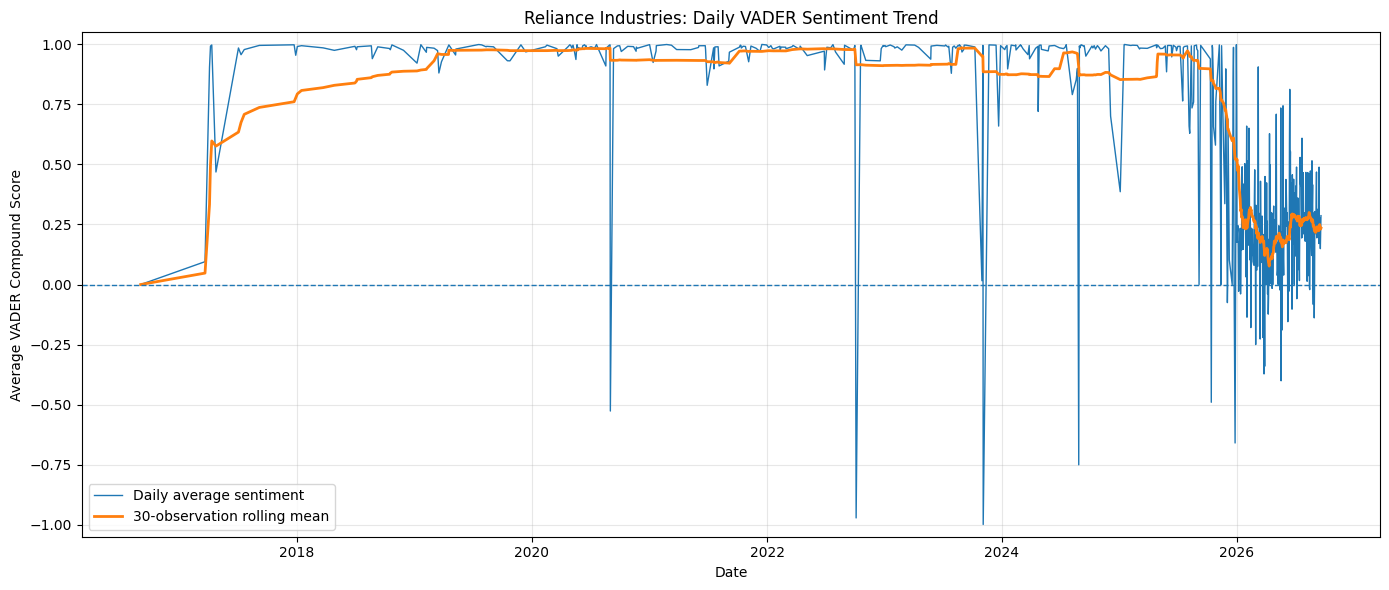

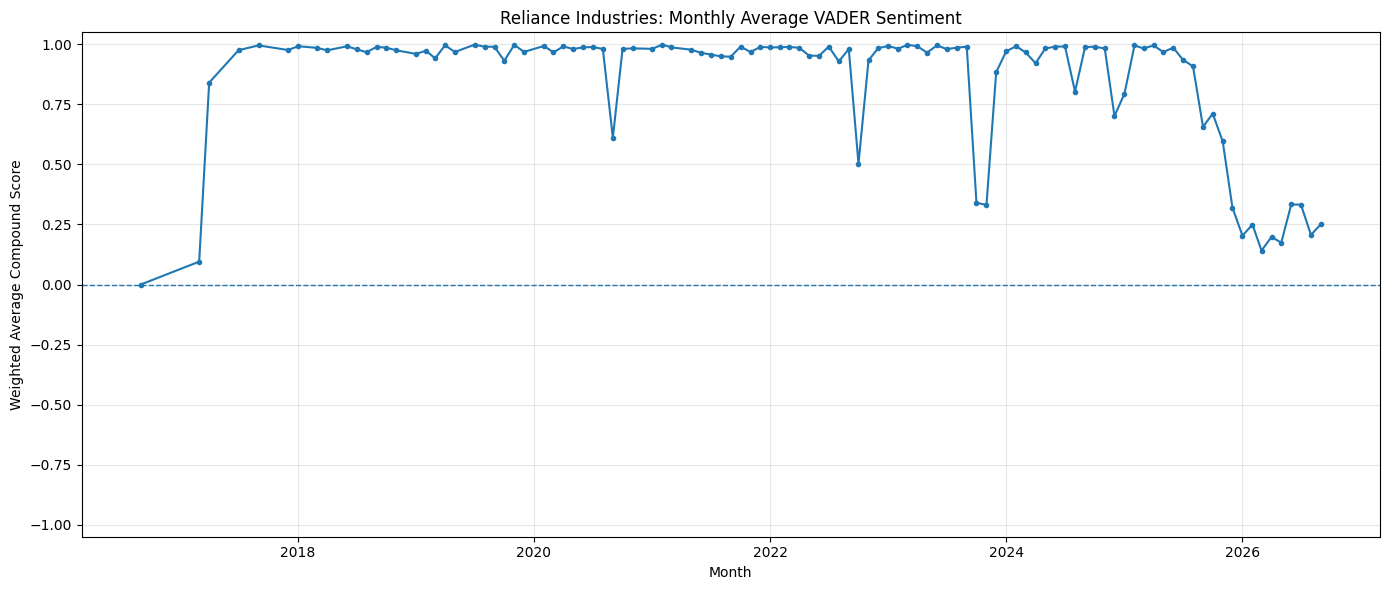

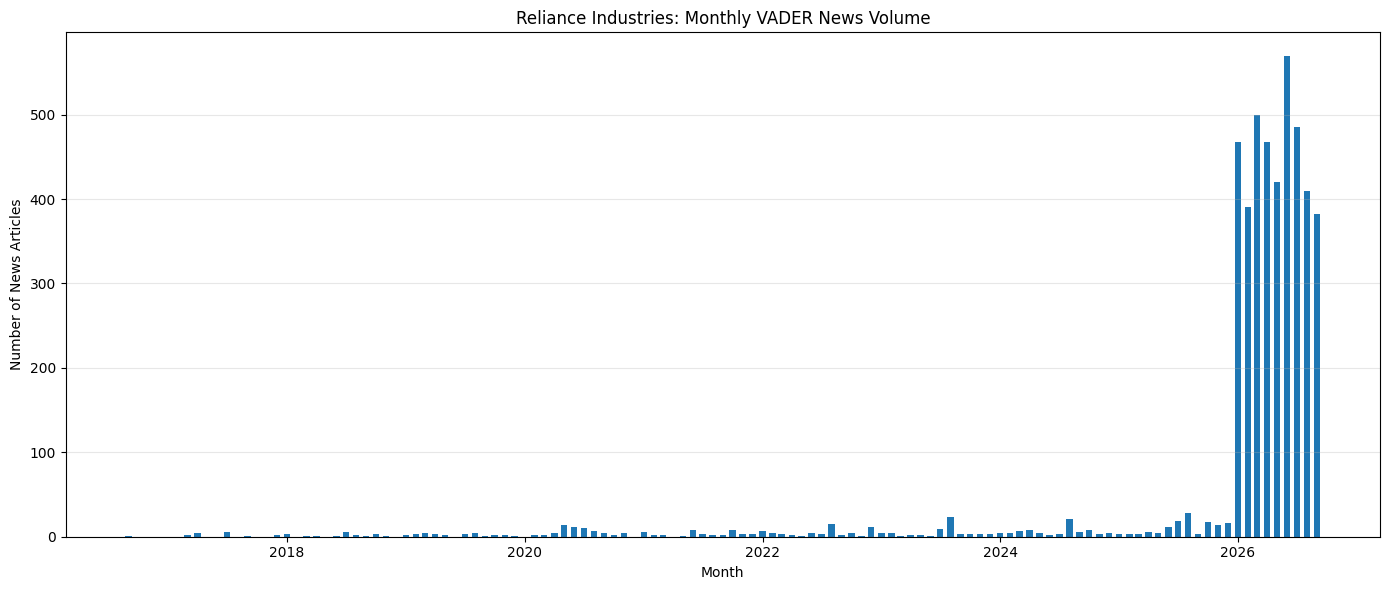

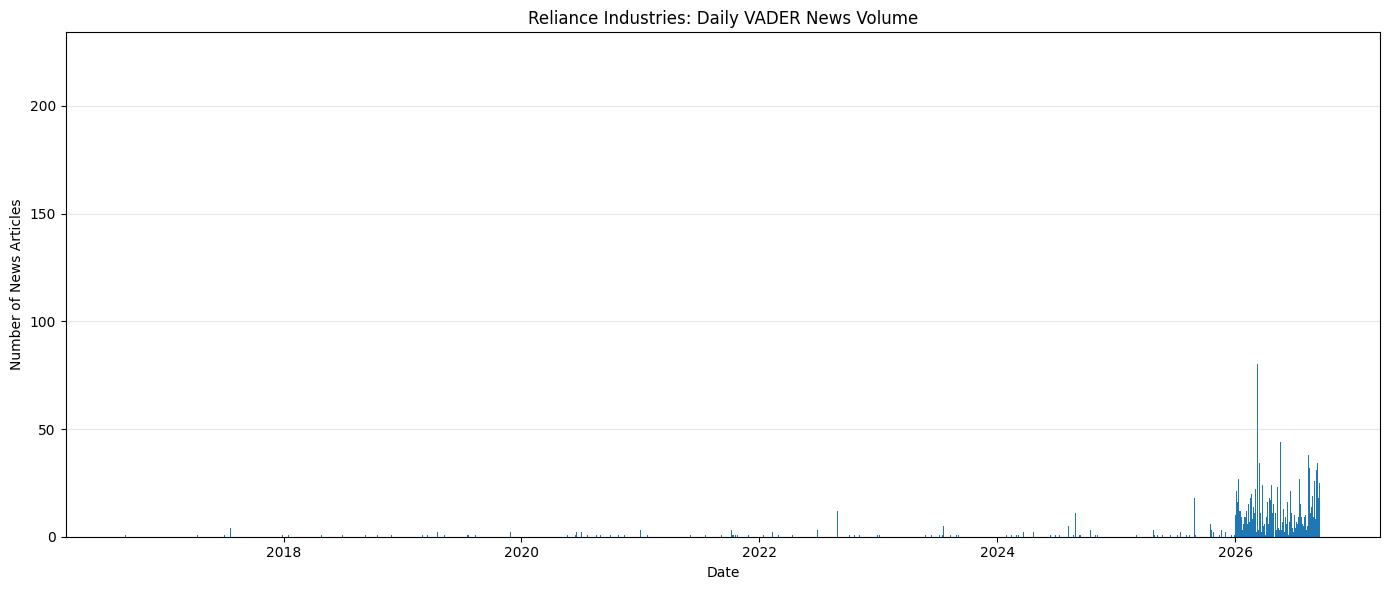


VADER GRAPH GENERATION COMPLETED
Graphs generated: 4
1. Daily sentiment trend
2. Monthly average sentiment
3. Monthly news volume
4. Daily news volume

Output folder:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\sentiment_analysis\graphs\vader

Monthly summary:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\sentiment_analysis\graphs\vader\vader_monthly_summary.csv

No original news or FinBERT files were modified.


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==================================================
# 1. FILE PATHS
# ==================================================
BASE_DIR = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

INPUT_FILE = (
    BASE_DIR / "data" / "processed" / "news"
    / "reliance_vader_daily_sentiment_corrected.csv"
)

GRAPH_DIR = (
    BASE_DIR / "data" / "processed" / "news"
    / "sentiment_analysis" / "graphs" / "vader"
)

GRAPH_DIR.mkdir(parents=True, exist_ok=True)

# ==================================================
# 2. LOAD CORRECTED DAILY DATASET
# ==================================================
df = pd.read_csv(INPUT_FILE, parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True)

required_columns = [
    "Date",
    "Average_VADER_Sentiment",
    "Average_VADER_Positive",
    "Average_VADER_Negative",
    "Average_VADER_Neutral",
    "VADER_News_Count"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

if df.empty:
    raise ValueError("The corrected daily dataset is empty.")

print("Dataset loaded successfully.")
print("Daily records:", len(df))
print("Date range:", df["Date"].min().date(),
      "to", df["Date"].max().date())
print("Graphs will be saved in:", GRAPH_DIR)

# ==================================================
# GRAPH 1: DAILY SENTIMENT TREND
# ==================================================
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Average_VADER_Sentiment"],
    label="Daily average sentiment",
    linewidth=1
)

plt.plot(
    df["Date"],
    df["Average_VADER_Sentiment"].rolling(
        window=30, min_periods=1
    ).mean(),
    label="30-observation rolling mean",
    linewidth=2
)

plt.axhline(y=0, linestyle="--", linewidth=1)
plt.title("Reliance Industries: Daily VADER Sentiment Trend")
plt.xlabel("Date")
plt.ylabel("Average VADER Compound Score")
plt.ylim(-1.05, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "01_daily_vader_sentiment.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==================================================
# 3. CREATE MONTHLY SUMMARY
# Weight sentiment by the number of news articles
# ==================================================
df["Month"] = df["Date"].dt.to_period("M")

df["Weighted_Sentiment"] = (
    df["Average_VADER_Sentiment"] * df["VADER_News_Count"]
)

monthly = (
    df.groupby("Month")
    .agg(
        Weighted_Sentiment_Sum=("Weighted_Sentiment", "sum"),
        News_Count=("VADER_News_Count", "sum")
    )
)

monthly["Average_VADER_Sentiment"] = (
    monthly["Weighted_Sentiment_Sum"] / monthly["News_Count"]
)

monthly = monthly.reset_index()
monthly["Month"] = monthly["Month"].dt.to_timestamp()

# ==================================================
# GRAPH 2: MONTHLY AVERAGE SENTIMENT
# ==================================================
plt.figure(figsize=(14, 6))

plt.plot(
    monthly["Month"],
    monthly["Average_VADER_Sentiment"],
    marker="o",
    markersize=3,
    linewidth=1.5
)

plt.axhline(y=0, linestyle="--", linewidth=1)
plt.title("Reliance Industries: Monthly Average VADER Sentiment")
plt.xlabel("Month")
plt.ylabel("Weighted Average Compound Score")
plt.ylim(-1.05, 1.05)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "02_monthly_vader_sentiment.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==================================================
# GRAPH 3: MONTHLY NEWS VOLUME
# ==================================================
plt.figure(figsize=(14, 6))

plt.bar(
    monthly["Month"],
    monthly["News_Count"],
    width=20
)

plt.title("Reliance Industries: Monthly VADER News Volume")
plt.xlabel("Month")
plt.ylabel("Number of News Articles")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "03_monthly_vader_news_volume.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==================================================
# GRAPH 4: DAILY NEWS VOLUME
# ==================================================
plt.figure(figsize=(14, 6))

plt.bar(
    df["Date"],
    df["VADER_News_Count"],
    width=1
)

plt.title("Reliance Industries: Daily VADER News Volume")
plt.xlabel("Date")
plt.ylabel("Number of News Articles")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "04_daily_vader_news_volume.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==================================================
# 4. SAVE MONTHLY SUMMARY SEPARATELY
# ==================================================
monthly_output = GRAPH_DIR / "vader_monthly_summary.csv"

monthly[
    ["Month", "Average_VADER_Sentiment", "News_Count"]
].to_csv(monthly_output, index=False)

print("\n" + "=" * 55)
print("VADER GRAPH GENERATION COMPLETED")
print("=" * 55)

print("Graphs generated: 4")
print("1. Daily sentiment trend")
print("2. Monthly average sentiment")
print("3. Monthly news volume")
print("4. Daily news volume")

print("\nOutput folder:")
print(GRAPH_DIR)

print("\nMonthly summary:")
print(monthly_output)

print("\nNo original news or FinBERT files were modified.")


News-level records: 4592
Corrected daily records: 571
Graph folder: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\sentiment_analysis\graphs\vader


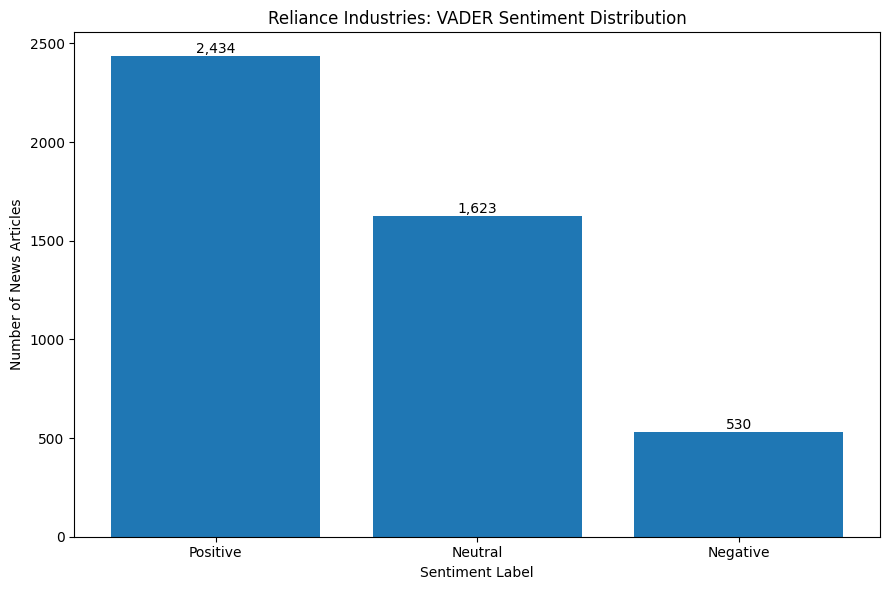

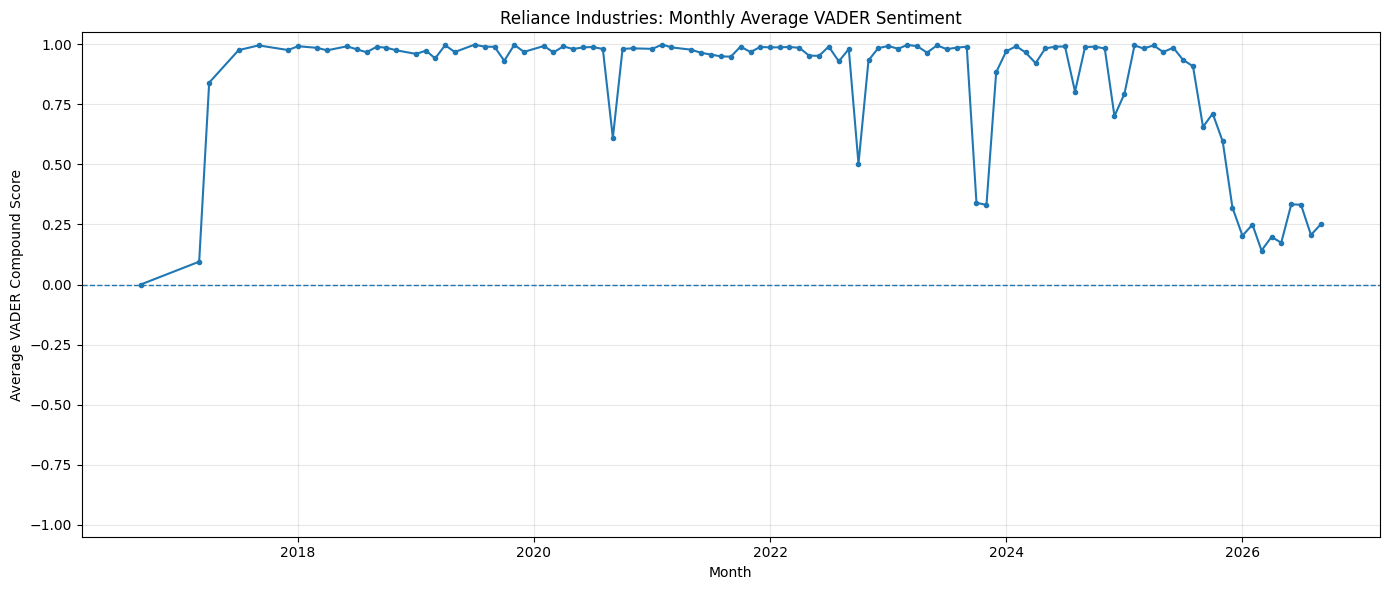

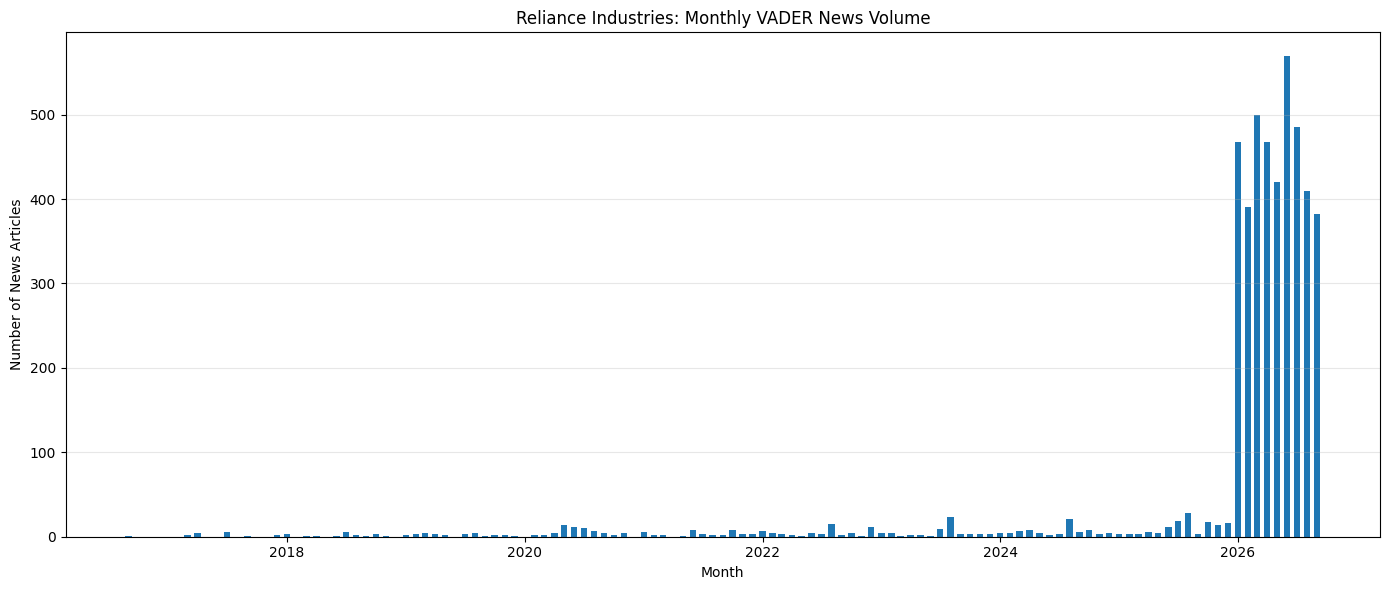

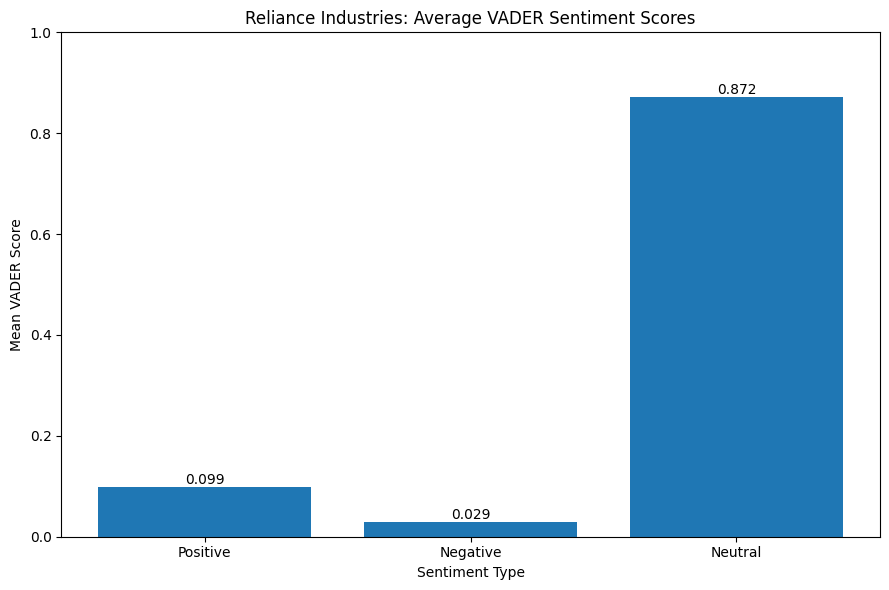

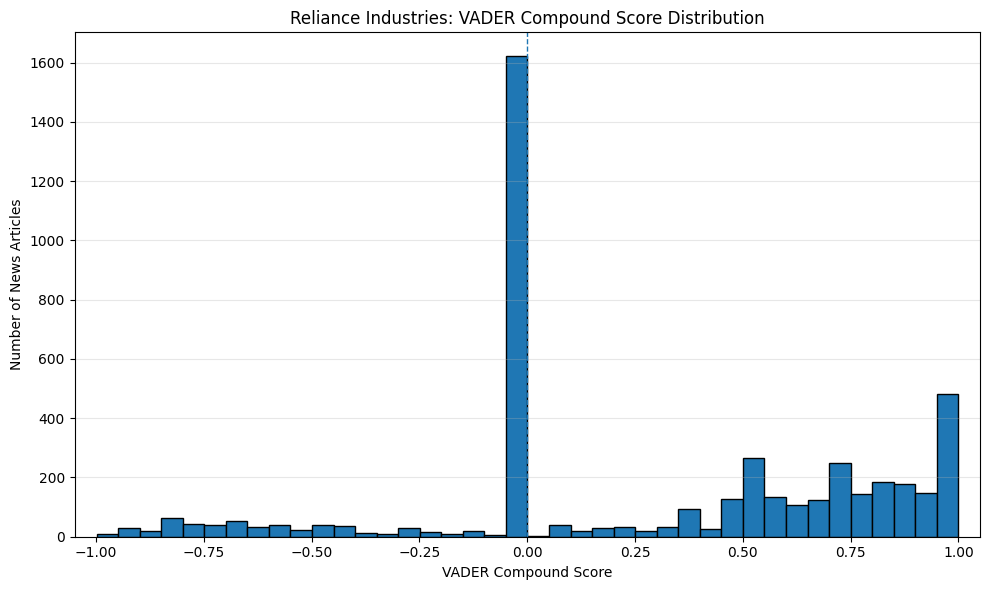


VADER SENTIMENT GRAPHS COMPLETED
1. Sentiment distribution
2. Monthly average sentiment trend
3. Monthly news volume
4. Average positive, negative, neutral scores
5. Compound score distribution

Valid compound scores: 4587
Monthly periods: 104
Total articles in corrected daily data: 4577

Saved files:
01_daily_vader_sentiment.png
01_vader_sentiment_distribution.png
02_monthly_vader_sentiment.png
02_vader_monthly_sentiment_trend.png
03_monthly_vader_news_volume.png
03_vader_monthly_news_volume.png
04_daily_vader_news_volume.png
04_vader_average_sentiment_scores.png
05_vader_compound_score_distribution.png

Output directory:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\sentiment_analysis\graphs\vader

Original news, VADER and FinBERT CSV files were not modified.


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =====================================================
# 1. FILE PATHS
# =====================================================
BASE_DIR = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

NEWS_FILE = (
    BASE_DIR / "data" / "processed" / "news"
    / "reliance_vader_sentiment_results.csv"
)

DAILY_FILE = (
    BASE_DIR / "data" / "processed" / "news"
    / "reliance_vader_daily_sentiment_corrected.csv"
)

GRAPH_DIR = (
    BASE_DIR / "data" / "processed" / "news"
    / "sentiment_analysis" / "graphs" / "vader"
)

GRAPH_DIR.mkdir(parents=True, exist_ok=True)

# =====================================================
# 2. LOAD EXISTING RESULTS (READ ONLY)
# =====================================================
news = pd.read_csv(NEWS_FILE, low_memory=False)
daily = pd.read_csv(DAILY_FILE, parse_dates=["Date"])

daily = daily.sort_values("Date").copy()

# Ensure score columns are numeric
score_columns = [
    "VADER_Positive_Score",
    "VADER_Negative_Score",
    "VADER_Neutral_Score",
    "VADER_Compound_Score"
]

for col in score_columns:
    news[col] = pd.to_numeric(news[col], errors="coerce")

news["Sentiment_Label_Clean"] = (
    news["VADER_Sentiment_Label"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("News-level records:", len(news))
print("Corrected daily records:", len(daily))
print("Graph folder:", GRAPH_DIR)

# =====================================================
# GRAPH 1: SENTIMENT DISTRIBUTION
# =====================================================
label_order = ["positive", "neutral", "negative"]

sentiment_counts = (
    news["Sentiment_Label_Clean"]
    .value_counts()
    .reindex(label_order, fill_value=0)
)

plt.figure(figsize=(9, 6))

bars = plt.bar(
    sentiment_counts.index.str.title(),
    sentiment_counts.values
)

plt.title("Reliance Industries: VADER Sentiment Distribution")
plt.xlabel("Sentiment Label")
plt.ylabel("Number of News Articles")

for bar, value in zip(bars, sentiment_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    GRAPH_DIR / "01_vader_sentiment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# =====================================================
# CREATE MONTHLY SUMMARY FROM CORRECTED DAILY DATA
# =====================================================
daily["Month"] = daily["Date"].dt.to_period("M")

daily["Weighted_Sentiment"] = (
    daily["Average_VADER_Sentiment"]
    * daily["VADER_News_Count"]
)

monthly = (
    daily.groupby("Month")
    .agg(
        Weighted_Sentiment_Sum=("Weighted_Sentiment", "sum"),
        News_Count=("VADER_News_Count", "sum")
    )
)

monthly["Average_VADER_Sentiment"] = (
    monthly["Weighted_Sentiment_Sum"]
    / monthly["News_Count"]
)

monthly = monthly.reset_index()
monthly["Month"] = monthly["Month"].dt.to_timestamp()

# =====================================================
# GRAPH 2: MONTHLY AVERAGE SENTIMENT TREND
# =====================================================
plt.figure(figsize=(14, 6))

plt.plot(
    monthly["Month"],
    monthly["Average_VADER_Sentiment"],
    marker="o",
    markersize=3,
    linewidth=1.5
)

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.title("Reliance Industries: Monthly Average VADER Sentiment")
plt.xlabel("Month")
plt.ylabel("Average VADER Compound Score")
plt.ylim(-1.05, 1.05)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "02_vader_monthly_sentiment_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# =====================================================
# GRAPH 3: MONTHLY NEWS VOLUME
# =====================================================
plt.figure(figsize=(14, 6))

plt.bar(
    monthly["Month"],
    monthly["News_Count"],
    width=20
)

plt.title("Reliance Industries: Monthly VADER News Volume")
plt.xlabel("Month")
plt.ylabel("Number of News Articles")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "03_vader_monthly_news_volume.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# =====================================================
# GRAPH 4: AVERAGE POSITIVE, NEGATIVE, NEUTRAL SCORES
# =====================================================
mean_scores = news[score_columns[:3]].mean()

mean_scores.index = [
    "Positive",
    "Negative",
    "Neutral"
]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    mean_scores.index,
    mean_scores.values
)

plt.title("Reliance Industries: Average VADER Sentiment Scores")
plt.xlabel("Sentiment Type")
plt.ylabel("Mean VADER Score")
plt.ylim(0, 1)

for bar, value in zip(bars, mean_scores.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    GRAPH_DIR / "04_vader_average_sentiment_scores.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# =====================================================
# GRAPH 5: COMPOUND SCORE DISTRIBUTION
# =====================================================
compound_scores = news["VADER_Compound_Score"].dropna()

plt.figure(figsize=(10, 6))

plt.hist(
    compound_scores,
    bins=40,
    edgecolor="black"
)

plt.axvline(x=0, linestyle="--", linewidth=1)

plt.title("Reliance Industries: VADER Compound Score Distribution")
plt.xlabel("VADER Compound Score")
plt.ylabel("Number of News Articles")
plt.xlim(-1.05, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "05_vader_compound_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# =====================================================
# SAVE MONTHLY SUMMARY SEPARATELY
# =====================================================
monthly_output = GRAPH_DIR / "vader_monthly_summary.csv"

monthly[
    ["Month", "Average_VADER_Sentiment", "News_Count"]
].to_csv(monthly_output, index=False)

# =====================================================
# FINAL REPORT
# =====================================================
print("\n" + "=" * 55)
print("VADER SENTIMENT GRAPHS COMPLETED")
print("=" * 55)

print("1. Sentiment distribution")
print("2. Monthly average sentiment trend")
print("3. Monthly news volume")
print("4. Average positive, negative, neutral scores")
print("5. Compound score distribution")

print("\nValid compound scores:", len(compound_scores))
print("Monthly periods:", len(monthly))
print("Total articles in corrected daily data:",
      int(daily["VADER_News_Count"].sum()))

print("\nSaved files:")
for file in sorted(GRAPH_DIR.glob("*.png")):
    print(file.name)

print("\nOutput directory:")
print(GRAPH_DIR)

print("\nOriginal news, VADER and FinBERT CSV files were not modified.")


FINBERT VS VADER: SENTIMENT COMPARISON
          FinBERT  VADER  Difference (VADER - FinBERT)
positive     1085   2434                          1349
negative      531    530                            -1
neutral      2961   1623                         -1338

FinBERT total records: 4592
VADER total records: 4592


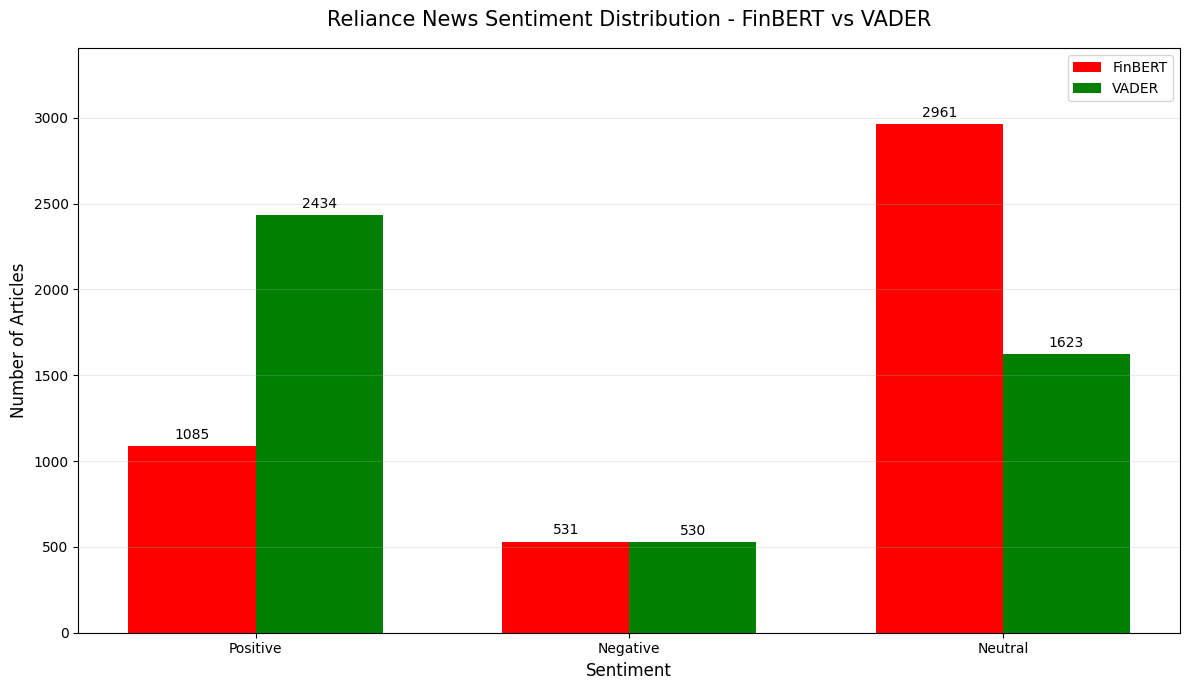


Graph saved at:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\sentiment_analysis\graphs\comparison\finbert_vs_vader_sentiment_comparison.png

Comparison table saved at:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\news\sentiment_analysis\graphs\comparison\finbert_vs_vader_sentiment_counts.csv


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# =====================================================
# 1. FILE PATHS
# =====================================================
BASE_DIR = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

FINBERT_FILE = (
    BASE_DIR / "data" / "processed" / "news"
    / "reliance_finbert_sentiment_results.csv"
)

VADER_FILE = (
    BASE_DIR / "data" / "processed" / "news"
    / "reliance_vader_sentiment_results.csv"
)

OUTPUT_DIR = (
    BASE_DIR / "data" / "processed" / "news"
    / "sentiment_analysis" / "graphs" / "comparison"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# =====================================================
# 2. LOAD BOTH DATASETS
# =====================================================
finbert = pd.read_csv(FINBERT_FILE, low_memory=False)
vader = pd.read_csv(VADER_FILE, low_memory=False)

# Standardize labels
finbert_labels = (
    finbert["Sentiment_Label"]
    .astype("string").str.strip().str.lower()
)

vader_labels = (
    vader["VADER_Sentiment_Label"]
    .astype("string").str.strip().str.lower()
)

label_order = ["positive", "negative", "neutral"]

finbert_counts = (
    finbert_labels.value_counts()
    .reindex(label_order, fill_value=0)
)

vader_counts = (
    vader_labels.value_counts()
    .reindex(label_order, fill_value=0)
)

# =====================================================
# 3. PRINT SENTIMENT COUNTS
# =====================================================
comparison = pd.DataFrame({
    "FinBERT": finbert_counts,
    "VADER": vader_counts
})

comparison["Difference (VADER - FinBERT)"] = (
    comparison["VADER"] - comparison["FinBERT"]
)

print("=" * 60)
print("FINBERT VS VADER: SENTIMENT COMPARISON")
print("=" * 60)
print(comparison)
print("\nFinBERT total records:", len(finbert))
print("VADER total records:", len(vader))

# Save comparison table separately
comparison.to_csv(
    OUTPUT_DIR / "finbert_vs_vader_sentiment_counts.csv"
)

# =====================================================
# 4. GROUPED BAR CHART
# FinBERT = Red | VADER = Green
# =====================================================
categories = ["Positive", "Negative", "Neutral"]
finbert_values = [int(finbert_counts[x]) for x in label_order]
vader_values = [int(vader_counts[x]) for x in label_order]

x = np.arange(len(categories))
width = 0.34

fig, ax = plt.subplots(figsize=(12, 7))

bars1 = ax.bar(
    x - width / 2,
    finbert_values,
    width,
    label="FinBERT",
    color="red"
)

bars2 = ax.bar(
    x + width / 2,
    vader_values,
    width,
    label="VADER",
    color="green"
)

ax.set_title(
    "Reliance News Sentiment Distribution - FinBERT vs VADER",
    fontsize=15,
    pad=16
)
ax.set_xlabel("Sentiment", fontsize=12)
ax.set_ylabel("Number of Articles", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()
ax.grid(axis="y", alpha=0.25)

ax.bar_label(bars1, fmt="%d", padding=3, fontsize=10)
ax.bar_label(bars2, fmt="%d", padding=3, fontsize=10)

ax.set_ylim(
    0,
    max(max(finbert_values), max(vader_values)) * 1.15
)

plt.tight_layout()

graph_path = OUTPUT_DIR / "finbert_vs_vader_sentiment_comparison.png"

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("\nGraph saved at:")
print(graph_path)

print("\nComparison table saved at:")
print(OUTPUT_DIR / "finbert_vs_vader_sentiment_counts.csv")


In [11]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

finbert_file = (
    BASE_DIR / "data" / "processed" / "news"
    / "reliance_finbert_sentiment_results.csv"
)

vader_file = (
    BASE_DIR / "data" / "processed" / "news"
    / "reliance_vader_sentiment_results.csv"
)

finbert = pd.read_csv(finbert_file, low_memory=False)
vader = pd.read_csv(vader_file, low_memory=False)

finbert_counts = (
    finbert["Sentiment_Label"]
    .astype("string").str.strip().str.lower()
    .value_counts()
    .reindex(["positive", "negative", "neutral"], fill_value=0)
)

vader_counts = (
    vader["VADER_Sentiment_Label"]
    .astype("string").str.strip().str.lower()
    .value_counts()
    .reindex(["positive", "negative", "neutral"], fill_value=0)
)

result = pd.DataFrame({
    "FinBERT": finbert_counts,
    "VADER": vader_counts
})

result["Difference (VADER - FinBERT)"] = (
    result["VADER"] - result["FinBERT"]
)

print("FinBERT total rows:", len(finbert))
print("VADER total rows:", len(vader))
print("\nSentiment counts:")
print(result)
print("\nFinBERT missing labels:",
      finbert["Sentiment_Label"].isna().sum())
print("VADER missing labels:",
      vader["VADER_Sentiment_Label"].isna().sum())


FinBERT total rows: 4592
VADER total rows: 4592

Sentiment counts:
          FinBERT  VADER  Difference (VADER - FinBERT)
positive     1085   2434                          1349
negative      531    530                            -1
neutral      2961   1623                         -1338

FinBERT missing labels: 5
VADER missing labels: 0
